In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines
import pickle
from matplotlib.colors import LogNorm

In [3]:
def inter_from_256(x):
    return np.interp(x=x,xp=[0,255],fp=[0,1])

In [4]:
#color pinterest
color1=(inter_from_256(231),inter_from_256(197),inter_from_256(108))
color2=(inter_from_256(189),inter_from_256(108),inter_from_256(78))
color3=(inter_from_256(215),inter_from_256(66),inter_from_256(232))
color4=(inter_from_256(86),inter_from_256(141),inter_from_256(162))

colors=[color1,color2,color3,color4]

In [5]:
import numpy as np
import scipy.stats

def mean_confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), scipy.stats.sem(a)
    h = se * scipy.stats.t.ppf((1 + confidence) / 2., n-1)
    return m, h

In [10]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp','move_count', 'op_change_count', 'component_sizes', 'component_opinion', 'component_homo','homophily']
filename = '/scratch/kolokcse/logs_hypergraph/majority_move_lin_long_final/long_2_regular_edgesize_5_maj_change_lin.pickle'
with open(filename, 'rb') as handle:
        results_dict = pickle.load(handle)

iterations=500


all_res = []
for beta_i, beta in enumerate(betas):
    all_res.append([])
    for q_i,q in enumerate(qs):
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            for i in range(iterations):
                try:
                    results[row].append(results_dict[beta_i][q_i][i][row])
                except:
                    print(beta_i,q_i,i,row)
        all_res[beta_i].append(results)

KeyboardInterrupt: 

In [6]:
len(results_dict)

9

In [7]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)
row_names = ['sum_opinion_A','component_sizes','homophily']
filename = '/scratch/kolokcse/logs_hypergraph/majority_move_nonlin_long_final/long_2_regular_edgesize_5_lambda1_nonlin.pickle'
with open(filename, 'rb') as handle:
        results_dict = pickle.load(handle)

iterations=500


all_res_nonlin = []
for beta_i, beta in enumerate(betas):
    all_res_nonlin.append([])
    for q_i,q in enumerate(qs):
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            for i in range(iterations):
                try:
                    results[row].append(results_dict[beta_i][q_i][i][row])
                except:
                    print(beta_i,q_i,i,row)
        all_res_nonlin[beta_i].append(results)

# Sum of A: N_A

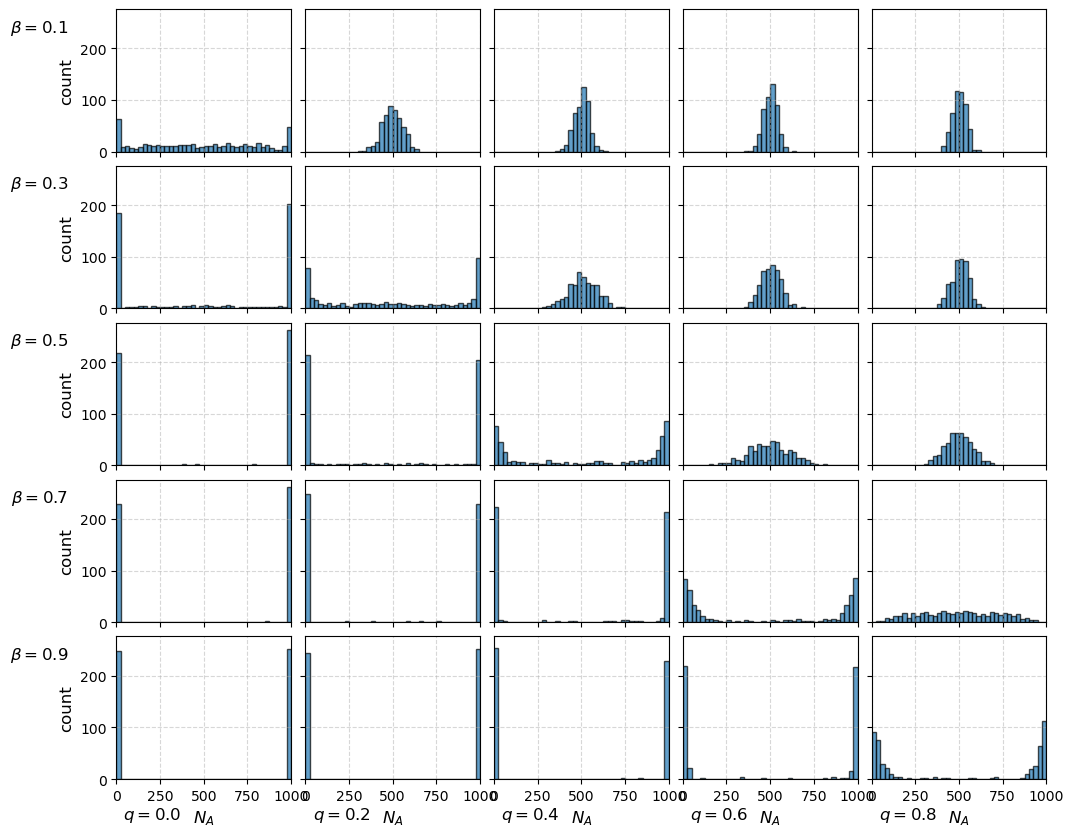

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Setup
fs = 12
ts = 10
n_rows = 5
n_cols = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.08, hspace=0.1)

axes = np.array(axes)
if axes.ndim == 1:
    axes = axes.reshape((n_rows, n_cols))
k = 0
for i in range(0, len(betas), 2):
    beta = betas[i]
    l = 0
    for j in range(0, len(qs), 2):
        q = qs[j]
        ax = axes[k, l]
        results = all_res[i][j]

        final_na = [res[-1] for res in results['sum_opinion_A']]
        ax.hist(final_na, bins=np.arange(0, 1001, 25), color='tab:blue', alpha=0.7, edgecolor='black')
        ax.set_xlim((0, 1000))
        ax.grid(True, linestyle='--', alpha=0.5)

        if j == 0:
            ax.set_ylabel('count', fontsize=fs)
            ax.tick_params(axis='y', labelsize=ts)
        else:
            ax.tick_params(axis='y', labelleft=False)

        if k == n_rows - 1:
            ax.set_xlabel('$N_A$', fontsize=fs)
            ax.tick_params(axis='x', labelsize=ts)
        else:
            ax.tick_params(axis='x', labelbottom=False)
        l += 1
    k += 1

# q labels below each column
k = 0
for j in range(0, len(qs), 2):
    q = qs[j]
    ax = axes[-1, k]
    fig.text(
        ax.get_position().x0 + 0.03,
        ax.get_position().y0 - 0.04,
        rf'$q=${q:.1f}',
        ha='center',
        fontsize=fs,
    )
    k += 1

# beta labels to the left of each row
k = 0
for i in range(0, len(betas), 2):
    beta = betas[i]
    ax = axes[k, 0]
    fig.text(
        ax.get_position().x0 - 0.04,
        ax.get_position().y0 + 0.12,
        rf'$\beta=${beta:.1f}',
        ha='right',
        fontsize=fs,
    )
    k += 1
plt.savefig('figures/sum_of_A_lin.pdf', bbox_inches='tight')
plt.show()


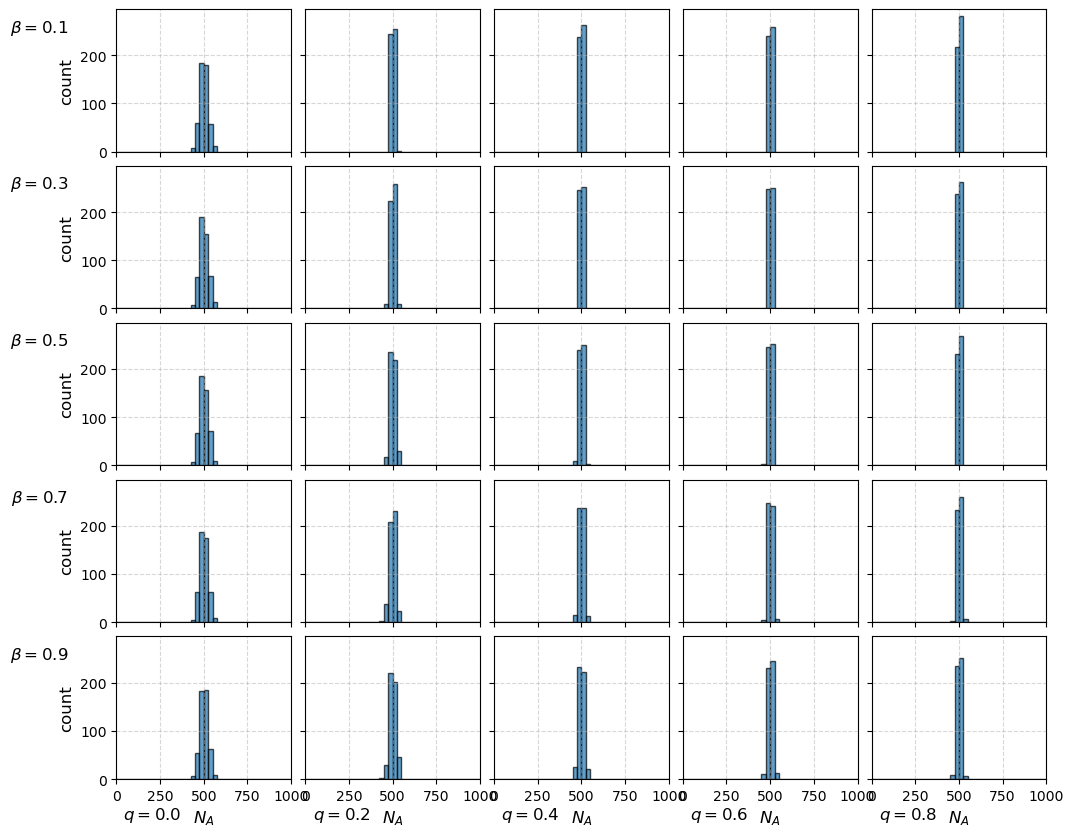

In [15]:

# Setup
fs = 12
ts = 10
n_rows = 5
n_cols = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.08, hspace=0.1)

axes = np.array(axes)
if axes.ndim == 1:
    axes = axes.reshape((n_rows, n_cols))
k = 0
for i in range(0, len(betas), 2):
    beta = betas[i]
    l = 0
    for j in range(0, len(qs), 2):
        q = qs[j]
        ax = axes[k, l]
        results = all_res_nonlin[i][j]

        final_na = [res[-1] for res in results['sum_opinion_A']]
        ax.hist(final_na, bins=np.arange(0, 1001, 25), color='tab:blue', alpha=0.7, edgecolor='black')
        ax.set_xlim((0, 1000))
        ax.grid(True, linestyle='--', alpha=0.5)

        if j == 0:
            ax.set_ylabel('count', fontsize=fs)
            ax.tick_params(axis='y', labelsize=ts)
        else:
            ax.tick_params(axis='y', labelleft=False)

        if k == n_rows - 1:
            ax.set_xlabel('$N_A$', fontsize=fs)
            ax.tick_params(axis='x', labelsize=ts)
        else:
            ax.tick_params(axis='x', labelbottom=False)
        l += 1
    k += 1

# q labels below each column
k = 0
for j in range(0, len(qs), 2):
    q = qs[j]
    ax = axes[-1, k]
    fig.text(
        ax.get_position().x0 + 0.03,
        ax.get_position().y0 - 0.04,
        rf'$q=${q:.1f}',
        ha='center',
        fontsize=fs,
    )
    k += 1

# beta labels to the left of each row
k = 0
for i in range(0, len(betas), 2):
    beta = betas[i]
    ax = axes[k, 0]
    fig.text(
        ax.get_position().x0 - 0.04,
        ax.get_position().y0 + 0.12,
        rf'$\beta=${beta:.1f}',
        ha='right',
        fontsize=fs,
    )
    k += 1
plt.savefig('figures/sum_of_A_lin.pdf', bbox_inches='tight')
plt.show()


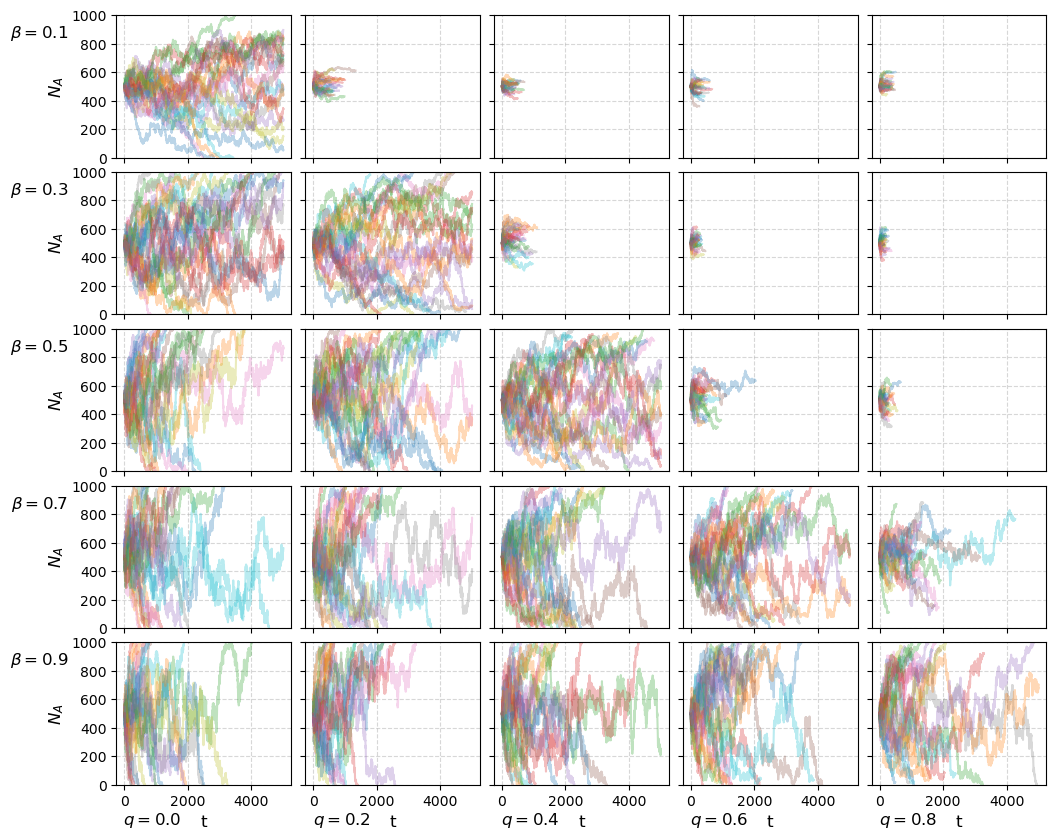

In [17]:

# Setup
fs = 12
ts = 10
n_rows = 5
n_cols = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.08, hspace=0.1)

axes = np.array(axes)
if axes.ndim == 1:
    axes = axes.reshape((n_rows, n_cols))
k=0
for i  in range(0,len(betas),2):
    beta=betas[i]
    l=0
    for j in range(0,len(qs),2):
        q=qs[j]
        ax = axes[k, l]
        results = all_res[i][j]
        stat =[]
        for it in range(25):
            ax.plot(results['sum_opinion_A'][it], alpha=0.3)

        ax.set_ylim((0, 1000))
        ax.grid(True, linestyle='--', alpha=0.5)

        # y-axis ticks only on first column
        if j == 0:
            ax.set_ylabel('$N_A$', fontsize=fs)
            ax.tick_params(axis='y', labelsize=ts)
        else:
            ax.tick_params(axis='y', labelleft=False)

        # x-axis ticks only on last row
        if k == n_rows - 1:
            ax.set_xlabel('t', fontsize=fs)
            ax.tick_params(axis='x', labelsize=ts)
        else:
            ax.tick_params(axis='x', labelbottom=False)
        l+=1
    k+=1
# q labels below each column
k=0
for j in range(0,len(qs),2):
    q=qs[j]
    ax = axes[-1, k]
    fig.text(
        ax.get_position().x0 + 0.03,
        ax.get_position().y0 - 0.04,
        rf'$q=${q:.1f}',
        ha='center',
        fontsize=fs,
    )
    k+=1

# beta labels to the left of each row
k=0
for i  in range(0,len(betas),2):
    beta=betas[i]
    ax = axes[k, 0]
    fig.text(
        ax.get_position().x0 - 0.04,
        ax.get_position().y0 + 0.12,
        rf'$\beta=${beta:.1f}',
        ha='right',
        fontsize=fs,
    )
    k+=1
plt.savefig('figures/sum_of_A_lin.pdf', bbox_inches='tight')
plt.show()


In [18]:
all_res[i][j].keys()

dict_keys(['sum_opinion_A', 'binned_opinions_home', 'binned_opinions_wp', 'binned_edge_sizes_wp', 'move_count', 'op_change_count', 'component_sizes', 'component_opinion', 'component_homo', 'homophily'])

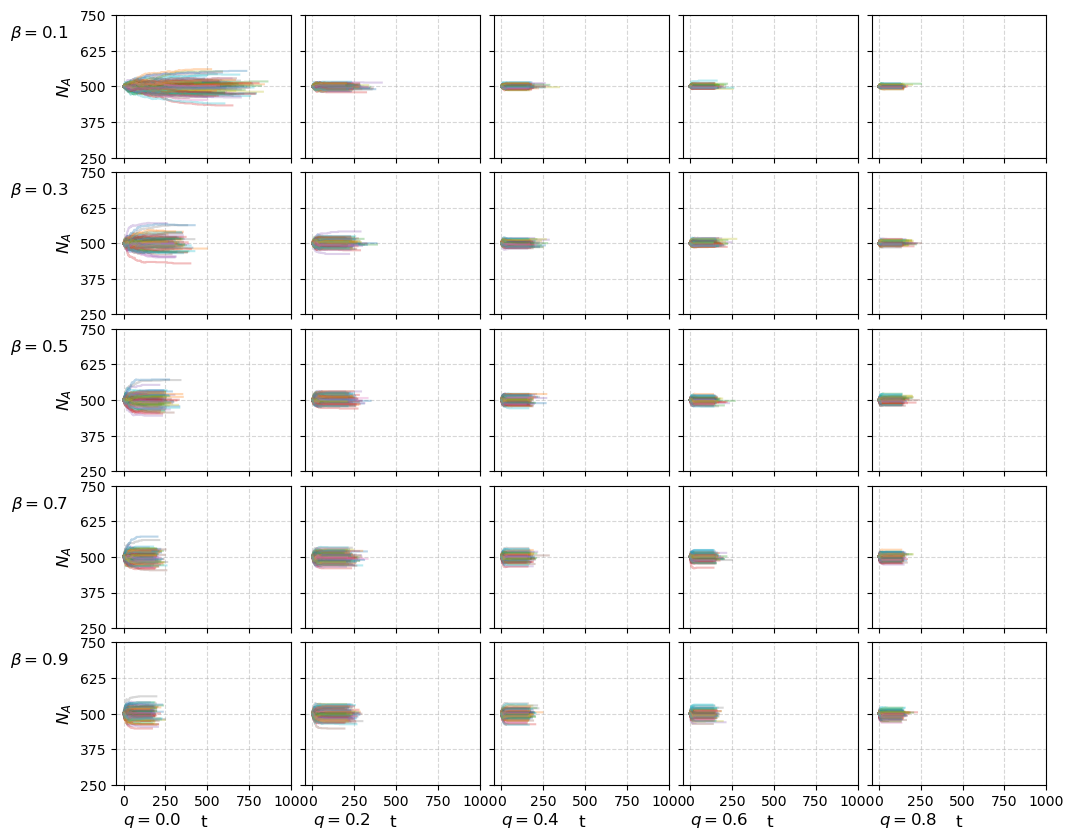

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Setup
fs = 12
ts = 10
n_rows = 5
n_cols = 5

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 10), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.08, hspace=0.1)

axes = np.array(axes)
if axes.ndim == 1:
    axes = axes.reshape((n_rows, n_cols))
k=0
for i  in range(0,len(betas),2):
    beta=betas[i]
    l=0
    for j in range(0,len(qs),2):
        q=qs[j]
        ax = axes[k, l]
        results = all_res_nonlin[i][j]

        for it in range(100):
            ax.plot(results['sum_opinion_A'][it][:1000], alpha=0.3)

        ax.set_ylim((250, 750))
        ax.grid(True, linestyle='--', alpha=0.5)

        # y-axis ticks only on first column
        if j == 0:
            ax.set_ylabel('$N_A$', fontsize=fs)
            ax.set_yticks([ 250, 375,  500, 625, 750])
            ax.tick_params(axis='y', labelsize=ts)
        else:
            ax.tick_params(axis='y', labelleft=False)

        # x-axis ticks only on last row
        if k == n_rows - 1:
            ax.set_xlabel('t', fontsize=fs)
            ax.set_xticks([0, 250, 500, 750,1000])
            ax.tick_params(axis='x', labelsize=ts)
        else:
            ax.tick_params(axis='x', labelbottom=False)
        l+=1
    k+=1
# q labels below each column
k=0
for j in range(0,len(qs),2):
    q=qs[j]
    ax = axes[-1, k]
    fig.text(
        ax.get_position().x0 + 0.03,
        ax.get_position().y0 - 0.04,
        rf'$q=${q:.1f}',
        ha='center',
        fontsize=fs,
    )
    k+=1

# beta labels to the left of each row
k=0
for i  in range(0,len(betas),2):
    beta=betas[i]
    ax = axes[k, 0]
    fig.text(
        ax.get_position().x0 - 0.04,
        ax.get_position().y0 + 0.12,
        rf'$\beta=${beta:.1f}',
        ha='right',
        fontsize=fs,
    )
    k+=1
plt.savefig('figures/sum_of_A_nonlin.pdf', bbox_inches='tight')
plt.show()


# Global analysis

STD

In [10]:
from matplotlib.cm import get_cmap

# Define number of colors
num_bs = len(betas)

# Get `num_qs` shades from the 'Greens' colormap, avoiding the very lightest and darkest ends
greens = get_cmap('Greens')
green_colors = [greens(i) for i in np.linspace(0.3, 0.9, num_bs)]

blues = get_cmap('Blues')
blue_colors = [blues(i) for i in np.linspace(0.3, 0.9, num_bs)]

In [11]:
from matplotlib.cm import get_cmap

# Define number of colors
num_bs = len(betas)

# Get `num_qs` shades from the 'Greens' colormap, avoiding the very lightest and darkest ends
oranges = get_cmap('Oranges')
oranges_colors = [oranges(i) for i in np.linspace(0.3, 0.9, num_bs)]

purples = get_cmap('Purples')
purples_colors = [purples(i) for i in np.linspace(0.3, 0.9, num_bs)]

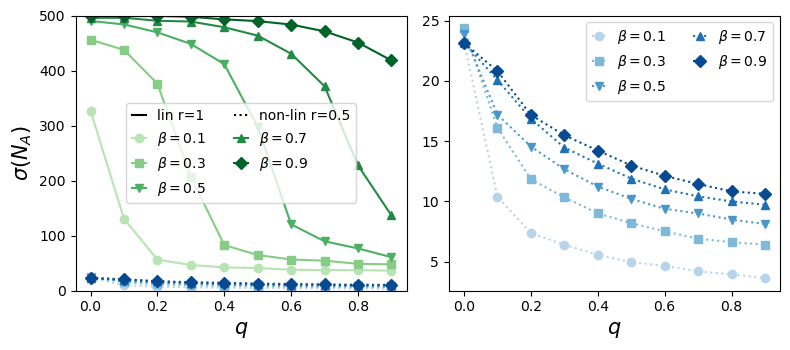

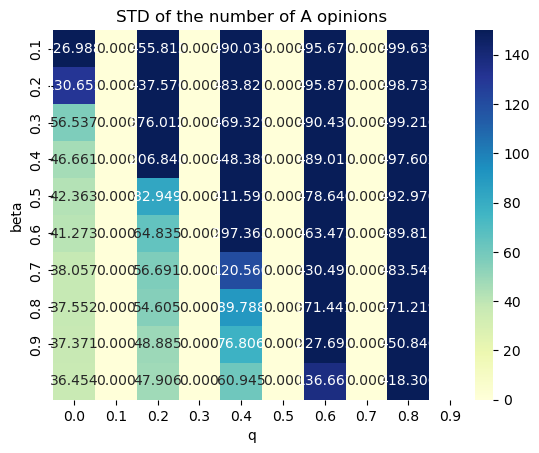

In [12]:
markers = ['o', 's', 'v', '^', 'D'] 
mtx=np.zeros((len(qs),len(betas)))
k=0
fig,axs = plt.subplots(1,2 ,figsize=(8,3.6))
for j in range(0,len(betas),2):
    x1=[]
    x2=[]
    for i in range(0,len(qs)):
        results=all_res[j][i]
        s = np.std([results['sum_opinion_A'][it][-1] for it in range(iterations)])
        x1.append(s)
        mtx[i][j]=s
        results=all_res_nonlin[j][i]
        s = np.std([results['sum_opinion_A'][it][-1] for it in range(iterations)])
        x2.append(s)
    axs[0].plot(qs,x1,label=rf'$\beta={betas[j]:.1f}$ lin',marker=markers[k], color=green_colors[j])
    axs[0].plot(qs,x2,label=rf'$\beta={betas[j]:.1f}$ nonlin',marker=markers[k], color=blue_colors[j], ls='dotted')
    axs[1].plot(qs,x2,label=rf'$\beta={betas[j]:.1f}$ nonlin',marker=markers[k], color=blue_colors[j], ls='dotted')
    k+=1
axs[0].set_xlabel(r'$q$', fontsize=15)
axs[1].set_xlabel(r'$q$', fontsize=15)
axs[0].set_ylabel(r'$\sigma(N_A)$', fontsize=15)
axs[0].set_ylim(0,500)

hs=[]
line = mlines.Line2D([], [], color='k', label=r'lin r=1')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[0],marker=markers[0], label=rf'$\beta={betas[0]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[2],marker=markers[1], label=rf'$\beta={betas[2]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[4],marker=markers[2], label=rf'$\beta={betas[4]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color='k',linestyle='dotted', label=r'non-lin r=0.5')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[6],marker=markers[3], label=rf'$\beta={betas[6]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[8],marker=markers[4], label=rf'$\beta={betas[8]:.1f}$')
hs.append(line)

axs[0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=blue_colors[0],marker=markers[0],linestyle='dotted', label=rf'$\beta={betas[0]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=blue_colors[2],marker=markers[1],linestyle='dotted', label=rf'$\beta={betas[2]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=blue_colors[4],marker=markers[2],linestyle='dotted', label=rf'$\beta={betas[4]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=blue_colors[6],marker=markers[3],linestyle='dotted', label=rf'$\beta={betas[6]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=blue_colors[8],marker=markers[4],linestyle='dotted', label=rf'$\beta={betas[8]:.1f}$')
hs.append(line)

axs[1].legend(handles=hs,handlelength=1,ncol=2)


plt.tight_layout()
plt.savefig('figures/std.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=150)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of the number of A opinions")
plt.show()

In [13]:
len(all_res[8][0]['homophily'][200])

1646

In [14]:
axs

array([<AxesSubplot:xlabel='$q$', ylabel='$\\sigma(N_A)$'>,
       <AxesSubplot:xlabel='$q$'>], dtype=object)

-2


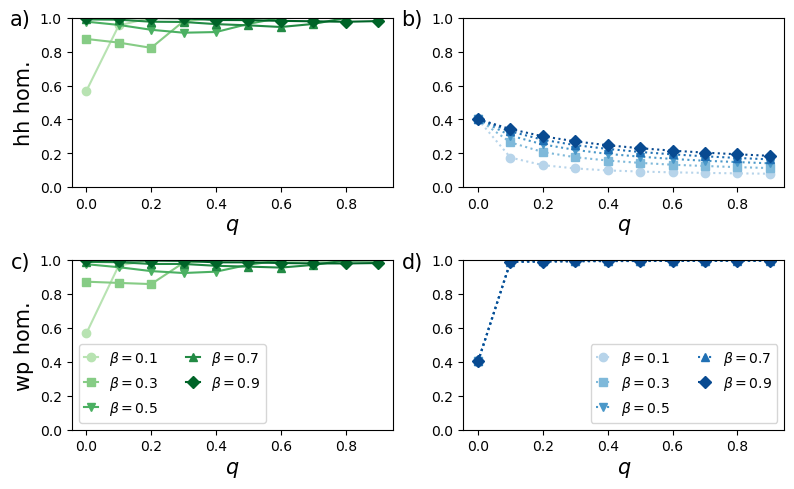

In [15]:
markers = ['o', 's', 'v', '^', 'D'] 
mtx=np.zeros((len(betas),len(qs)))
viztime=[10,50,100,110,120,130,140, 150,151,152,153,154,155,156,157,158,159,160,170,180,190,200,300,400, -2]
viztime=[-2]
for time in viztime:
    k=0
    print(time)
    fig,axs = plt.subplots(2,2,figsize=(8,5))
    for j in range(0,len(betas),2):
        x1=[]
        x2=[]
        for i in range(0,len(qs)):
            results=all_res[j][i]
            s = np.mean([results['homophily'][it][min(len(results['homophily'][it])-2,time)][0] for it in range(iterations)])
            x1.append(s)
            mtx[j][i]=s
            results=all_res_nonlin[j][i]
            s = np.mean([results['homophily'][it][min(len(results['homophily'][it])-2,time)][0] for it in range(iterations)])

            x2.append(s)
        axs[0][0].plot(qs,x1,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=green_colors[j])
        axs[0][1].plot(qs,x2,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=blue_colors[j], ls='dotted')
        k+=1
    axs[0][0].set_xlabel(r'$q$', fontsize=15)
    axs[0][1].set_xlabel(r'$q$', fontsize=15)
    axs[0][0].set_ylabel(r'hh hom.', fontsize=15)
    axs[0][0].set_ylim(0,1)
    axs[0][1].set_ylim(0,1)

    mtx=np.zeros((len(betas),len(qs)))
    k=0
    for j in range(0,len(betas),2):
        x1=[]
        x2=[]
        for i in range(0,len(qs)):
            results=all_res[j][i]
            s = np.mean([results['homophily'][it][min(len(results['homophily'][it])-2,time)][1] for it in range(iterations)])


            x1.append(s)
            mtx[j][i]=s
            results=all_res_nonlin[j][i]
            s = np.mean([results['homophily'][it][min(len(results['homophily'][it])-2,time)][1] for it in range(iterations)])

            x2.append(s)
        axs[1][0].plot(qs,x1,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=green_colors[j])
        axs[1][1].plot(qs,x2,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=blue_colors[j], ls='dotted')
        k+=1
    axs[1][0].set_xlabel(r'$q$', fontsize=15)
    axs[1][1].set_xlabel(r'$q$', fontsize=15)
    axs[1][0].set_ylabel(r'wp hom.', fontsize=15)
    axs[1][0].set_ylim(0,1)
    axs[1][1].set_ylim(0,1)

    hs=[]
    line = mlines.Line2D([], [], color=green_colors[0],marker=markers[0], label=rf'$\beta={betas[0]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[2],marker=markers[1], label=rf'$\beta={betas[2]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[4],marker=markers[2], label=rf'$\beta={betas[4]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[6],marker=markers[3], label=rf'$\beta={betas[6]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[8],marker=markers[4], label=rf'$\beta={betas[8]:.1f}$')
    hs.append(line)

    axs[1][0].legend(handles=hs,handlelength=1,ncol=2)

    hs=[]

    line = mlines.Line2D([], [], color=blue_colors[0],marker=markers[0],linestyle='dotted', label=rf'$\beta={betas[0]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[2],marker=markers[1],linestyle='dotted', label=rf'$\beta={betas[2]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[4],marker=markers[2],linestyle='dotted', label=rf'$\beta={betas[4]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[6],marker=markers[3],linestyle='dotted', label=rf'$\beta={betas[6]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[8],marker=markers[4],linestyle='dotted', label=rf'$\beta={betas[8]:.1f}$')
    hs.append(line)

    axs[1][1].legend(handles=hs,handlelength=1,ncol=2, loc='lower right')

    axs[0][0].text(-0.16, 1.05, 'a)', transform=axs[0][0].transAxes,ha='center' ,va='top',fontsize=15)
    axs[0][1].text(-0.16, 1.05, 'b)', transform=axs[0][1].transAxes,ha='center', va='top',fontsize=15)
    axs[1][0].text(-0.16, 1.05, 'c)', transform=axs[1][0].transAxes,ha='center', va='top',fontsize=15)
    axs[1][1].text(-0.16, 1.05, 'd)', transform=axs[1][1].transAxes,ha='center', va='top',fontsize=15)

    plt.tight_layout()
    plt.savefig('figures/hom_index.pdf')
    plt.show()

In [390]:
[results['homophily'][it][i][0] for i in range(len(results['homophily'][it]))]

[0.06,
 0.175,
 0.325,
 0.395,
 0.415,
 0.365,
 0.36,
 0.4,
 0.405,
 0.385,
 0.4,
 0.39,
 0.42,
 0.435,
 0.5,
 0.485,
 0.435,
 0.44,
 0.385,
 0.41,
 0.38,
 0.405,
 0.38,
 0.355,
 0.355,
 0.4,
 0.41,
 0.37,
 0.425,
 0.46,
 0.455,
 0.465,
 0.43,
 0.43,
 0.415,
 0.48,
 0.47,
 0.495,
 0.47,
 0.465,
 0.5,
 0.45,
 0.44,
 0.44,
 0.475,
 0.42,
 0.455,
 0.49,
 0.465,
 0.5,
 0.515,
 0.51,
 0.505,
 0.485,
 0.545,
 0.47,
 0.5,
 0.44,
 0.45,
 0.425,
 0.435,
 0.505,
 0.48,
 0.465,
 0.45,
 0.515,
 0.49,
 0.48,
 0.5,
 0.46,
 0.425,
 0.445,
 0.51,
 0.52,
 0.495,
 0.475,
 0.495,
 0.5,
 0.475,
 0.455,
 0.475,
 0.5,
 0.495,
 0.545,
 0.5,
 0.52,
 0.505,
 0.51,
 0.505,
 0.505,
 0.52,
 0.535,
 0.555,
 0.55,
 0.56,
 0.5,
 0.51,
 0.525,
 0.515,
 0.52,
 0.515,
 0.505,
 0.48,
 0.53,
 0.525,
 0.58,
 0.595,
 0.555,
 0.485,
 0.525,
 0.46,
 0.42,
 0.42,
 0.49,
 0.465,
 0.44,
 0.435,
 0.445,
 0.45,
 0.495,
 0.475,
 0.485,
 0.52,
 0.495,
 0.505,
 0.47,
 0.495,
 0.495,
 0.515,
 0.5,
 0.56,
 0.575,
 0.545,
 0.53,
 0.605

In [54]:
data_home ="data/majority_move2/"

In [59]:
all_res2[0][0].keys()

dict_keys(['sum_opinion_A', 'binned_opinions_home', 'binned_opinions_wp', 'binned_edge_sizes_wp', 'move_count', 'op_change_count'])

In [359]:
1

1

In [361]:
op_ch_count_mtx=np.zeros((len(betas),len(qs)))
for i, beta in enumerate(betas):
    for j, q in enumerate(qs):
        results = all_res[i][j]
        op_ch_count_mtx[i][j]=np.sum(np.mean([results['op_change_count'][it] for it in range(len(results['op_change_count']))], axis=0))/1000

In [372]:
len(results['op_change_count'][0])

104

Egy ember átlagosan hányszor változtat véleményt a 1000000 lépés alatt, beta-tól és q-tól függően

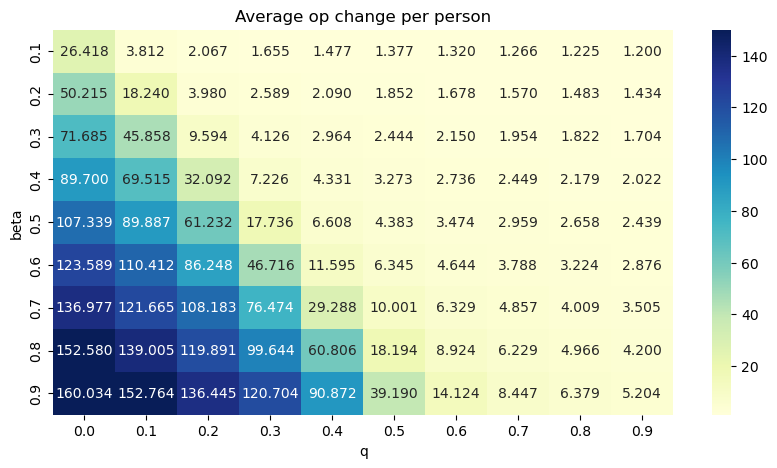

In [368]:
x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
plt.figure(figsize=(10,5))
sns.heatmap(op_ch_count_mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=150)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("Average op change per person")
plt.show()

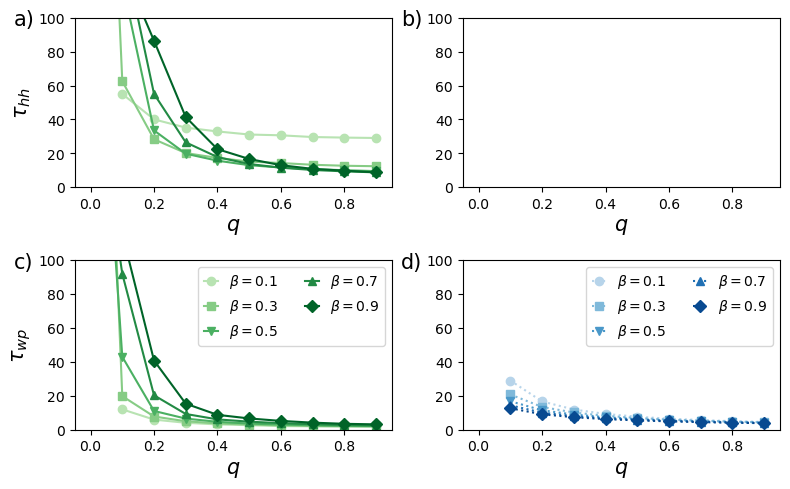

/scratch/kolokcse/anaconda3/lib/python3.9/site-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


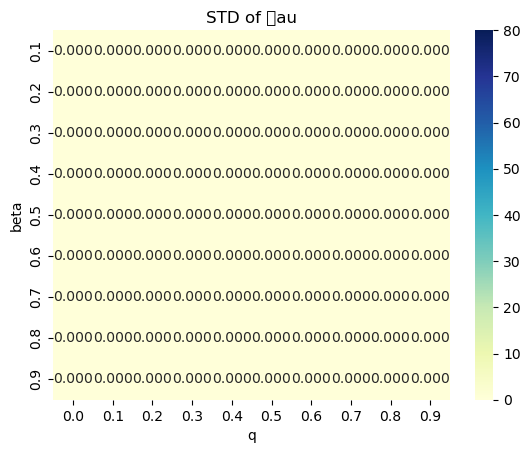

In [16]:
markers = ['o', 's', 'v', '^', 'D'] 
mtx=np.zeros((len(qs),len(betas)))
k=0
epsilon=0.3

fig,axs = plt.subplots(2,2,figsize=(8,5))
for j in range(0,len(betas),2):
    x1=[]
    x2=[]
    for i in range(0,len(qs)):
        results=all_res[j][i]
        epsilon=0.4

        try:
            s = np.mean([np.where(np.array([results['homophily'][it][step][0] for step in range(len(results['homophily'][it]))])>epsilon)[0][0] for it in range(iterations)])
        except:
            s = np.nan
        x1.append(s)
        #mtx[j][i]=s
        epsilon=0.4
        results=all_res_nonlin[j][i]
        try:
            s = np.mean([np.where(np.array([results['homophily'][it][step][0] for step in range(len(results['homophily'][it]))])>epsilon)[0][0] for it in range(iterations)])
        except:
            s = np.nan
        x2.append(s)
    axs[0][0].plot(qs,x1,label=f'q={qs[j]:.1f}',marker=markers[k], color=green_colors[j])
    axs[0][1].plot(qs,x2,label=f'q={qs[j]:.1f}',marker=markers[k], color=blue_colors[j], ls='dotted')
    k+=1

axs[0][0].set_xlabel(r'$q$', fontsize=15)
axs[0][1].set_xlabel(r'$q$', fontsize=15)
axs[0][0].set_ylabel(r'$\tau_{hh}$', fontsize=15)


mtx=np.zeros((len(betas),len(qs)))
k=0
for j in range(0,len(betas),2):
    x1=[]
    x2=[]
    for i in range(0,len(qs)):
        epsilon=0.4
        results=all_res[j][i]
        try:
            s = np.mean([np.where(np.array([results['homophily'][it][step][1] for step in range(len(results['homophily'][it]))])>epsilon)[0][0] for it in range(iterations)])
        except:
            s = np.nan
        x1.append(s)
        #mtx[j][i]=s
        results=all_res_nonlin[j][i]
        try:
            s = np.mean([np.where(np.array([results['homophily'][it][step][1] for step in range(len(results['homophily'][it]))])>epsilon)[0][0] for it in range(iterations)])

        except:
            s = np.nan
        x2.append(s)
    axs[1][0].plot(qs,x1,label=f'q={qs[j]:.1f}',marker=markers[k], color=green_colors[j])
    axs[1][1].plot(qs,x2,label=f'q={qs[j]:.1f}',marker=markers[k], color=blue_colors[j], ls='dotted')
    k+=1

axs[1][0].set_xlabel(r'$q$', fontsize=15)
axs[1][1].set_xlabel(r'$q$', fontsize=15)
axs[1][0].set_ylabel(r'$\tau_{wp}$', fontsize=15)


hs=[]
line = mlines.Line2D([], [], color=green_colors[0],marker=markers[0], label=rf'$\beta={betas[0]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[2],marker=markers[1], label=rf'$\beta={betas[2]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[4],marker=markers[2], label=rf'$\beta={betas[4]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[6],marker=markers[3], label=rf'$\beta={betas[6]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=green_colors[8],marker=markers[4], label=rf'$\beta={betas[8]:.1f}$')
hs.append(line)

axs[1][0].legend(handles=hs,handlelength=1,ncol=2)
   
hs=[]

line = mlines.Line2D([], [], color=blue_colors[0],marker=markers[0],linestyle='dotted', label=rf'$\beta={betas[0]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=blue_colors[2],marker=markers[1],linestyle='dotted', label=rf'$\beta={betas[2]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=blue_colors[4],marker=markers[2],linestyle='dotted', label=rf'$\beta={betas[4]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=blue_colors[6],marker=markers[3],linestyle='dotted', label=rf'$\beta={betas[6]:.1f}$')
hs.append(line)
line = mlines.Line2D([], [], color=blue_colors[8],marker=markers[4],linestyle='dotted', label=rf'$\beta={betas[8]:.1f}$')
hs.append(line)

axs[1][1].legend(handles=hs,handlelength=1,ncol=2)


axs[0][0].set_ylim(0,100)
axs[0][1].set_ylim(0,100)

axs[1][0].set_ylim(0,100)
axs[1][1].set_ylim(0,100)

axs[0][0].set_xlim(-0.05,0.95)
axs[0][1].set_xlim(-0.05,0.95)
axs[1][0].set_xlim(-0.05,0.95)
axs[1][1].set_xlim(-0.05,0.95)
axs[0][0].text(-0.16, 1.05, 'a)', transform=axs[0][0].transAxes,ha='center' ,va='top',fontsize=15)
axs[0][1].text(-0.16, 1.05, 'b)', transform=axs[0][1].transAxes,ha='center', va='top',fontsize=15)
axs[1][0].text(-0.16, 1.05, 'c)', transform=axs[1][0].transAxes,ha='center', va='top',fontsize=15)
axs[1][1].text(-0.16, 1.05, 'd)', transform=axs[1][1].transAxes,ha='center', va='top',fontsize=15)


plt.tight_layout()
plt.savefig('figures/hom_time.pdf')
plt.show()



x = [f'{q:.1f}' for q in qs]
y = [f'{beta:.1f}' for beta in betas]
sns.heatmap(mtx,xticklabels=x, yticklabels=y, cmap="YlGnBu", cbar=True,annot=True, fmt='.3f', vmax=80)

plt.xlabel("q")
plt.ylabel("beta")
plt.title("STD of \tau")
plt.show()

# Components

In [15]:
def component_sizes(all_resulsts,row='component_sizes', color_i=0, typeofedges='size',iterations=10):
    fig, axes = plt.subplots(len(betas[::2]),len(qs[::2]), figsize=(12,10))
    axes = np.array(axes)
    
    k=0
    for i  in range(0,len(betas),2):
        beta=betas[i]
        l=0
        for j in range(0,len(qs),2):
            q=qs[j]
            ax = axes[k, l]
            results=all_resulsts[i][j]            

            data=[]
            #print(beta,q)
            #ax.set_title(f'{beta=:.1f}, {q=:.1f}',fontsize=10)
            for m in range(len(results[row])):
                data+=results[row][m]
            ax.hist(data, color=colors[color_i], bins=np.linspace(0,1000,11),density=False)
            
                       
            ax.set_xlim(0,1000)
            ax.set_ylim(0,500)
        
        
            ax.grid(True, linestyle='--', alpha=0.5)

            # y-axis ticks only on first column
            if j == 0:
                ax.set_ylabel('counts', fontsize=fs)
                ax.set_yticks([0, 125 ,250, 375 ,500])
                ax.tick_params(axis='y', labelsize=ts)
            else:
                ax.tick_params(axis='y', labelleft=False)

            # x-axis ticks only on last row
            if k == n_rows - 1:
                ax.set_xlabel('size of the components', fontsize=fs)
                ax.set_xticks([0, 250, 500, 750,1000])
                ax.tick_params(axis='x', labelsize=ts)
            else:
                ax.tick_params(axis='x', labelbottom=False)

            l+=1
        k+=1

    # q labels below each column
    k=0
    for j in range(0,len(qs),2):
        q=qs[j]
        ax = axes[-1, k]
        positions_x=[0.05  , 0.2425, 0.435 , 0.6275, 0.82]
        fig.text(
            positions_x[k],
            0,
            f'q={q:.1f}',
            ha='center',
            fontsize=fs,
        )
        k+=1

    # beta labels to the left of each row
    k=0
    positions_y=[0.98, 0.785, 0.59, 0.395, 0.2]
    for i  in range(0,len(betas),2):
        beta=betas[i]
        ax = axes[k, 0]
        fig.text(
            ax.get_position().x0 - 0.105,
            positions_y[k],
            f'β={beta:.1f}',
            ha='right',
            fontsize=fs,
        )
        k+=1
    plt.tight_layout()

In [16]:
np.linspace(0.05,0.82, 5)

array([0.05  , 0.2425, 0.435 , 0.6275, 0.82  ])

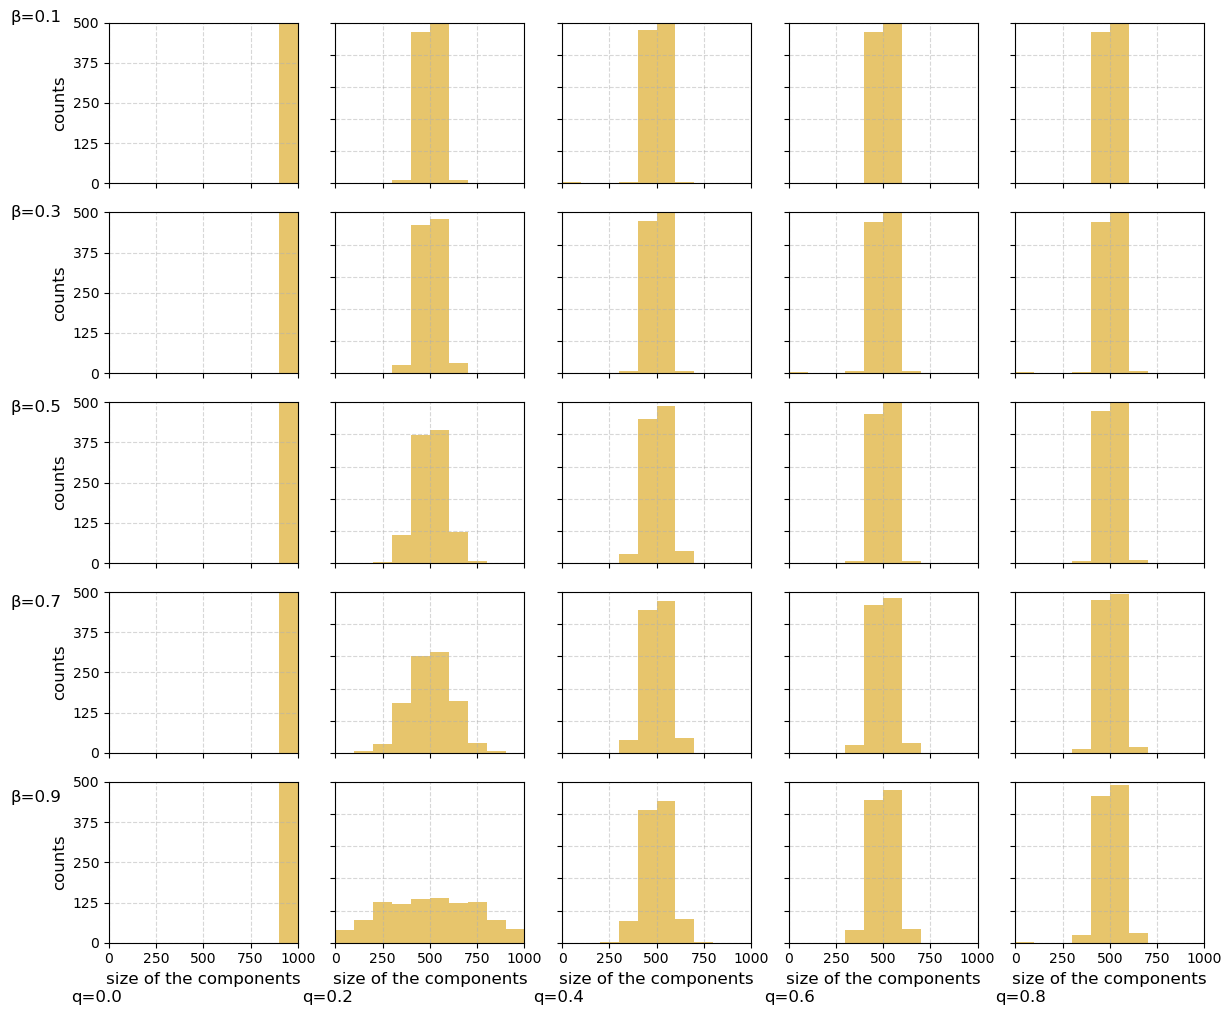

In [17]:
component_sizes(all_res,row='component_sizes')
plt.savefig('component_sizes.pdf')

In [278]:
qs[2:6]

array([0.2, 0.3, 0.4, 0.5])

In [18]:
def component_sizes(all_results, row='component_sizes', color_i=0,
                    typeofedges='size', iterations=10):

    betas_sub = betas[::2]
    qs_sub = qs[1:6]

    n_rows = len(betas_sub)
    n_cols = len(qs_sub)

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(12, 10),
        constrained_layout=True
    )
    axes = np.array(axes)

    # --- Histograms ---
    for r, beta in enumerate(betas_sub):
        for c, q in enumerate(qs_sub):

            ax = axes[r, c]
            results = all_results[2*r][c+1]

            # flatten component sizes
            data = []
            for arr in results[row]:
                data.extend(arr)

            ax.hist(
                data,
                bins=np.linspace(0, 1000, 15),
                color=colors[color_i],
                density=False
            )

            ax.set_xlim(0, 1000)
            ax.set_ylim(0, 500)
            ax.grid(True, linestyle='--', alpha=0.5)

            # y ticks only on 1st col
            if c == 0:
                ax.set_ylabel("counts", fontsize=fs)
                ax.set_yticks([0, 125, 250, 375, 500])
                ax.tick_params(axis='y', labelsize=ts)
            else:
                ax.tick_params(axis='y', labelleft=False)

            # x ticks only on last row
            if r == n_rows - 1:
                ax.set_xlabel("size", fontsize=fs)
                ax.set_xticks([0, 250, 500, 750, 1000])
                ax.tick_params(axis='x', labelsize=ts)
            else:
                ax.tick_params(axis='x', labelbottom=False)

            # annotate q below each column (fraction coords = always safe)
            if r == n_rows - 1:
                ax.annotate(
                    rf"$q=${q:.1f}",
                    xy=(0.1, -0.24),
                    xycoords='axes fraction',
                    ha='center',
                    fontsize=fs
                )

            # annotate beta left of each row
            if c == 0:
                ax.annotate(
                    rf"$\beta=${beta:.1f}",
                    xy=(-0.2, 0.85),
                    xycoords='axes fraction',
                    va='center',
                    ha='right',
                    fontsize=fs
                )

    # no need for tight_layout — we use constrained_layout
    plt.savefig("figures/component_sizes.pdf", bbox_inches='tight')
    plt.show()


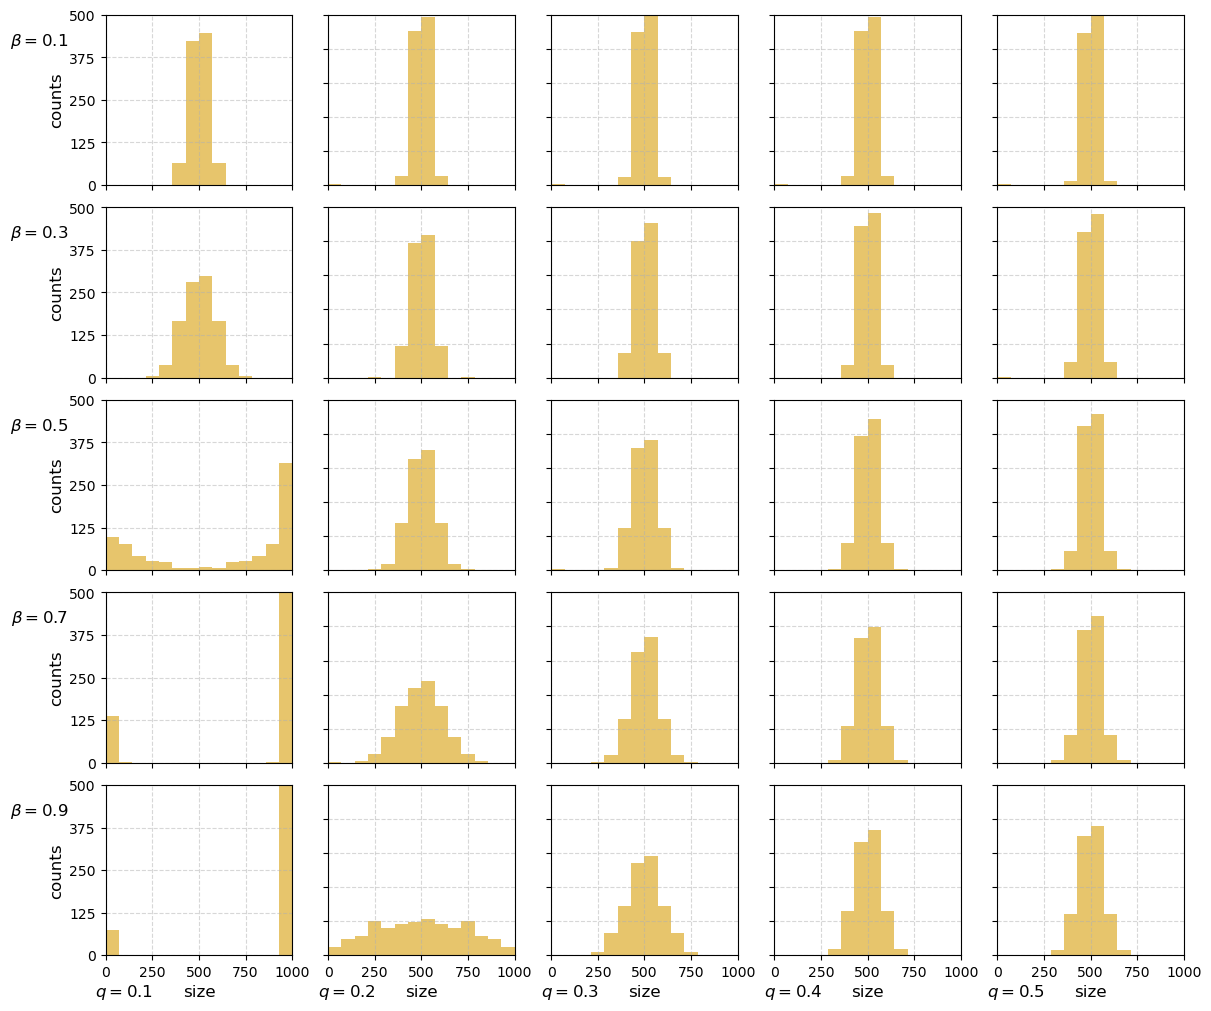

In [19]:
component_sizes(all_res,row='component_sizes')

-1


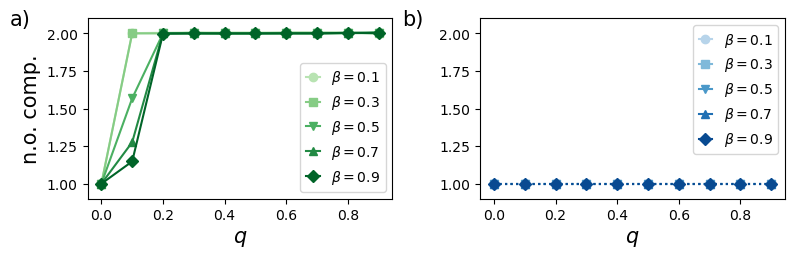

In [20]:
    k=0
    time=-1
    print(time)
    fig,axs = plt.subplots(1,2,figsize=(8,2.7))
    for j in range(0,len(betas),2):
        x1=[]
        x2=[]
        for i in range(0,len(qs)):
            results=all_res[j][i]
            s = np.mean([len(results['component_sizes'][it]) for it in range(iterations)])
            x1.append(s)
            mtx[j][i]=s
            results=all_res_nonlin[j][i]
            s = np.mean([len(results['component_sizes'][it]) for it in range(iterations)])

            x2.append(s)
        axs[0].plot(qs,x1,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=green_colors[j])
        axs[1].plot(qs,x2,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=blue_colors[j], ls='dotted')
        k+=1
    axs[0].set_xlabel(r'$q$', fontsize=15)
    axs[1].set_xlabel(r'$q$', fontsize=15)
    axs[0].set_ylabel(r'n.o. comp.', fontsize=15)
    axs[0].set_ylim(0.9,2.1)
    axs[1].set_ylim(0.9,2.1)
    
    #k=0
    #for j in range(0,len(betas),2):
    #    x1=[]
    #    x2=[]
    #    for i in range(0,len(qs)):
    #        results=all_res[j][i]
    #        s = np.mean([np.mean(results['component_sizes'][it]) for it in range(iterations)])
    #        x1.append(s)
    #        mtx[j][i]=s
    #        results=all_res_nonlin[j][i]
    #        s = np.mean([np.mean(results['component_sizes'][it]) for it in range(iterations)])
#
    #        x2.append(s)
    #    axs[1][0].plot(qs,x1,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=green_colors[j])
    #    axs[1][1].plot(qs,x2,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=blue_colors[j], ls='dotted')
    #    k+=1
    #axs[1][0].set_xlabel(r'$q$', fontsize=15)
    #axs[1][1].set_xlabel(r'$q$', fontsize=15)
    #axs[1][0].set_ylabel(r'av. comp. size', fontsize=15)
    #axs[1][0].set_ylim(480,1020)
    #axs[1][1].set_ylim(480,1020)

    hs=[]
    line = mlines.Line2D([], [], color=green_colors[0],marker=markers[0], label=rf'$\beta={betas[0]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[2],marker=markers[1], label=rf'$\beta={betas[2]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[4],marker=markers[2], label=rf'$\beta={betas[4]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[6],marker=markers[3], label=rf'$\beta={betas[6]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[8],marker=markers[4], label=rf'$\beta={betas[8]:.1f}$')
    hs.append(line)

    axs[0].legend(handles=hs,handlelength=1,ncol=1)
    
    hs=[]
    line = mlines.Line2D([], [], color=blue_colors[0],marker=markers[0], label=rf'$\beta={betas[0]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[2],marker=markers[1], label=rf'$\beta={betas[2]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[4],marker=markers[2], label=rf'$\beta={betas[4]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[6],marker=markers[3], label=rf'$\beta={betas[6]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[8],marker=markers[4], label=rf'$\beta={betas[8]:.1f}$')
    hs.append(line)

    axs[1].legend(handles=hs,handlelength=1,ncol=1)

    axs[0].text(-0.22, 1.05, 'a)', transform=axs[0].transAxes,ha='center' ,va='top',fontsize=15)
    axs[1].text(-0.22, 1.05, 'b)', transform=axs[1].transAxes,ha='center', va='top',fontsize=15)
    #axs[1][0].text(-0.22, 1.05, 'c)', transform=axs[1][0].transAxes,ha='center' ,va='top',fontsize=15)
    #axs[1][1].text(-0.22, 1.05, 'd)', transform=axs[1][1].transAxes,ha='center', va='top',fontsize=15)

    plt.tight_layout()
    plt.savefig('figures/component_n_mean.pdf')
    plt.show()

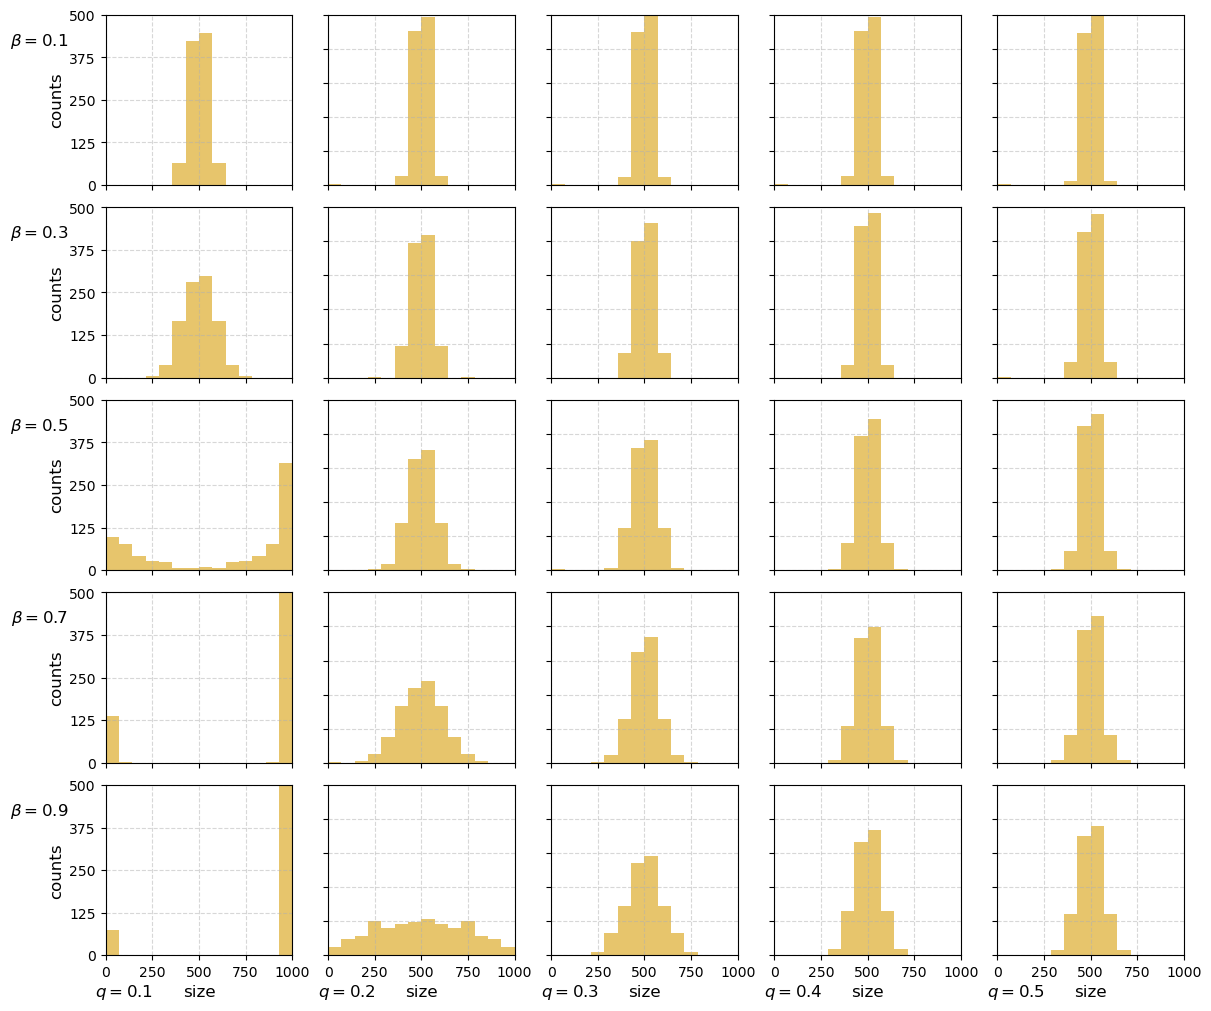

In [21]:
component_sizes(all_res,row='component_sizes')

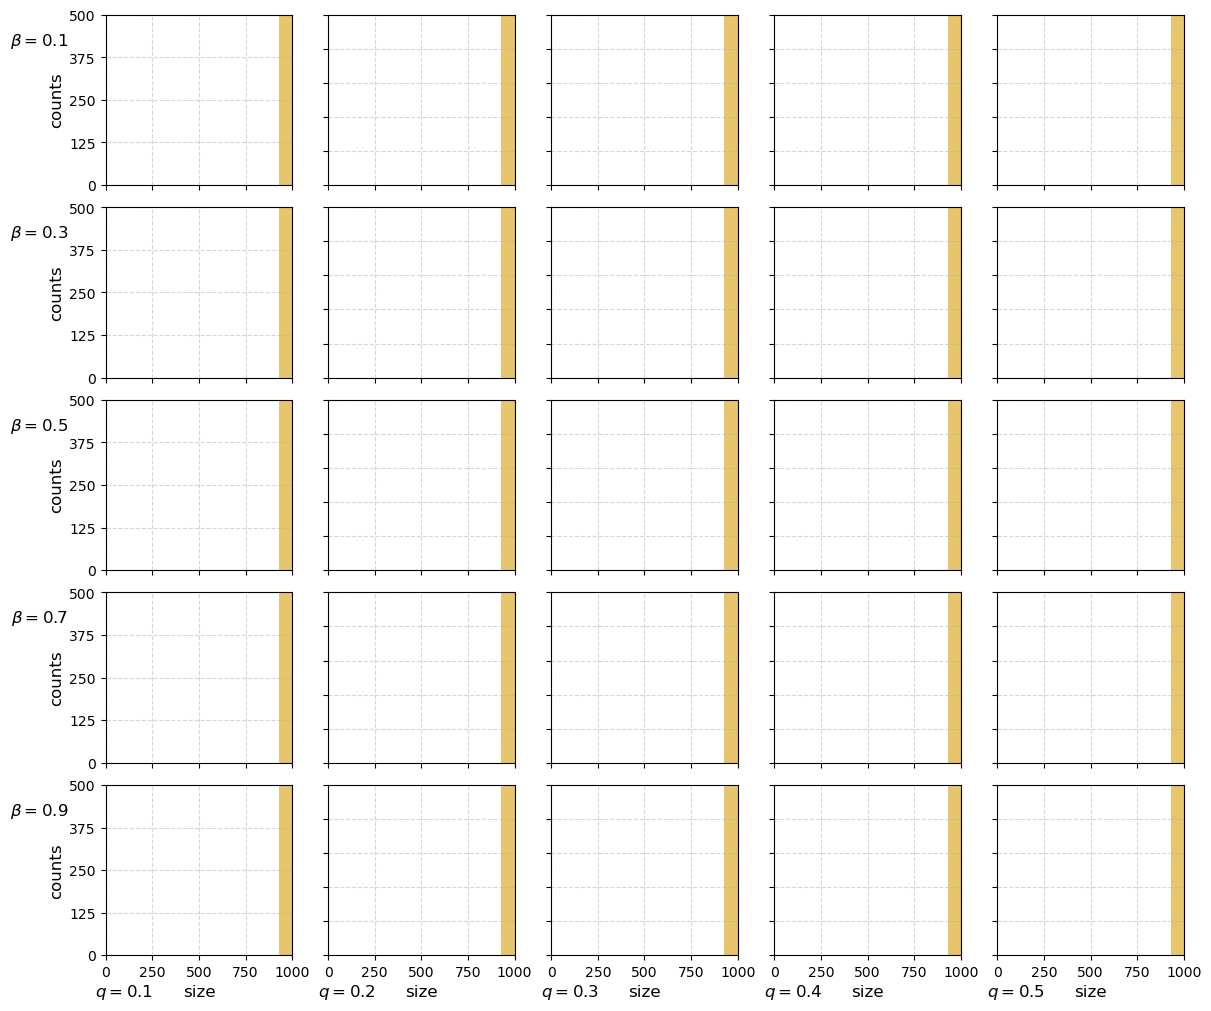

In [22]:
component_sizes(all_res_nonlin,row='component_sizes')

In [100]:
all_res[3][3]['component_sizes'][0],all_res[3][3]['component_opinion'][0],all_res[3][3]['component_homo'][0]

([35, 65], [35, 0], [111, 165])

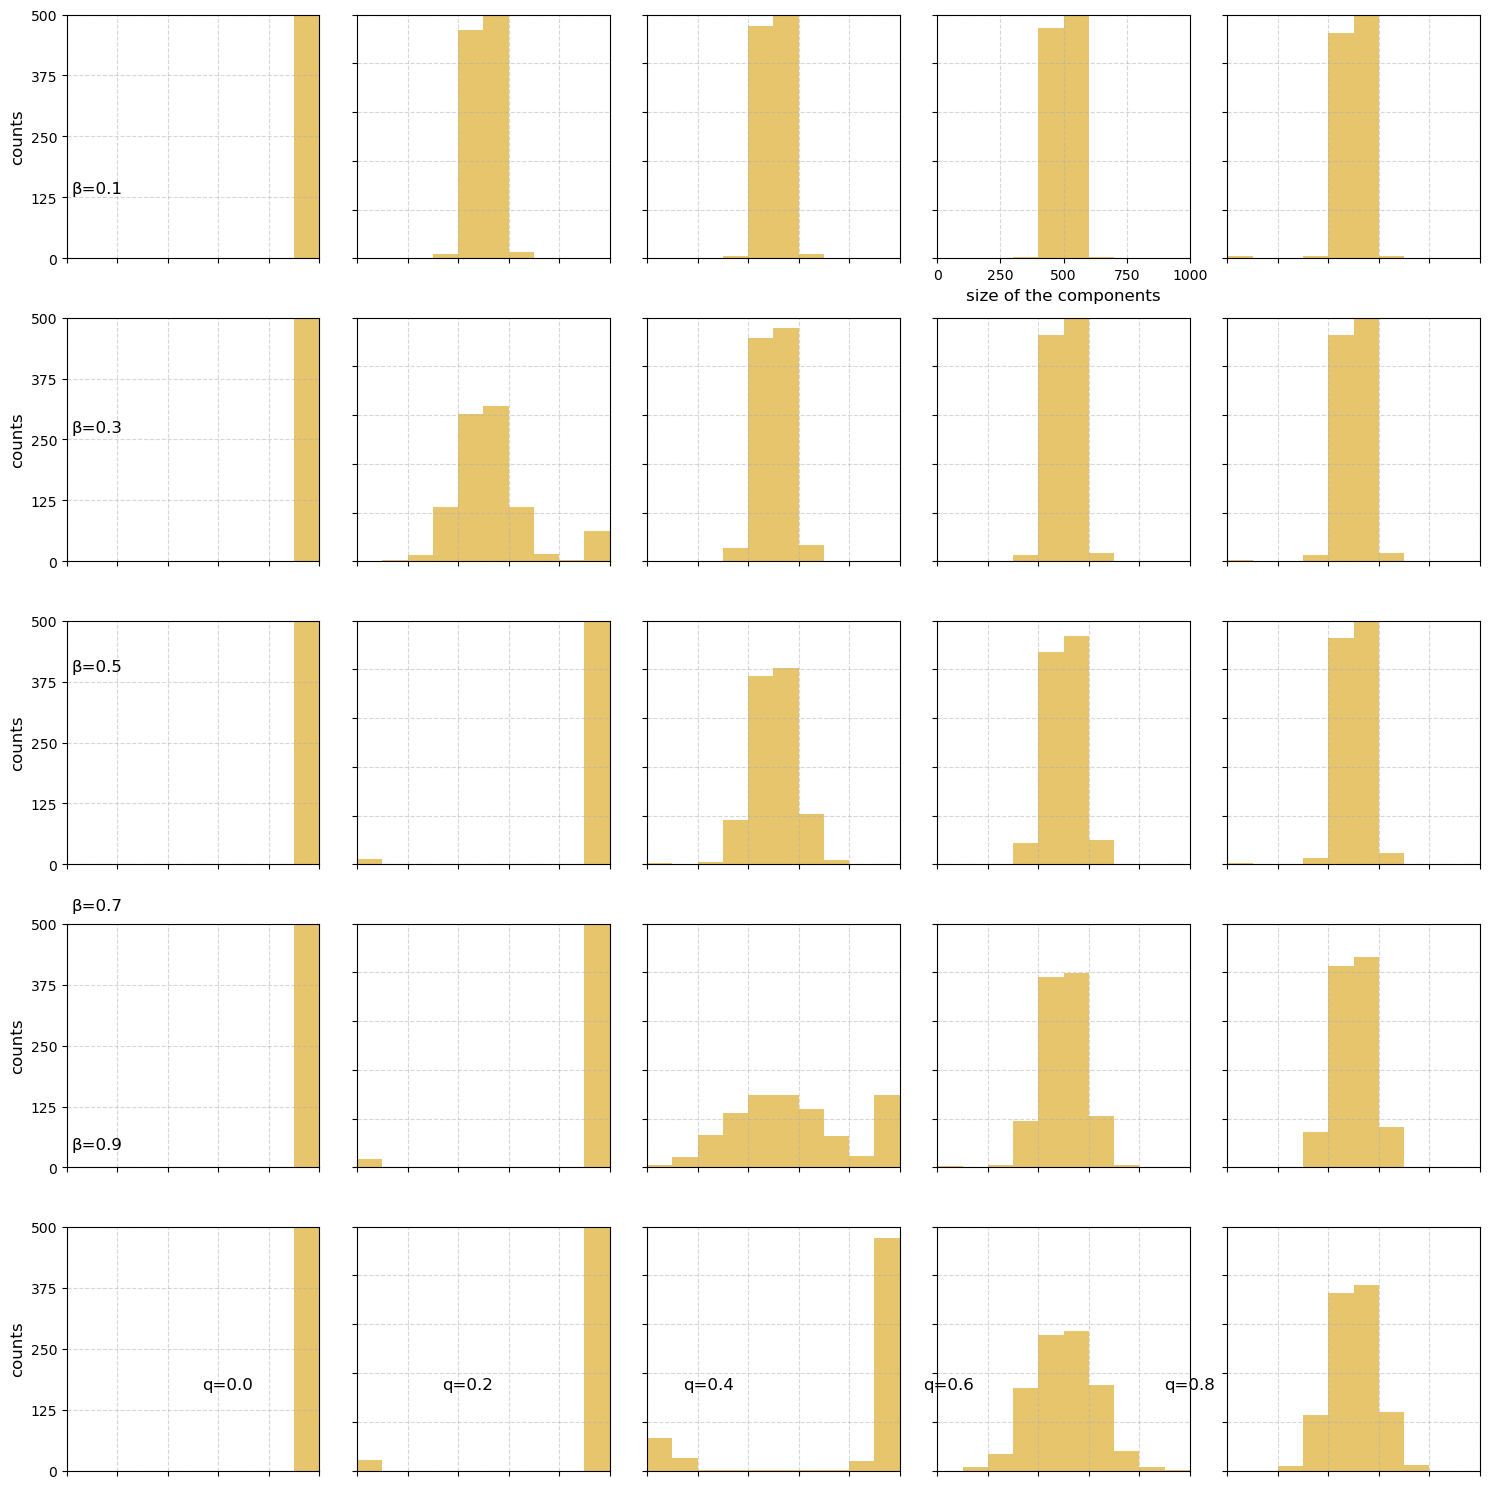

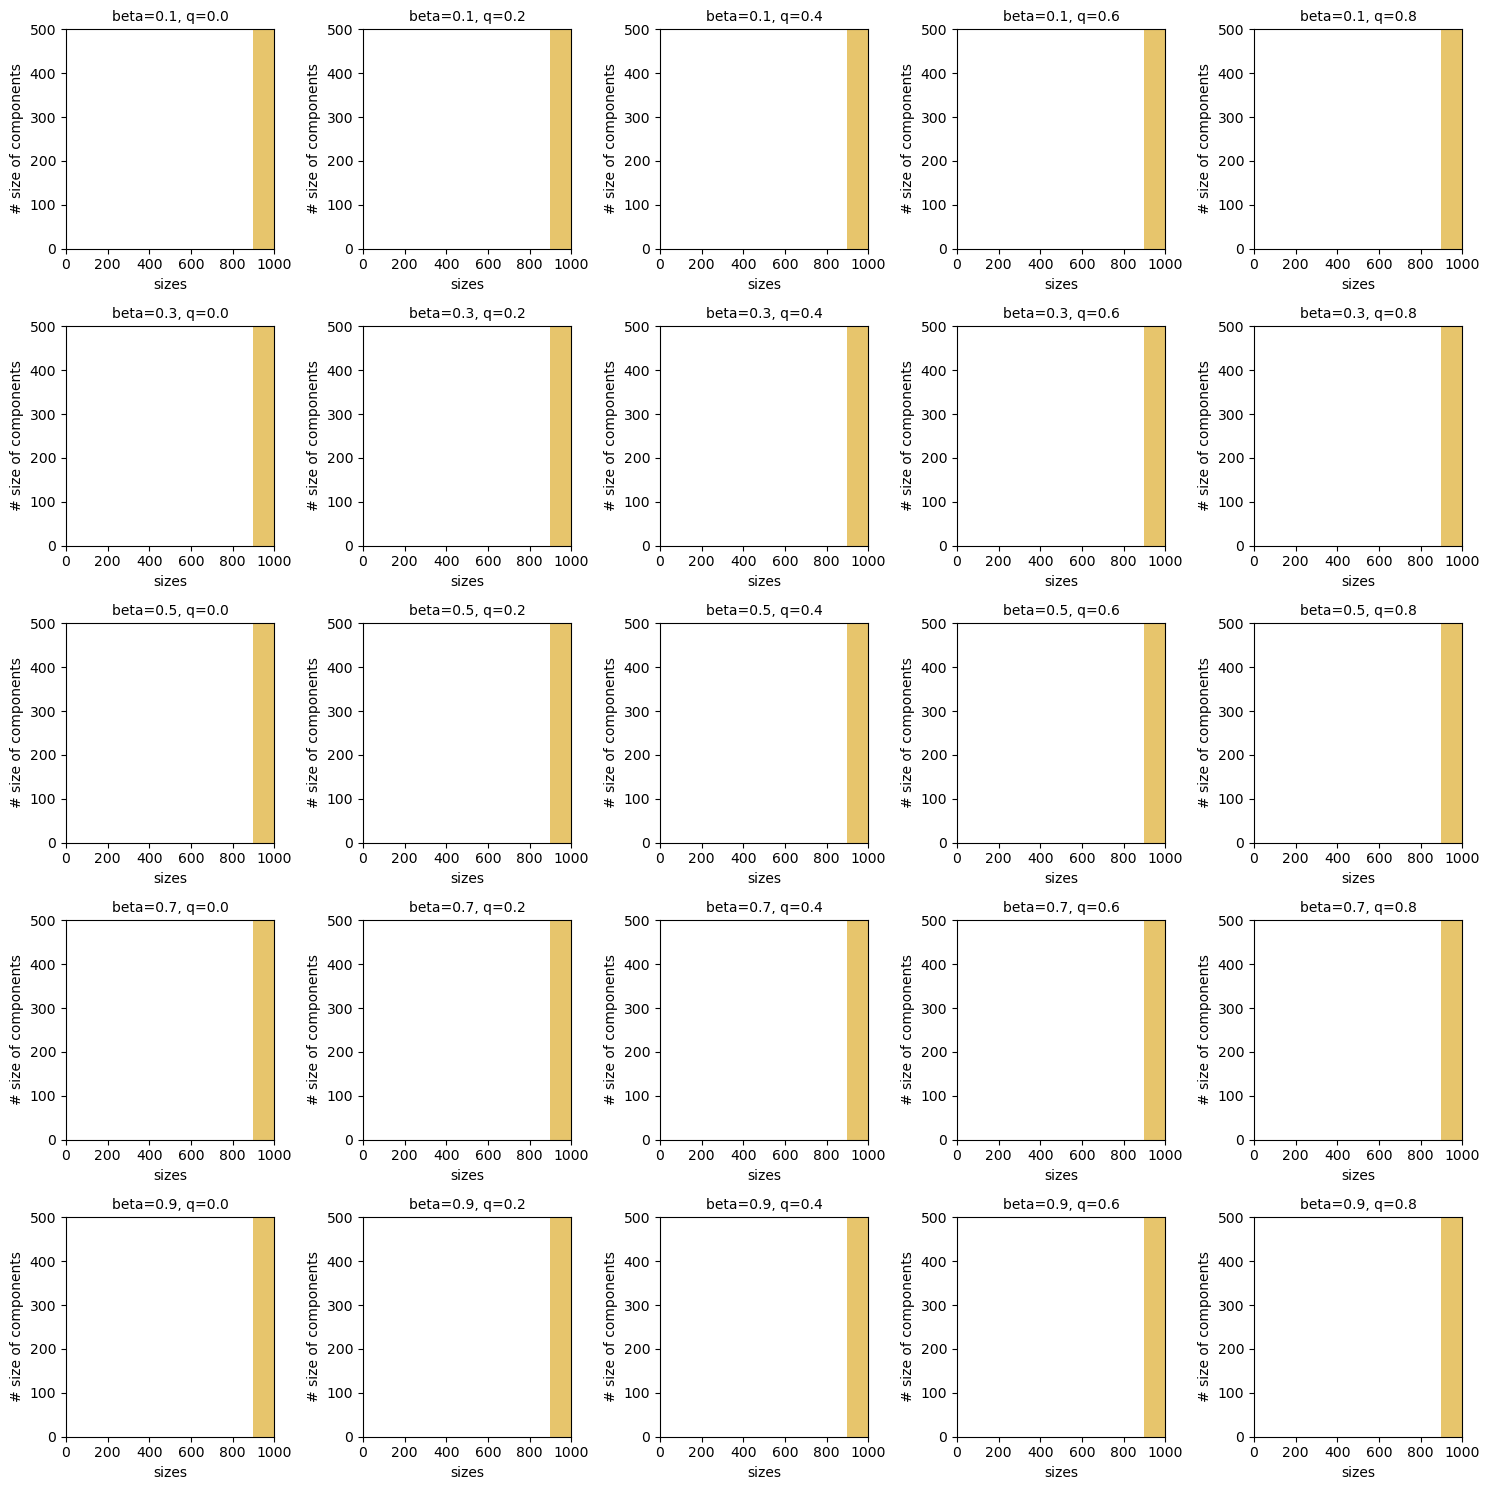

In [125]:
component_sizes(all_res_nonlin,row='component_sizes')
plt.savefig('component_sizes.pdf')

-1


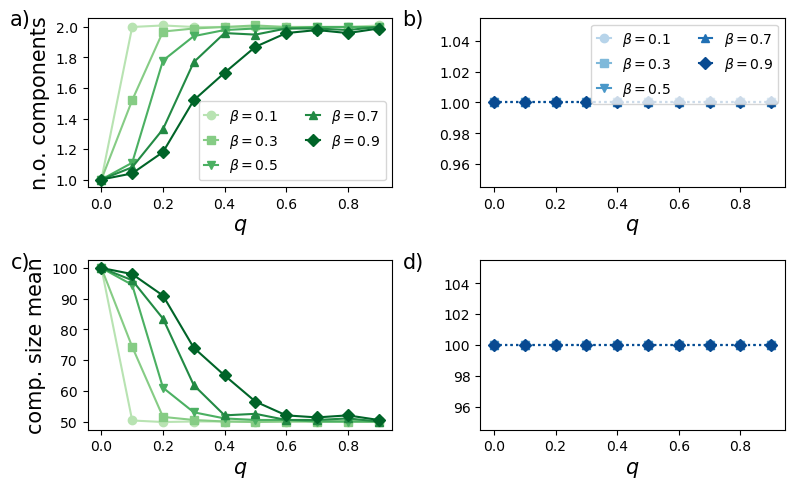

In [294]:
    k=0
    time=-1
    print(time)
    fig,axs = plt.subplots(2,2,figsize=(8,5))
    for j in range(0,len(betas),2):
        x1=[]
        x2=[]
        for i in range(0,len(qs)):
            results=all_res_100[j][i]
            s = np.mean([len(results['component_sizes'][it]) for it in range(iterations)])
            x1.append(s)
            mtx[j][i]=s
            results=all_res_nonlin_100[j][i]
            s = np.mean([len(results['component_sizes'][it]) for it in range(iterations)])

            x2.append(s)
        axs[0][0].plot(qs,x1,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=green_colors[j])
        axs[0][1].plot(qs,x2,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=blue_colors[j], ls='dotted')
        k+=1
    axs[0][0].set_xlabel(r'$q$', fontsize=15)
    axs[0][1].set_xlabel(r'$q$', fontsize=15)
    axs[0][0].set_ylabel(r'n.o. components', fontsize=15)
    #axs[0][0].set_ylim(0,0.2)
    #axs[0][1].set_ylim(0,0.02)
    k=0
    for j in range(0,len(betas),2):
        x1=[]
        x2=[]
        for i in range(0,len(qs)):
            results=all_res_100[j][i]
            s = np.mean([np.mean(results['component_sizes'][it]) for it in range(iterations)])
            x1.append(s)
            mtx[j][i]=s
            results=all_res_nonlin_100[j][i]
            s = np.mean([np.mean(results['component_sizes'][it]) for it in range(iterations)])

            x2.append(s)
        axs[1][0].plot(qs,x1,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=green_colors[j])
        axs[1][1].plot(qs,x2,label=rf'$\beta={betas[j]:.1f}',marker=markers[k], color=blue_colors[j], ls='dotted')
        k+=1
    axs[1][0].set_xlabel(r'$q$', fontsize=15)
    axs[1][1].set_xlabel(r'$q$', fontsize=15)
    axs[1][0].set_ylabel(r'comp. size mean', fontsize=15)
    #axs[0][0].set_ylim(0,0.2)
    #axs[0][1].set_ylim(0,0.02)

    hs=[]
    line = mlines.Line2D([], [], color=green_colors[0],marker=markers[0], label=rf'$\beta={betas[0]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[2],marker=markers[1], label=rf'$\beta={betas[2]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[4],marker=markers[2], label=rf'$\beta={betas[4]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[6],marker=markers[3], label=rf'$\beta={betas[6]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=green_colors[8],marker=markers[4], label=rf'$\beta={betas[8]:.1f}$')
    hs.append(line)

    axs[0][0].legend(handles=hs,handlelength=1,ncol=2)
    
    hs=[]
    line = mlines.Line2D([], [], color=blue_colors[0],marker=markers[0], label=rf'$\beta={betas[0]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[2],marker=markers[1], label=rf'$\beta={betas[2]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[4],marker=markers[2], label=rf'$\beta={betas[4]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[6],marker=markers[3], label=rf'$\beta={betas[6]:.1f}$')
    hs.append(line)
    line = mlines.Line2D([], [], color=blue_colors[8],marker=markers[4], label=rf'$\beta={betas[8]:.1f}$')
    hs.append(line)

    axs[0][1].legend(handles=hs,handlelength=1,ncol=2)

    axs[0][0].text(-0.22, 1.05, 'a)', transform=axs[0][0].transAxes,ha='center' ,va='top',fontsize=15)
    axs[0][1].text(-0.22, 1.05, 'b)', transform=axs[0][1].transAxes,ha='center', va='top',fontsize=15)
    axs[1][0].text(-0.22, 1.05, 'c)', transform=axs[1][0].transAxes,ha='center' ,va='top',fontsize=15)
    axs[1][1].text(-0.22, 1.05, 'd)', transform=axs[1][1].transAxes,ha='center', va='top',fontsize=15)

    plt.tight_layout()
    plt.savefig('figures/component_n_mean.pdf')
    plt.show()

# Check edgsize 

long_2_regular_n_1000_edgesize_10_lin.pickle

In [180]:
betas=np.array([0.1,0.5,0.9])
qs=np.array([0.1,0.5,0.9])
row_names = ['sum_opinion_A','component_sizes','homophily']


edge_sizes = [10, 20, 30, 40, 50,60,70,80,90,100]
homophily_array_hh = np.zeros((3,3,len(edge_sizes)))
homophily_confidance_array_hh = np.zeros((3,3,len(edge_sizes)))

homophily_array_wp = np.zeros((3,3,len(edge_sizes)))
homophily_confidance_array_wp = np.zeros((3,3,len(edge_sizes)))

end_time_array = np.zeros((3,3,len(edge_sizes)))
end_time_confidance_array = np.zeros((3,3,len(edge_sizes)))
for s in edge_sizes:
    filename = f'/scratch/kolokcse/logs_hypergraph/majority_move_lin_long_final/long_2_regular_n_1000_edgesize_{s}_lin.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=100
    for beta_i, beta in enumerate(betas):
        for q_i,q in enumerate(qs):
            homophily_array_hh[beta_i][q_i][edge_sizes.index(s)] = np.mean([results_dict[beta_i][q_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i][edge_sizes.index(s)] = np.mean([results_dict[beta_i][q_i][i]['homophily'][-1][1] for i in range(iterations)])





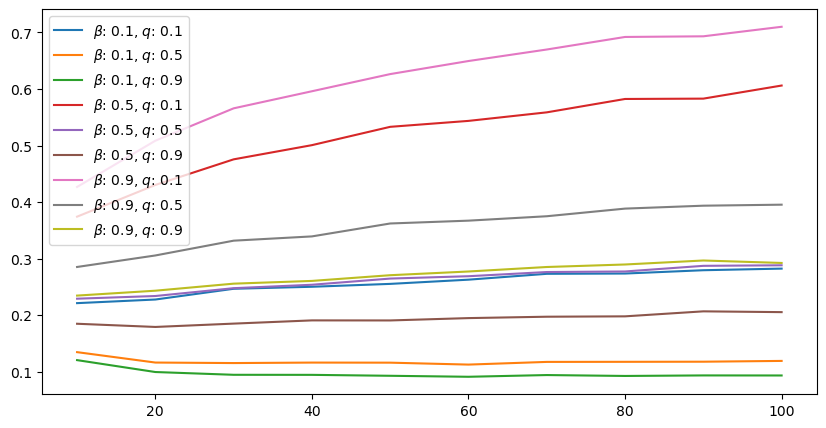

In [10]:
plt.figure(figsize=(10,5))
for beta_i, beta in enumerate(betas):
    for q_i,q in enumerate(qs):
        plt.plot(edge_sizes, homophily_array_hh[beta_i][q_i], label=rf'$\beta$: {beta}, $q$: {q}')
        
plt.legend()

In [181]:
betas=np.array([0.1,0.5,0.9])
qs=np.array([0.1,0.5,0.9])
row_names = ['sum_opinion_A','component_sizes','homophily']


edge_sizes = [10, 20, 30, 40, 50,60,70,80,90,100]
homophily_array_hh = np.zeros((3,3,len(edge_sizes)))
homophily_confidance_array_hh = np.zeros((3,3,len(edge_sizes)))

homophily_array_wp = np.zeros((3,3,len(edge_sizes)))
homophily_confidance_array_wp = np.zeros((3,3,len(edge_sizes)))

num_comp_array = np.zeros((3,3,len(edge_sizes)))
num_comp_confidence_array = np.zeros((3,3,len(edge_sizes)))

end_time_array = np.zeros((3,3,len(edge_sizes)))
end_time_confidance_array = np.zeros((3,3,len(edge_sizes)))
for s in edge_sizes:
    filename = f'/scratch/kolokcse/logs_hypergraph/majority_move_lin_long_final/long_2_regular_n_1000_edgesize_{s}_lin.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=100
    for beta_i, beta in enumerate(betas):
        for q_i,q in enumerate(qs):
            homophily_array_hh[beta_i][q_i][edge_sizes.index(s)], homophily_confidance_array_hh[beta_i][q_i][edge_sizes.index(s)] = mean_confidence_interval([results_dict[beta_i][q_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i][edge_sizes.index(s)], homophily_confidance_array_wp[beta_i][q_i][edge_sizes.index(s)] = mean_confidence_interval([results_dict[beta_i][q_i][i]['homophily'][-1][1] for i in range(iterations)])
            
            num_comp_array[beta_i][q_i][edge_sizes.index(s)], num_comp_confidence_array[beta_i][q_i][edge_sizes.index(s)] = mean_confidence_interval([len(results_dict[beta_i][q_i][i]['component_sizes']) for i in range(iterations)])
           
            end_time_array[beta_i][q_i][edge_sizes.index(s)], end_time_confidance_array[beta_i][q_i][edge_sizes.index(s)] = mean_confidence_interval([len(results_dict[beta_i][q_i][i]['sum_opinion_A']) for i in range(iterations)])

In [182]:
def plot_homophily_endtime(focus_param,focus_param_name,savename, homophily_array_hh, homophily_confidance_array_hh, homophily_array_wp, homophily_confidance_array_wp,num_comp_array,num_comp_confidence_array, end_time_array, end_time_confidance_array, betas, qs, endtimemax=3500):
    fig, axs = plt.subplots(3, 3, figsize=(13, 6), sharex=True)

    # Define colors for each beta value
    beta_colors = plt.cm.Set1(np.linspace(0, 1, len(betas)))

    # First row: homophily
    for q_i, q in enumerate(qs):
        ax = axs[0, q_i]
        
        for beta_i, beta in enumerate(betas):
            color = beta_colors[beta_i]
            
            # hh homophily - solid line
            upper_hh = homophily_array_hh[beta_i][q_i] + homophily_confidance_array_hh[beta_i][q_i]
            lower_hh = homophily_array_hh[beta_i][q_i] - homophily_confidance_array_hh[beta_i][q_i]
            ax.fill_between(focus_param, lower_hh, upper_hh, alpha=0.2, color=color)
            ax.plot(focus_param, homophily_array_hh[beta_i][q_i], marker='o', linestyle='-', 
                    color=color, label=rf'hh $\beta$={beta}')
            
            # wp homophily - dashed line
            upper_wp = homophily_array_wp[beta_i][q_i] + homophily_confidance_array_wp[beta_i][q_i]
            lower_wp = homophily_array_wp[beta_i][q_i] - homophily_confidance_array_wp[beta_i][q_i]
            ax.fill_between(focus_param, lower_wp, upper_wp, alpha=0.2, color=color)
            ax.plot(focus_param, homophily_array_wp[beta_i][q_i], marker='s', linestyle='--', 
                    color=color, label=rf'wp $\beta$={beta}')
        
        ax.set_title(rf'$q$ = {q}', fontsize=12)
        ax.set_ylim(0, 1.05)
        ax.grid(True, alpha=0.3)
        
        if q_i == 2:
            ax.legend(loc='best', fontsize=9, ncol=3)
        
        if q_i == 0:
            ax.set_ylabel('homophily', fontsize=11)
            
    # Second row: end_time_array
    for q_i, q in enumerate(qs):
        ax = axs[1, q_i]
        
        for beta_i, beta in enumerate(betas):
            color = beta_colors[beta_i]
            
            # end_time - solid line with circle marker
            upper_et = num_comp_array[beta_i][q_i] + num_comp_confidence_array[beta_i][q_i]
            lower_et = num_comp_array[beta_i][q_i] - num_comp_confidence_array[beta_i][q_i]
            ax.fill_between(focus_param, lower_et, upper_et, alpha=0.2, color=color)
            ax.plot(focus_param, num_comp_array[beta_i][q_i], marker='o', linestyle='-', 
                    color=color, label=rf'$\beta$: {beta}')
        
        ax.set_ylim(0.9, 2.2)
        
        ax.grid(True, alpha=0.3)
        
        if q_i == 0:
            ax.set_ylabel('number of components', fontsize=11)

       

    # third row: end_time_array
    for q_i, q in enumerate(qs):
        ax = axs[2, q_i]
        
        for beta_i, beta in enumerate(betas):
            color = beta_colors[beta_i]
            
            # end_time - solid line with circle marker
            upper_et = end_time_array[beta_i][q_i] + end_time_confidance_array[beta_i][q_i]
            lower_et = end_time_array[beta_i][q_i] - end_time_confidance_array[beta_i][q_i]
            ax.fill_between(focus_param, lower_et, upper_et, alpha=0.2, color=color)
            ax.plot(focus_param, end_time_array[beta_i][q_i], marker='o', linestyle='-', 
                    color=color, label=rf'$\beta$: {beta}')
        
        
        ax.set_xlabel(focus_param_name, fontsize=11)
        ax.set_ylim(0, endtimemax)
        
        ax.grid(True, alpha=0.3)
        
        if q_i == 0:
            ax.set_ylabel('absorption time', fontsize=11)

    plt.tight_layout()
    plt.savefig('figures/'+savename + '.pdf')
    plt.show()

In [183]:
pwd

'/home/kolokcse/hypergraph'

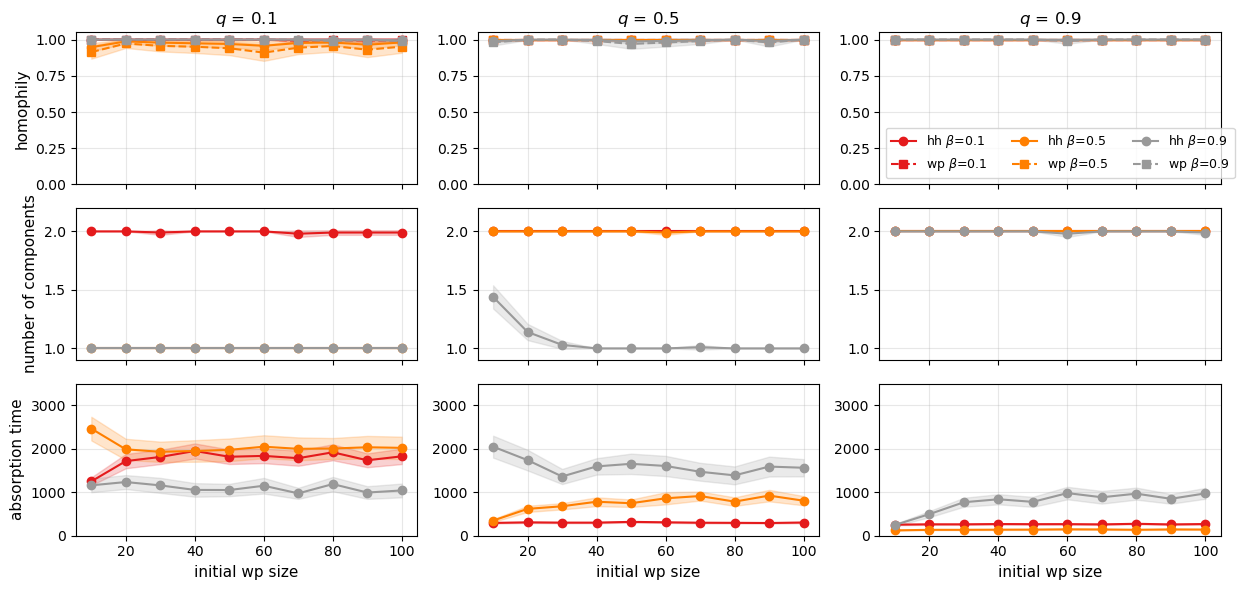

In [184]:
plot_homophily_endtime(edge_sizes,'initial wp size','edge_size_lin',  homophily_array_hh, homophily_confidance_array_hh, homophily_array_wp, homophily_confidance_array_wp,num_comp_array,num_comp_confidence_array, end_time_array ,end_time_confidance_array, betas, qs)

In [185]:
betas=np.array([0.1,0.5,0.9])
qs=np.array([0.1,0.5,0.9])
row_names = ['sum_opinion_A','component_sizes','homophily']


edge_sizes = [10, 20, 30, 40, 50,60,70,80,90,100]
homophily_array_hh = np.zeros((3,3,len(edge_sizes)))
homophily_confidance_array_hh = np.zeros((3,3,len(edge_sizes)))

homophily_array_wp = np.zeros((3,3,len(edge_sizes)))
homophily_confidance_array_wp = np.zeros((3,3,len(edge_sizes)))

num_comp_array = np.zeros((3,3,len(edge_sizes)))
num_comp_confidence_array = np.zeros((3,3,len(edge_sizes)))

end_time_array = np.zeros((3,3,len(edge_sizes)))
end_time_confidance_array = np.zeros((3,3,len(edge_sizes)))
for s in edge_sizes:
    filename = f'/scratch/kolokcse/logs_hypergraph/majority_move_nonlin_long_final/long_2_regular_n_1000_edgesize_{s}_nonlin.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=100
    for beta_i, beta in enumerate(betas):
        for q_i,q in enumerate(qs):
            homophily_array_hh[beta_i][q_i][edge_sizes.index(s)], homophily_confidance_array_hh[beta_i][q_i][edge_sizes.index(s)] = mean_confidence_interval([results_dict[beta_i][q_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i][edge_sizes.index(s)], homophily_confidance_array_wp[beta_i][q_i][edge_sizes.index(s)] = mean_confidence_interval([results_dict[beta_i][q_i][i]['homophily'][-1][1] for i in range(iterations)])
            
            num_comp_array[beta_i][q_i][edge_sizes.index(s)], num_comp_confidence_array[beta_i][q_i][edge_sizes.index(s)] = mean_confidence_interval([len(results_dict[beta_i][q_i][i]['component_sizes']) for i in range(iterations)])
           
            end_time_array[beta_i][q_i][edge_sizes.index(s)], end_time_confidance_array[beta_i][q_i][edge_sizes.index(s)] = mean_confidence_interval([len(results_dict[beta_i][q_i][i]['sum_opinion_A']) for i in range(iterations)])

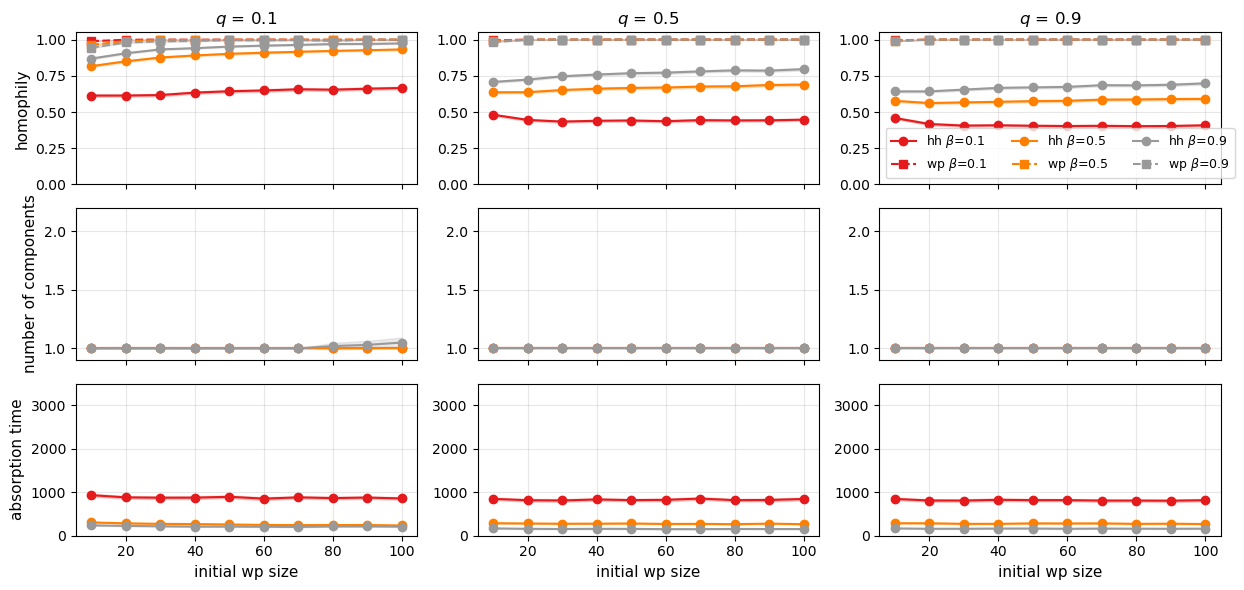

In [186]:
plot_homophily_endtime(edge_sizes,'initial wp size','edge_size_nonlin',  homophily_array_hh, homophily_confidance_array_hh, homophily_array_wp, homophily_confidance_array_wp,num_comp_array,num_comp_confidence_array, end_time_array ,end_time_confidance_array, betas, qs)

# Lambda

In [ ]:
betas=np.array([0.1,0.5,0.9])
qs=np.array([0.1,0.5,0.9])
row_names = ['sum_opinion_A','component_sizes','homophily', 'max_workplace_size','change_prob_sum', 'move_prob_sum']


lambdas = np.linspace(0.45,0.65,10)
homophily_array_hh = np.zeros((3,3,len(lambdas)))
homophily_confidance_array_hh = np.zeros((3,3,len(lambdas)))

homophily_array_wp = np.zeros((3,3,len(lambdas)))
homophily_confidance_array_wp = np.zeros((3,3,len(lambdas)))

num_comp_array = np.zeros((3,3,len(lambdas)))
num_comp_confidence_array = np.zeros((3,3,len(lambdas)))

end_time_array = np.zeros((3,3,len(lambdas)))
end_time_confidance_array = np.zeros((3,3,len(lambdas)))

for q_i,q in enumerate(qs):
    filename = f'/scratch/kolokcse/logs_hypergraph/lambda/long_2_regular_q_{q}_lin.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=100
    for beta_i, beta in enumerate(betas):
        for lambda_i, lambda_ in enumerate(lambdas):
            homophily_array_hh[beta_i][q_i][lambda_i], homophily_confidance_array_hh[beta_i][q_i][lambda_i] = mean_confidence_interval([results_dict[beta_i][lambda_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i][lambda_i], homophily_confidance_array_wp[beta_i][q_i][lambda_i] = mean_confidence_interval([results_dict[beta_i][lambda_i][i]['homophily'][-1][1] for i in range(iterations)])
            num_comp_array[beta_i][q_i][lambda_i], num_comp_confidence_array[beta_i][q_i][lambda_i] = mean_confidence_interval([len(results_dict[beta_i][lambda_i][i]['component_sizes']) for i in range(iterations)])
           
            end_time_array[beta_i][q_i][lambda_i], end_time_confidance_array[beta_i][q_i][lambda_i] = mean_confidence_interval([len(results_dict[beta_i][lambda_i][i]['sum_opinion_A']) for i in range(iterations)])

IndexError: list index out of range

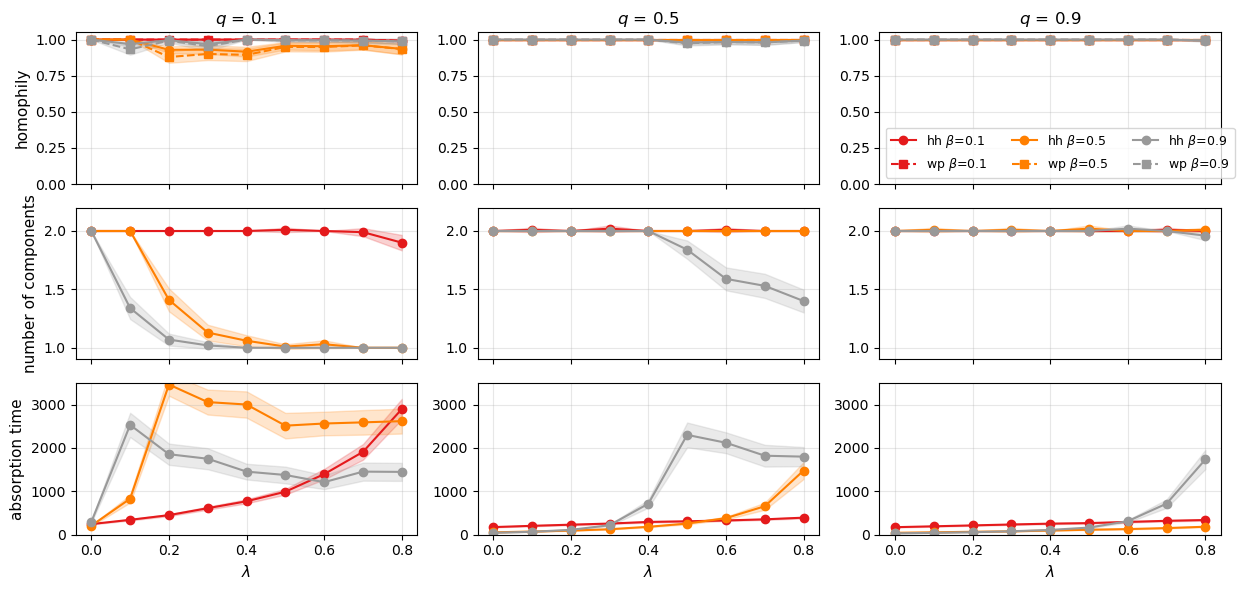

In [188]:
plot_homophily_endtime(lambdas,r'$\lambda$','lambda_lin', homophily_array_hh, homophily_confidance_array_hh, homophily_array_wp, homophily_confidance_array_wp,num_comp_array,num_comp_confidence_array, end_time_array, end_time_confidance_array, betas, qs, endtimemax=3500)

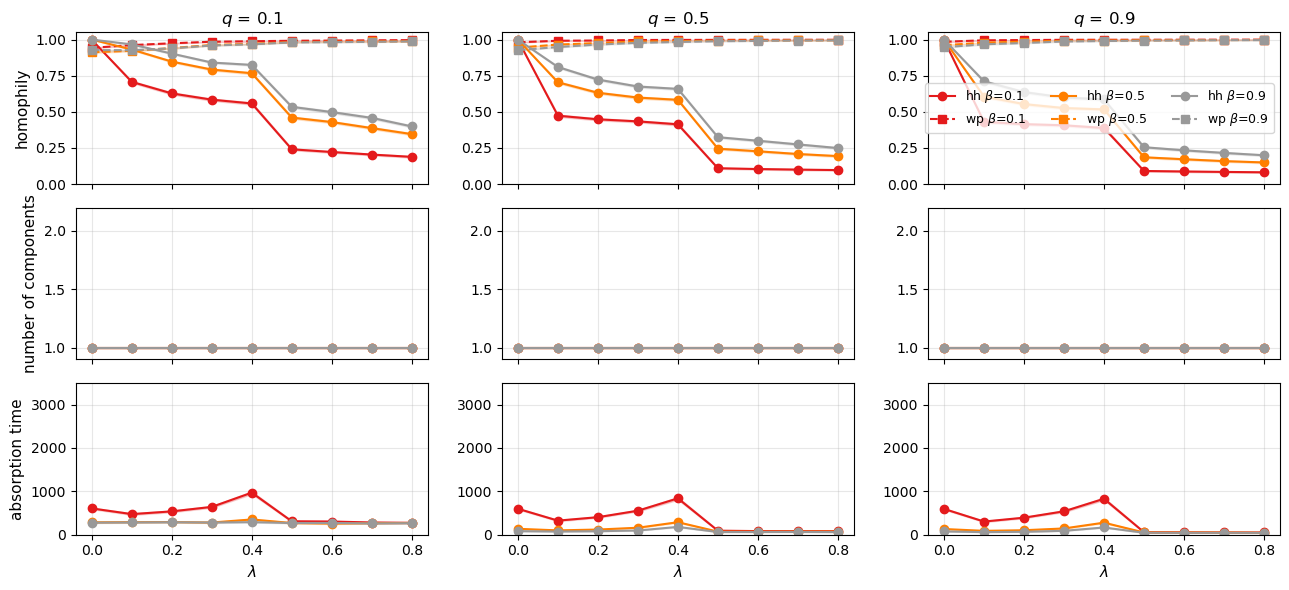

In [ ]:
betas=np.array([0.1,0.5,0.9])
qs=np.array([0.1,0.5,0.9])
row_names = ['sum_opinion_A','component_sizes','homophily', 'max_workplace_size','change_prob_sum', 'move_prob_sum']


lambdas = np.arange(0,0.9,0.1)
homophily_array_hh = np.zeros((3,3,len(lambdas)))
homophily_confidance_array_hh = np.zeros((3,3,len(lambdas)))

homophily_array_wp = np.zeros((3,3,len(lambdas)))
homophily_confidance_array_wp = np.zeros((3,3,len(lambdas)))

num_comp_array = np.zeros((3,3,len(lambdas)))
num_comp_confidence_array = np.zeros((3,3,len(lambdas)))

end_time_array = np.zeros((3,3,len(lambdas)))
end_time_confidance_array = np.zeros((3,3,len(lambdas)))

for q_i,q in enumerate(qs):
    filename = f'/scratch/kolokcse/logs_hypergraph/lambda/long_2_regular_q_{q}_nonlin.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=100
    for beta_i, beta in enumerate(betas):
        for lambda_i, lambda_ in enumerate(lambdas):
            homophily_array_hh[beta_i][q_i][lambda_i], homophily_confidance_array_hh[beta_i][q_i][lambda_i] = mean_confidence_interval([results_dict[beta_i][lambda_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i][lambda_i], homophily_confidance_array_wp[beta_i][q_i][lambda_i] = mean_confidence_interval([results_dict[beta_i][lambda_i][i]['homophily'][-1][1] for i in range(iterations)])
            num_comp_array[beta_i][q_i][lambda_i], num_comp_confidence_array[beta_i][q_i][lambda_i] = mean_confidence_interval([len(results_dict[beta_i][lambda_i][i]['component_sizes']) for i in range(iterations)])
           
            end_time_array[beta_i][q_i][lambda_i], end_time_confidance_array[beta_i][q_i][lambda_i] = mean_confidence_interval([len(results_dict[beta_i][lambda_i][i]['sum_opinion_A']) for i in range(iterations)])
plot_homophily_endtime(lambdas,r'$\lambda$','lambda_nonlin', homophily_array_hh, homophily_confidance_array_hh, homophily_array_wp, homophily_confidance_array_wp,num_comp_array,num_comp_confidence_array, end_time_array, end_time_confidance_array, betas, qs, endtimemax=3500)

/home/kolokcse/anaconda3/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1670: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


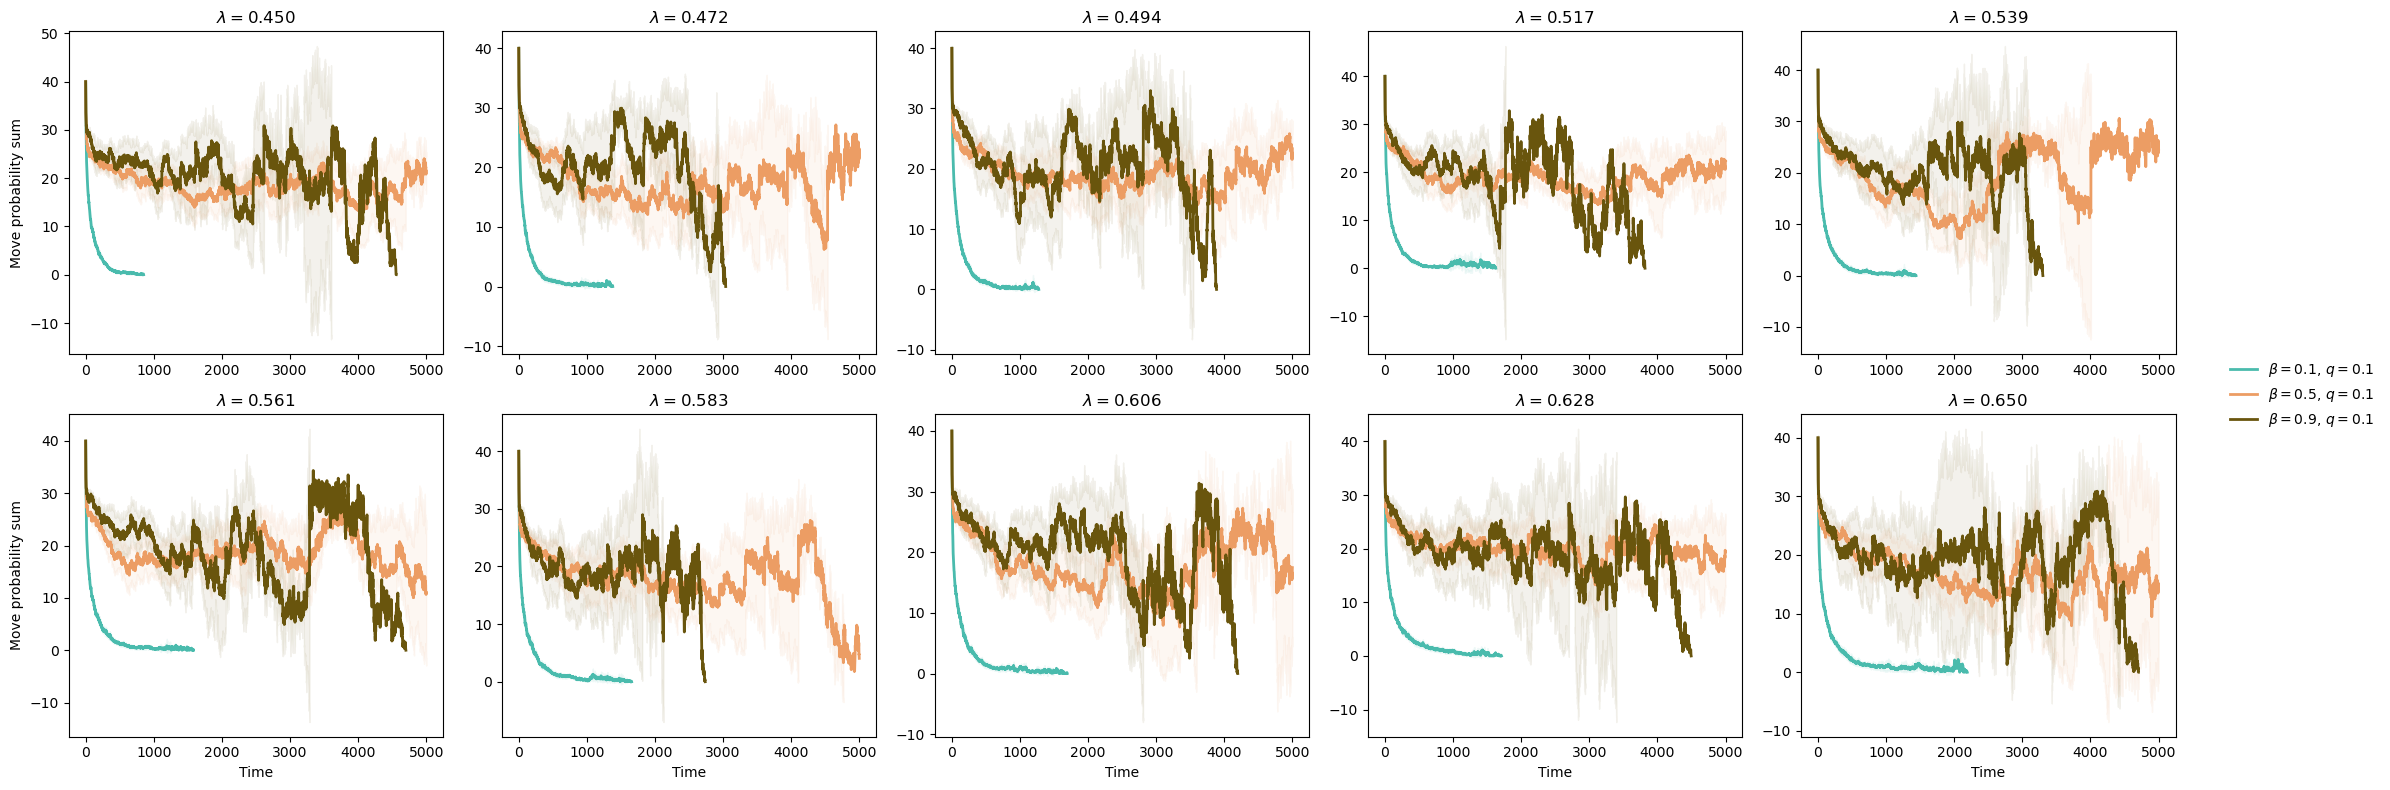

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

def mean_ci_timeseries(trajectories):
    max_len = max(len(x) for x in trajectories)

    data = np.full((len(trajectories), max_len), np.nan)

    for i, tr in enumerate(trajectories):
        data[i, :len(tr)] = tr

    mean = np.nanmean(data, axis=0)

    n = np.sum(~np.isnan(data), axis=0)
    se = np.nanstd(data, axis=0, ddof=1) / np.sqrt(n)

    ci = 1.96 * se
    return mean, ci


betas = np.array([0.1, 0.5, 0.9])
qs = np.array([0.1])

lambdas = np.linspace(0.45, 0.65, 10)

iterations = 20

# load all q files only once
all_results = {}
for q in qs:
    filename = (
        f'/scratch/kolokcse/logs_hypergraph/'
        f'lambda/long_2_regular_q_{q}_lin.pickle'
    )

    with open(filename, 'rb') as handle:
        all_results[q] = pickle.load(handle)

colors = ['#4abbad', '#ec9d64', '#69550D']   # beta colors
linestyles = ['-', '--', ':']                # q styles

fig, axes = plt.subplots(
    2, 5,
    figsize=(22, 8),
    sharex=False,
    sharey=False
)

axes = axes.flatten()

for lambda_i, lambda_ in enumerate(lambdas):

    ax = axes[lambda_i]

    for beta_i, beta in enumerate(betas):
        for q_i, q in enumerate(qs):

            results_dict = all_results[q]

            move_prob_traj = [
                np.asarray(
                    results_dict[beta_i][lambda_i][i]['move_prob_sum']
                )
                for i in range(iterations)
            ]

            mean_move, ci_move = mean_ci_timeseries(move_prob_traj)

            t = np.arange(len(mean_move))

            ax.plot(
                t,
                mean_move,
                color=colors[beta_i],
                linestyle=linestyles[q_i],
                lw=2,
                label=rf'$\beta={beta},\, q={q}$'
                if lambda_i == 0 else None
            )

            ax.fill_between(
                t,
                mean_move - ci_move,
                mean_move + ci_move,
                color=colors[beta_i],
                alpha=0.08
            )

    ax.set_title(rf'$\lambda={lambda_:.3f}$')

    if lambda_i % 5 == 0:
        ax.set_ylabel('Move probability sum')

    if lambda_i >= 5:
        ax.set_xlabel('Time')

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

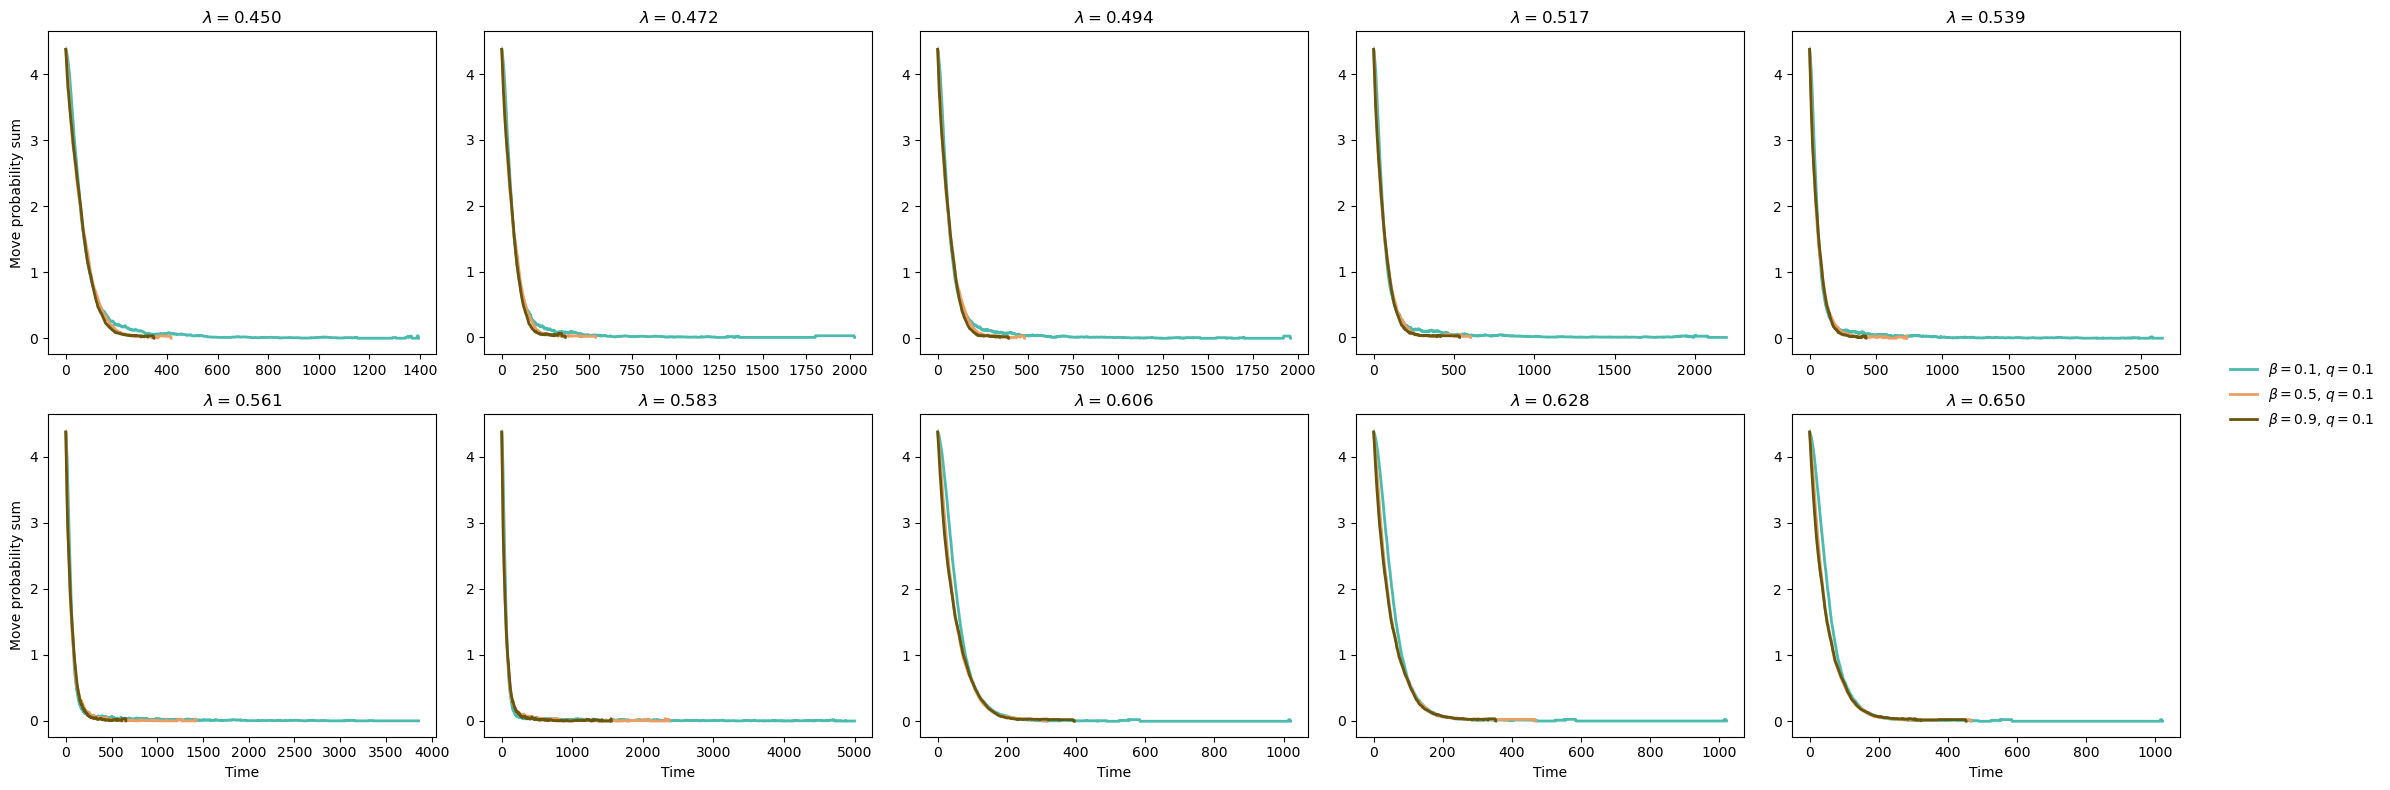

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

def mean_ci_timeseries(trajectories):
    max_len = max(len(x) for x in trajectories)

    data = np.full((len(trajectories), max_len), np.nan)

    for i, tr in enumerate(trajectories):
        data[i, :len(tr)] = tr

    mean = np.nanmean(data, axis=0)

    n = np.sum(~np.isnan(data), axis=0)
    se = np.nanstd(data, axis=0, ddof=1) / np.sqrt(n)

    ci = 1.96 * se
    return mean, ci


betas = np.array([0.1, 0.5, 0.9])
qs = np.array([0.1])

lambdas = np.linspace(0.45, 0.65, 10)

iterations = 20

# load all q files only once
all_results = {}
for q in qs:
    filename = (
        f'/scratch/kolokcse/logs_hypergraph/'
        f'lambda/long_2_regular_q_{q}_nonlin.pickle'
    )

    with open(filename, 'rb') as handle:
        all_results[q] = pickle.load(handle)

colors = ['#4abbad', '#ec9d64', '#69550D']   # beta colors
linestyles = ['-', '--', ':']                # q styles

fig, axes = plt.subplots(
    2, 5,
    figsize=(22, 8),
    sharex=False,
    sharey=False
)

axes = axes.flatten()

for lambda_i, lambda_ in enumerate(lambdas):

    ax = axes[lambda_i]

    for beta_i, beta in enumerate(betas):
        for q_i, q in enumerate(qs):

            results_dict = all_results[q]

            move_prob_traj = [
                np.asarray(
                    results_dict[beta_i][lambda_i][i]['move_prob_sum']
                )
                for i in range(iterations)
            ]

            mean_move, ci_move = mean_ci_timeseries(move_prob_traj)

            t = np.arange(len(mean_move))

            ax.plot(
                t,
                mean_move,
                color=colors[beta_i],
                linestyle=linestyles[q_i],
                lw=2,
                label=rf'$\beta={beta},\, q={q}$'
                if lambda_i == 0 else None
            )

            ax.fill_between(
                t,
                mean_move - ci_move,
                mean_move + ci_move,
                color=colors[beta_i],
                alpha=0.08
            )

    ax.set_title(rf'$\lambda={lambda_:.3f}$')

    if lambda_i % 5 == 0:
        ax.set_ylabel('Move probability sum')

    if lambda_i >= 5:
        ax.set_xlabel('Time')

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

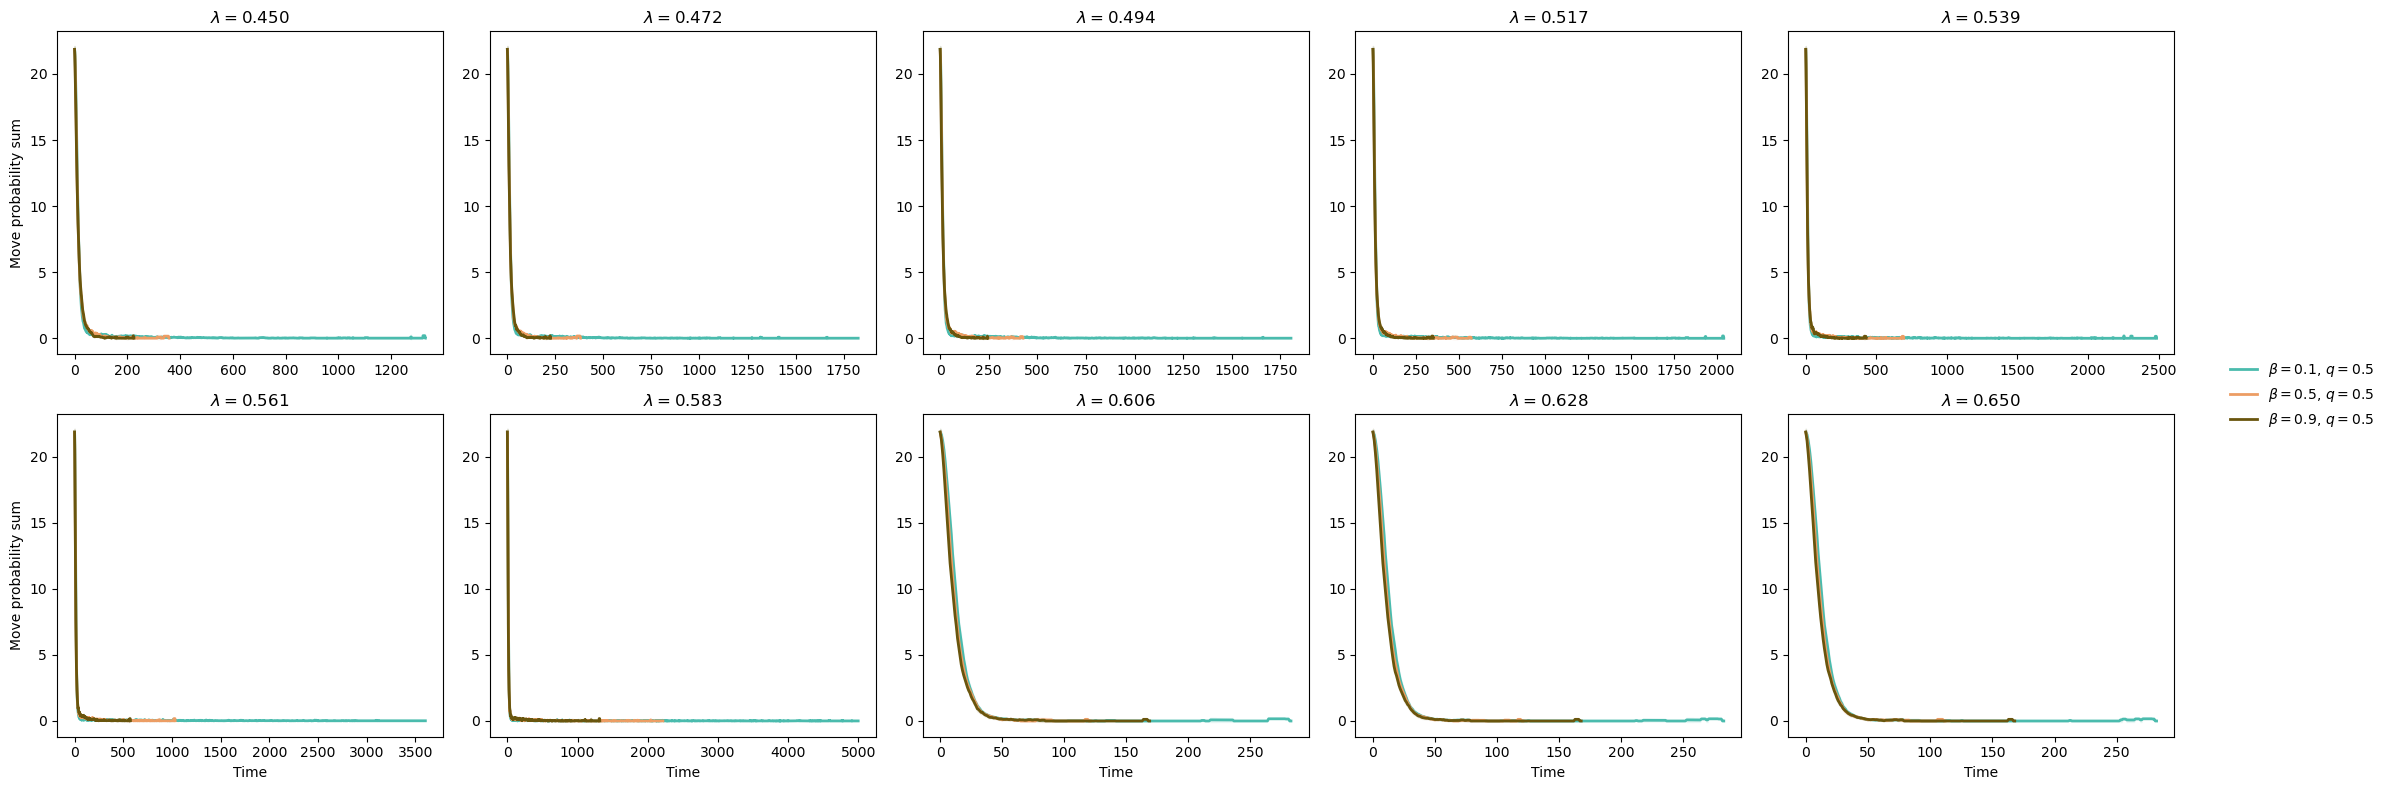

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

def mean_ci_timeseries(trajectories):
    max_len = max(len(x) for x in trajectories)

    data = np.full((len(trajectories), max_len), np.nan)

    for i, tr in enumerate(trajectories):
        data[i, :len(tr)] = tr

    mean = np.nanmean(data, axis=0)

    n = np.sum(~np.isnan(data), axis=0)
    se = np.nanstd(data, axis=0, ddof=1) / np.sqrt(n)

    ci = 1.96 * se
    return mean, ci


betas = np.array([0.1, 0.5, 0.9])
qs = np.array([0.5])

lambdas = np.linspace(0.45, 0.65, 10)

iterations = 20

# load all q files only once
all_results = {}
for q in qs:
    filename = (
        f'/scratch/kolokcse/logs_hypergraph/'
        f'lambda/long_2_regular_q_{q}_nonlin.pickle'
    )

    with open(filename, 'rb') as handle:
        all_results[q] = pickle.load(handle)

colors = ['#4abbad', '#ec9d64', '#69550D']   # beta colors
linestyles = ['-', '--', ':']                # q styles

fig, axes = plt.subplots(
    2, 5,
    figsize=(22, 8),
    sharex=False,
    sharey=False
)

axes = axes.flatten()

for lambda_i, lambda_ in enumerate(lambdas):

    ax = axes[lambda_i]

    for beta_i, beta in enumerate(betas):
        for q_i, q in enumerate(qs):

            results_dict = all_results[q]

            move_prob_traj = [
                np.asarray(
                    results_dict[beta_i][lambda_i][i]['move_prob_sum']
                )
                for i in range(iterations)
            ]

            mean_move, ci_move = mean_ci_timeseries(move_prob_traj)

            t = np.arange(len(mean_move))

            ax.plot(
                t,
                mean_move,
                color=colors[beta_i],
                linestyle=linestyles[q_i],
                lw=2,
                label=rf'$\beta={beta},\, q={q}$'
                if lambda_i == 0 else None
            )

            ax.fill_between(
                t,
                mean_move - ci_move,
                mean_move + ci_move,
                color=colors[beta_i],
                alpha=0.08
            )

    ax.set_title(rf'$\lambda={lambda_:.3f}$')

    if lambda_i % 5 == 0:
        ax.set_ylabel('Move probability sum')

    if lambda_i >= 5:
        ax.set_xlabel('Time')

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

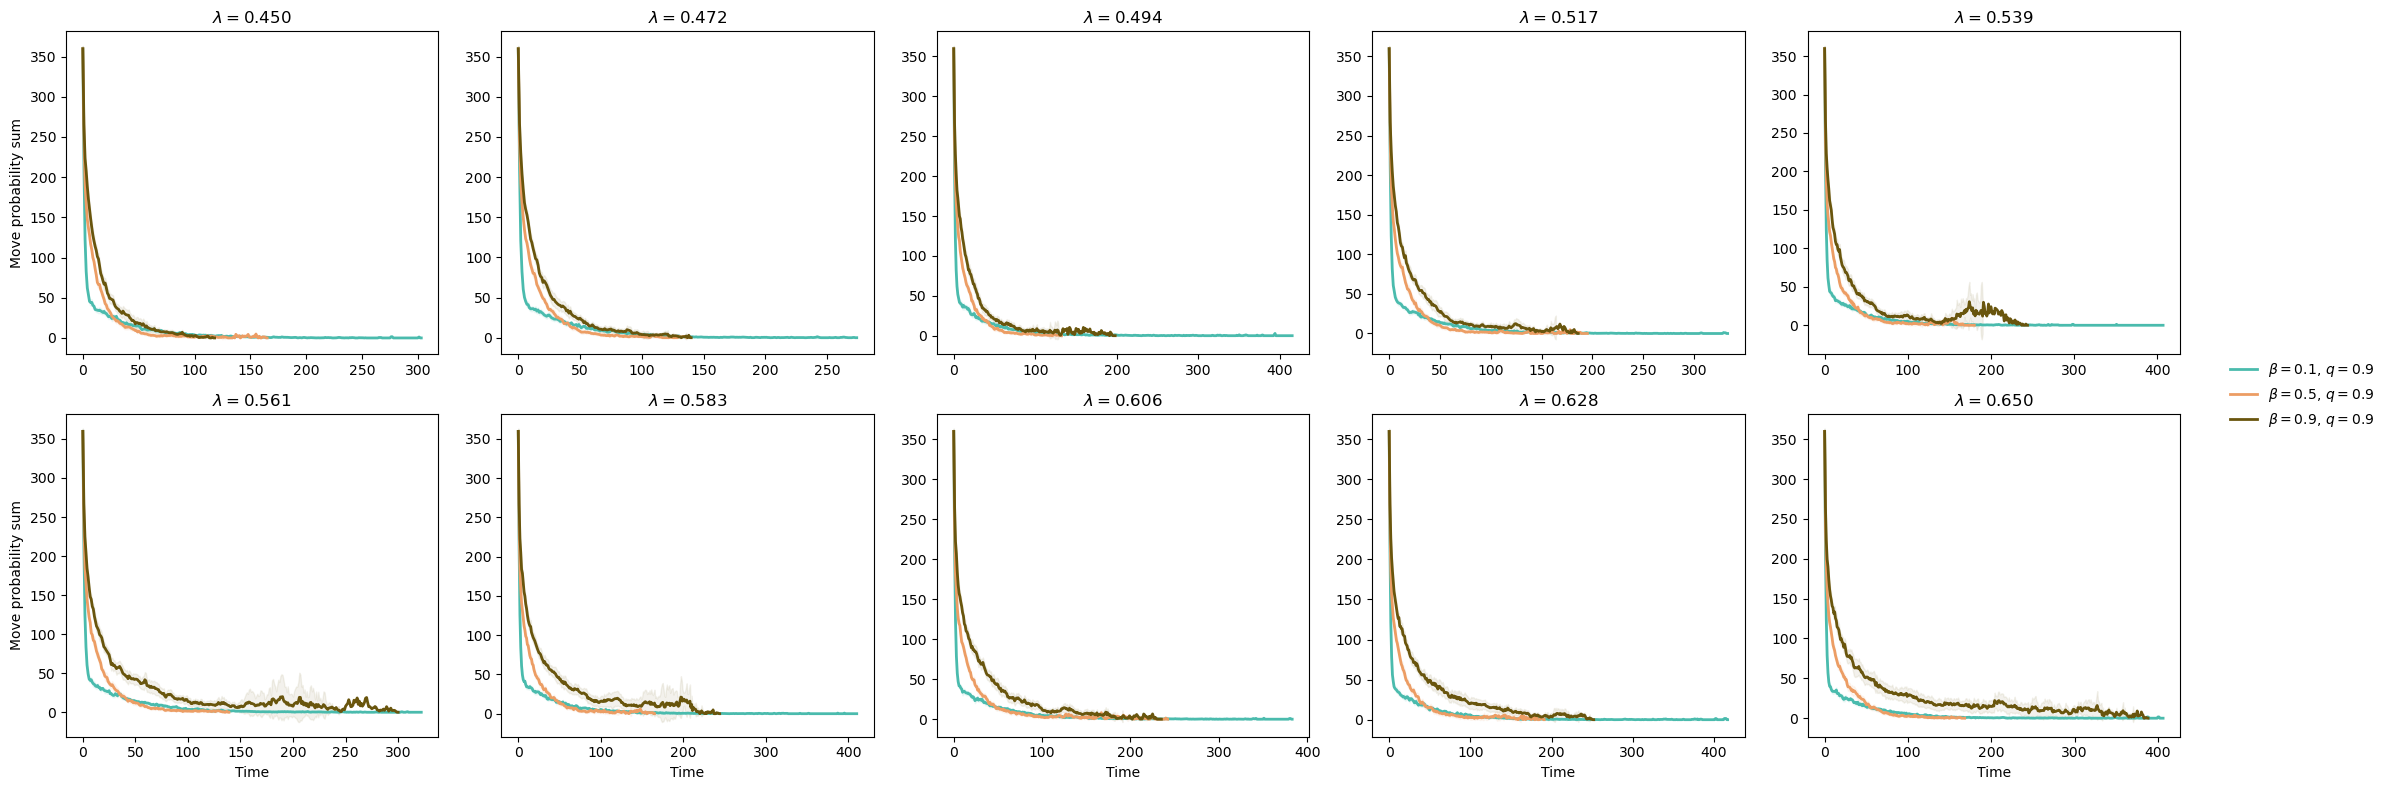

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

def mean_ci_timeseries(trajectories):
    max_len = max(len(x) for x in trajectories)

    data = np.full((len(trajectories), max_len), np.nan)

    for i, tr in enumerate(trajectories):
        data[i, :len(tr)] = tr

    mean = np.nanmean(data, axis=0)

    n = np.sum(~np.isnan(data), axis=0)
    se = np.nanstd(data, axis=0, ddof=1) / np.sqrt(n)

    ci = 1.96 * se
    return mean, ci


betas = np.array([0.1, 0.5, 0.9])
qs = np.array([0.9])

lambdas = np.linspace(0.45, 0.65, 10)

iterations = 20

# load all q files only once
all_results = {}
for q in qs:
    filename = (
        f'/scratch/kolokcse/logs_hypergraph/'
        f'lambda/long_2_regular_q_{q}_lin.pickle'
    )

    with open(filename, 'rb') as handle:
        all_results[q] = pickle.load(handle)

colors = ['#4abbad', '#ec9d64', '#69550D']   # beta colors
linestyles = ['-', '--', ':']                # q styles

fig, axes = plt.subplots(
    2, 5,
    figsize=(22, 8),
    sharex=False,
    sharey=False
)

axes = axes.flatten()

for lambda_i, lambda_ in enumerate(lambdas):

    ax = axes[lambda_i]

    for beta_i, beta in enumerate(betas):
        for q_i, q in enumerate(qs):

            results_dict = all_results[q]

            move_prob_traj = [
                np.asarray(
                    results_dict[beta_i][lambda_i][i]['move_prob_sum']
                )
                for i in range(iterations)
            ]

            mean_move, ci_move = mean_ci_timeseries(move_prob_traj)

            t = np.arange(len(mean_move))

            ax.plot(
                t,
                mean_move,
                color=colors[beta_i],
                linestyle=linestyles[q_i],
                lw=2,
                label=rf'$\beta={beta},\, q={q}$'
                if lambda_i == 0 else None
            )

            ax.fill_between(
                t,
                mean_move - ci_move,
                mean_move + ci_move,
                color=colors[beta_i],
                alpha=0.08
            )

    ax.set_title(rf'$\lambda={lambda_:.3f}$')

    if lambda_i % 5 == 0:
        ax.set_ylabel('Move probability sum')

    if lambda_i >= 5:
        ax.set_xlabel('Time')

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='center left',
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

# R values

In [ ]:
betas=np.array([0.1,0.5,0.9])
qs=np.array([0.1,0.5,0.9])
row_names = ['sum_opinion_A','component_sizes','homophily']


r2s = np.arange(0.1,1,0.1)
homophily_array_hh = np.zeros((3,3,len(r2s)))
homophily_confidance_array_hh = np.zeros((3,3,len(r2s)))

homophily_array_wp = np.zeros((3,3,len(r2s)))
homophily_confidance_array_wp = np.zeros((3,3,len(r2s)))

num_comp_array = np.zeros((3,3,len(r2s)))
num_comp_confidence_array = np.zeros((3,3,len(r2s)))

end_time_array = np.zeros((3,3,len(r2s)))
end_time_confidance_array = np.zeros((3,3,len(r2s)))

for q_i,q in enumerate(qs):
    filename = f'/scratch/kolokcse/logs_hypergraph/r_change/long_2_regular_q_{q}_hhlin.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=100
    for beta_i, beta in enumerate(betas):
        for r2_i, r2 in enumerate(r2s):
            homophily_array_hh[beta_i][q_i][r2_i], homophily_confidance_array_hh[beta_i][q_i][r2_i] = mean_confidence_interval([results_dict[beta_i][r2_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i][r2_i], homophily_confidance_array_wp[beta_i][q_i][r2_i] = mean_confidence_interval([results_dict[beta_i][r2_i][i]['homophily'][-1][1] for i in range(iterations)])           
            num_comp_array[beta_i][q_i][r2_i], num_comp_confidence_array[beta_i][q_i][r2_i] = mean_confidence_interval([len(results_dict[beta_i][r2_i][i]['component_sizes']) for i in range(iterations)])
            end_time_array[beta_i][q_i][r2_i], end_time_confidance_array[beta_i][q_i][r2_i] = mean_confidence_interval([len(results_dict[beta_i][r2_i][i]['sum_opinion_A']) for i in range(iterations)])
plot_homophily_endtime(r2s,r'$r_2$','hhlin_r2_effect', homophily_array_hh, homophily_confidance_array_hh, homophily_array_wp, homophily_confidance_array_wp,num_comp_array,num_comp_confidence_array, end_time_array, end_time_confidance_array, betas, qs, endtimemax=5000)

In [ ]:
betas=np.array([0.1,0.5,0.9])
qs=np.array([0.1,0.5,0.9])
row_names = ['sum_opinion_A','component_sizes','homophily']


r2s = np.arange(0.1,1,0.1)
homophily_array_hh = np.zeros((3,3,len(r2s)))
homophily_confidance_array_hh = np.zeros((3,3,len(r2s)))

homophily_array_wp = np.zeros((3,3,len(r2s)))
homophily_confidance_array_wp = np.zeros((3,3,len(r2s)))

num_comp_array = np.zeros((3,3,len(r2s)))
num_comp_confidence_array = np.zeros((3,3,len(r2s)))

end_time_array = np.zeros((3,3,len(r2s)))
end_time_confidance_array = np.zeros((3,3,len(r2s)))

for q_i,q in enumerate(qs):
    filename = f'/scratch/kolokcse/logs_hypergraph/r_change/long_2_regular_q_{q}_hhnonlin.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=100
    for beta_i, beta in enumerate(betas):
        for r2_i, r2 in enumerate(r2s):
            homophily_array_hh[beta_i][q_i][r2_i], homophily_confidance_array_hh[beta_i][q_i][r2_i] = mean_confidence_interval([results_dict[beta_i][r2_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i][r2_i], homophily_confidance_array_wp[beta_i][q_i][r2_i] = mean_confidence_interval([results_dict[beta_i][r2_i][i]['homophily'][-1][1] for i in range(iterations)])           
            num_comp_array[beta_i][q_i][r2_i], num_comp_confidence_array[beta_i][q_i][r2_i] = mean_confidence_interval([len(results_dict[beta_i][r2_i][i]['component_sizes']) for i in range(iterations)])
            end_time_array[beta_i][q_i][r2_i], end_time_confidance_array[beta_i][q_i][r2_i] = mean_confidence_interval([len(results_dict[beta_i][r2_i][i]['sum_opinion_A']) for i in range(iterations)])
plot_homophily_endtime(r2s,r'$r_2$','hhnonlin_r2_effect', homophily_array_hh, homophily_confidance_array_hh, homophily_array_wp, homophily_confidance_array_wp,num_comp_array,num_comp_confidence_array, end_time_array, end_time_confidance_array, betas, qs, endtimemax=5000)

In [7]:
np.arange(0.45,0.65,10)

array([0.45])

In [6]:



r2s = np.arange(0.05,1.05,0.05)

homophily_array_hh = np.zeros((len(r2s),len(r2s)))
homophily_confidance_array_hh =  np.zeros((len(r2s),len(r2s)))
homophily_array_wp = np.zeros((len(r2s),len(r2s)))
homophily_confidance_array_wp =  np.zeros((len(r2s),len(r2s)))

num_comp_array =  np.zeros((len(r2s),len(r2s)))
num_comp_confidence_array = np.zeros((len(r2s),len(r2s)))

end_time_array =  np.zeros((len(r2s),len(r2s)))
end_time_confidance_array =  np.zeros((len(r2s),len(r2s)))

for r1_i, r1 in enumerate(np.arange(0.05,1.05,0.05)):
    
    filename =f'/scratch/kolokcse/logs_hypergraph/r_change/long_2_regular_r1_{r1}.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)
            
    iterations=20
    for r2_i, r2 in enumerate(r2s):
        homophily_array_hh[r1_i][r2_i], homophily_confidance_array_hh[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][0] for i in range(iterations)])
        homophily_array_wp[r1_i][r2_i], homophily_confidance_array_wp[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][1] for i in range(iterations)])           
        num_comp_array[r1_i][r2_i], num_comp_confidence_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['component_sizes']) for i in range(iterations)])
        end_time_array[r1_i][r2_i], end_time_confidance_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['sum_opinion_A']) for i in range(iterations)])

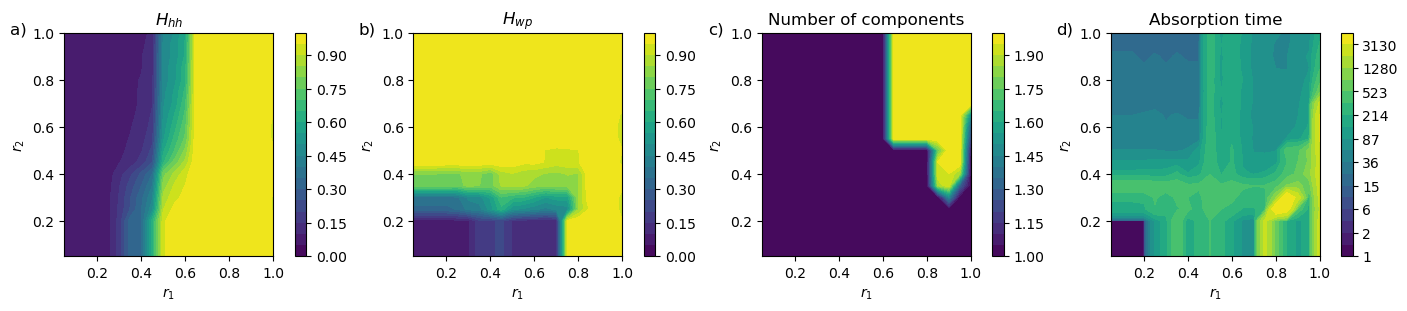

In [9]:
import numpy as np
import matplotlib.pyplot as plt

n = homophily_array_hh.shape[0]

r1s = np.linspace(0.05, 1.0, n)
r2s = np.linspace(0.05, 1.0, n)
R1, R2 = np.meshgrid(r1s, r2s)

fig, axes = plt.subplots(1, 4, figsize=(14, 3), constrained_layout=True)

# Levels
levels_h = np.linspace(0, 1, 21)
levels_c = np.linspace(1, 2, 21)
levels_t = np.logspace(
    np.log10(1),
    np.log10(np.max(end_time_array)),
    20
)


# --- Homophily ---
c0 = axes[0].contourf(
    R1, R2, homophily_array_hh.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[0])
axes[0].set_title(r'$H_{hh}$')
axes[0].set_xlabel(r"$r_1$")
axes[0].set_ylabel(r"$r_2$")

c0 = axes[1].contourf(
    R1, R2, homophily_array_wp.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[1])
axes[1].set_title(r'$H_{wp}$')
axes[1].set_xlabel(r"$r_1$")
axes[1].set_ylabel(r"$r_2$")

# --- Number of components ---
c1 = axes[2].contourf(
    R1, R2, num_comp_array.T,
    levels=levels_c, cmap="viridis"
)
fig.colorbar(c1, ax=axes[2])
axes[2].set_title("Number of components")
axes[2].set_xlabel(r"$r_1$")
axes[2].set_ylabel(r"$r_2$")

# --- Absorption time ---

c2 = axes[3].contourf(
    R1, R2, end_time_array.T,
    levels=levels_t,
    cmap="viridis",
    norm=LogNorm(vmin=levels_t[0], vmax=levels_t[-1])
)

cb = fig.colorbar(c2, ax=axes[3])

axes[3].set_title("Absorption time")
axes[3].set_xlabel(r"$r_1$")
axes[3].set_ylabel(r"$r_2$")


labels = ['a)', 'b)', 'c)', 'd)']

for i, ax in enumerate(axes):
    ax.text(-0.22, 1.05, labels[i], transform=ax.transAxes,ha='center' ,va='top',fontsize=12)
    

plt.savefig('figures/r1_r2.png', dpi = 300)
plt.show()

In [139]:



r2s = np.arange(0.05,1.05,0.05)

homophily_array_hh = np.zeros((len(r2s),len(r2s)))
homophily_confidance_array_hh =  np.zeros((len(r2s),len(r2s)))
homophily_array_wp = np.zeros((len(r2s),len(r2s)))
homophily_confidance_array_wp =  np.zeros((len(r2s),len(r2s)))

num_comp_array =  np.zeros((len(r2s),len(r2s)))
num_comp_confidence_array = np.zeros((len(r2s),len(r2s)))

end_time_array =  np.zeros((len(r2s),len(r2s)))
end_time_confidance_array =  np.zeros((len(r2s),len(r2s)))

for r1_i, r1 in enumerate(np.arange(0.05,1.05,0.05)):
    
    filename =f'/scratch/kolokcse/logs_hypergraph/r_change/long_2_regular_r1_{r1}_q_0.1_beta_0.9.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)
            
    iterations=20
    for r2_i, r2 in enumerate(r2s):
        homophily_array_hh[r1_i][r2_i], homophily_confidance_array_hh[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][0] for i in range(iterations)])
        homophily_array_wp[r1_i][r2_i], homophily_confidance_array_wp[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][1] for i in range(iterations)])           
        num_comp_array[r1_i][r2_i], num_comp_confidence_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['component_sizes']) for i in range(iterations)])
        end_time_array[r1_i][r2_i], end_time_confidance_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['sum_opinion_A']) for i in range(iterations)])

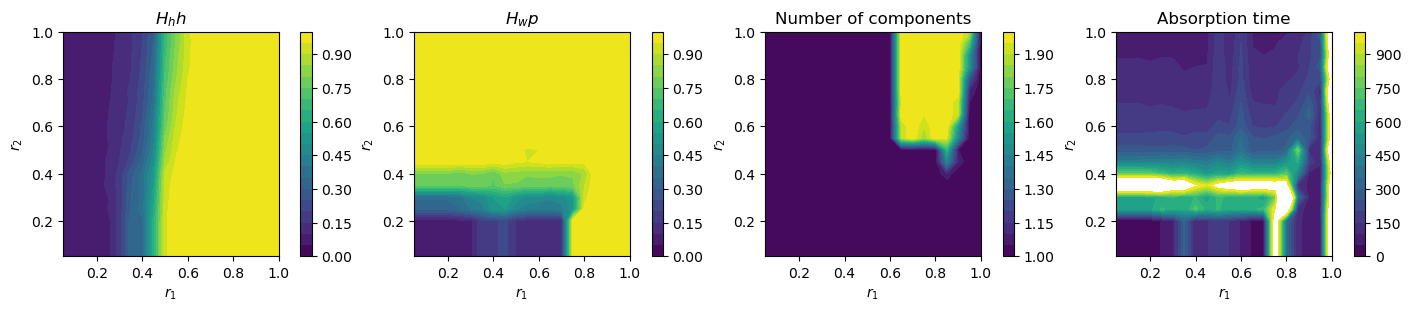

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = homophily_array_hh.shape[0]

r1s = np.linspace(0.05, 1.0, n)
r2s = np.linspace(0.05, 1.0, n)
R1, R2 = np.meshgrid(r1s, r2s)

fig, axes = plt.subplots(1, 4, figsize=(14, 3), constrained_layout=True)

# Levels
levels_h = np.linspace(0, 1, 21)
levels_c = np.linspace(1, 2, 21)
levels_t = np.linspace(0, 1000, 21)

# --- Homophily ---
c0 = axes[0].contourf(
    R1, R2, homophily_array_hh.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[0])
axes[0].set_title(r'$H_{hh}$')
axes[0].set_xlabel(r"$r_1$")
axes[0].set_ylabel(r"$r_2$")

c0 = axes[1].contourf(
    R1, R2, homophily_array_wp.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[1])
axes[1].set_title(r'$H_{wp}$')
axes[1].set_xlabel(r"$r_1$")
axes[1].set_ylabel(r"$r_2$")

# --- Number of components ---
c1 = axes[2].contourf(
    R1, R2, num_comp_array.T,
    levels=levels_c, cmap="viridis"
)
fig.colorbar(c1, ax=axes[2])
axes[2].set_title("Number of components")
axes[2].set_xlabel(r"$r_1$")
axes[2].set_ylabel(r"$r_2$")

# --- Absorption time ---
c2 = axes[3].contourf(
    R1, R2, end_time_array.T,
    levels=levels_t, cmap="viridis"
)
fig.colorbar(c2, ax=axes[3])
axes[3].set_title("Absorption time")
axes[3].set_xlabel(r"$r_1$")
axes[3].set_ylabel(r"$r_2$")

plt.show()

In [141]:



r2s = np.arange(0.05,1.05,0.05)

homophily_array_hh = np.zeros((len(r2s),len(r2s)))
homophily_confidance_array_hh =  np.zeros((len(r2s),len(r2s)))
homophily_array_wp = np.zeros((len(r2s),len(r2s)))
homophily_confidance_array_wp =  np.zeros((len(r2s),len(r2s)))

num_comp_array =  np.zeros((len(r2s),len(r2s)))
num_comp_confidence_array = np.zeros((len(r2s),len(r2s)))

end_time_array =  np.zeros((len(r2s),len(r2s)))
end_time_confidance_array =  np.zeros((len(r2s),len(r2s)))

for r1_i, r1 in enumerate(np.arange(0.05,1.05,0.05)):
    
    filename =f'/scratch/kolokcse/logs_hypergraph/r_change/long_2_regular_r1_{r1}_q_0.9_beta_0.1.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)
            
    iterations=20
    for r2_i, r2 in enumerate(r2s):
        homophily_array_hh[r1_i][r2_i], homophily_confidance_array_hh[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][0] for i in range(iterations)])
        homophily_array_wp[r1_i][r2_i], homophily_confidance_array_wp[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][1] for i in range(iterations)])           
        num_comp_array[r1_i][r2_i], num_comp_confidence_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['component_sizes']) for i in range(iterations)])
        end_time_array[r1_i][r2_i], end_time_confidance_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['sum_opinion_A']) for i in range(iterations)])

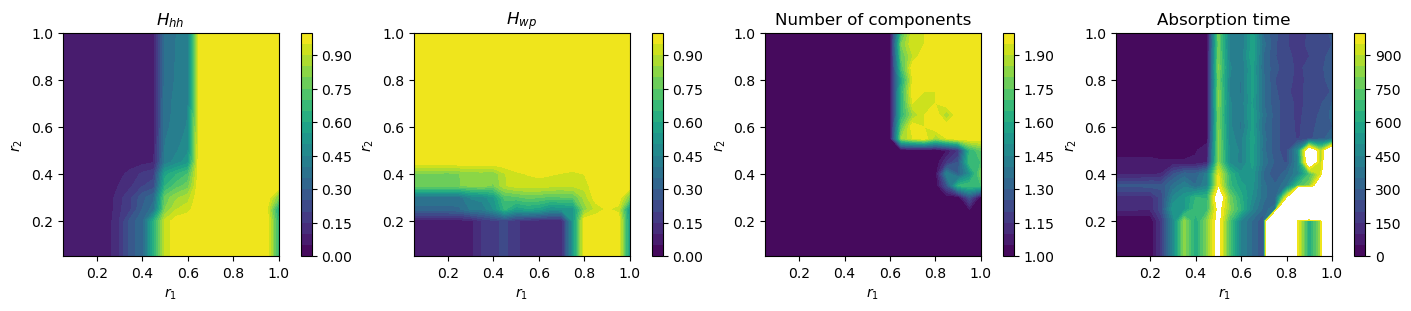

In [143]:
import numpy as np
import matplotlib.pyplot as plt

n = homophily_array_hh.shape[0]

r1s = np.linspace(0.05, 1.0, n)
r2s = np.linspace(0.05, 1.0, n)
R1, R2 = np.meshgrid(r1s, r2s)

fig, axes = plt.subplots(1, 4, figsize=(14, 3), constrained_layout=True)

# Levels
levels_h = np.linspace(0, 1, 21)
levels_c = np.linspace(1, 2, 21)
levels_t = np.linspace(0, 1000, 21)

# --- Homophily ---
c0 = axes[0].contourf(
    R1, R2, homophily_array_hh.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[0])
axes[0].set_title(r'$H_{hh}$')
axes[0].set_xlabel(r"$r_1$")
axes[0].set_ylabel(r"$r_2$")

c0 = axes[1].contourf(
    R1, R2, homophily_array_wp.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[1])
axes[1].set_title(r'$H_{wp}$')
axes[1].set_xlabel(r"$r_1$")
axes[1].set_ylabel(r"$r_2$")

# --- Number of components ---
c1 = axes[2].contourf(
    R1, R2, num_comp_array.T,
    levels=levels_c, cmap="viridis"
)
fig.colorbar(c1, ax=axes[2])
axes[2].set_title("Number of components")
axes[2].set_xlabel(r"$r_1$")
axes[2].set_ylabel(r"$r_2$")

# --- Absorption time ---
c2 = axes[3].contourf(
    R1, R2, end_time_array.T,
    levels=levels_t, cmap="viridis"
)
fig.colorbar(c2, ax=axes[3])
axes[3].set_title("Absorption time")
axes[3].set_xlabel(r"$r_1$")
axes[3].set_ylabel(r"$r_2$")

plt.show()

Processing n=100


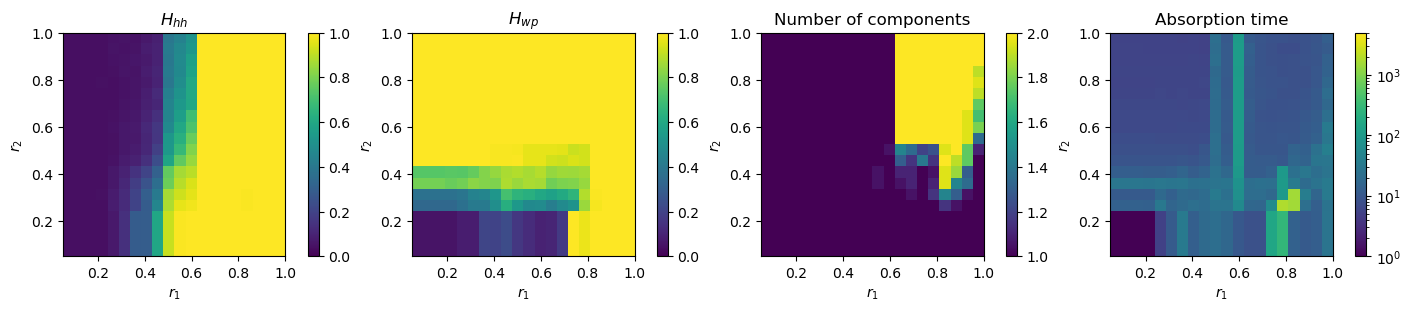

Processing n=500


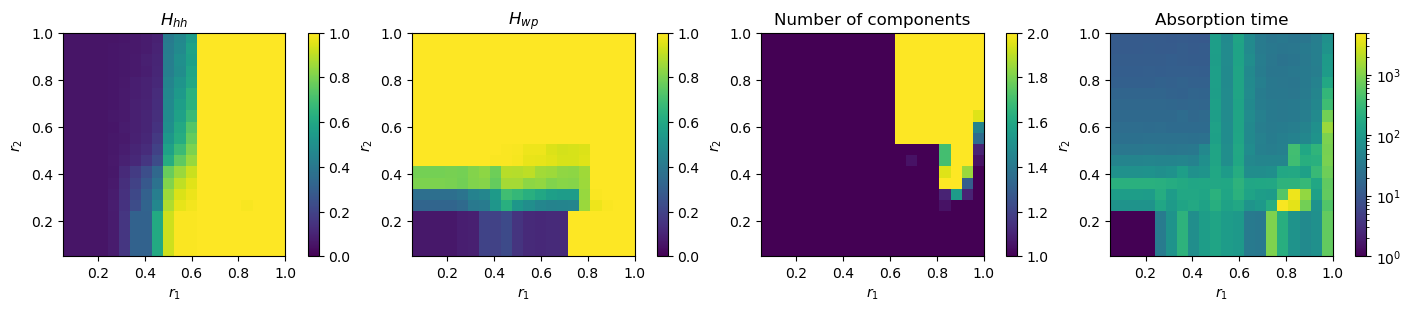

Processing n=2000


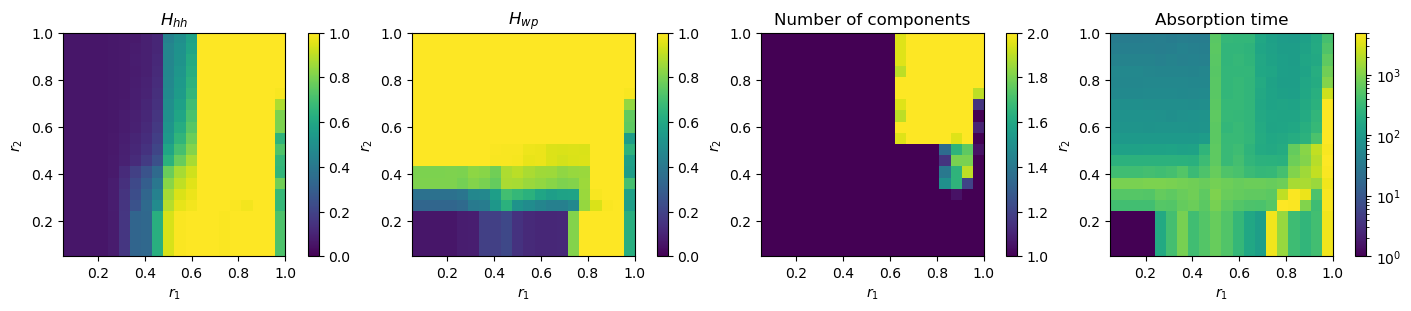

In [11]:




for n in [100, 500, 2000]:
    print(f"Processing n={n}")
    r2s = np.arange(0.05,1.05,0.05)

    homophily_array_hh = np.zeros((len(r2s),len(r2s)))
    homophily_confidance_array_hh =  np.zeros((len(r2s),len(r2s)))
    homophily_array_wp = np.zeros((len(r2s),len(r2s)))
    homophily_confidance_array_wp =  np.zeros((len(r2s),len(r2s)))

    num_comp_array =  np.zeros((len(r2s),len(r2s)))
    num_comp_confidence_array = np.zeros((len(r2s),len(r2s)))

    end_time_array =  np.zeros((len(r2s),len(r2s)))
    end_time_confidance_array =  np.zeros((len(r2s),len(r2s)))

    for r1_i, r1 in enumerate(np.arange(0.05,1.05,0.05)):
        
        filename =f'/scratch/kolokcse/logs_hypergraph/r_change/long_2_regular_r1_{r1}_q_{0.5}_beta_{0.5}_n_{n}.pickle'
        with open(filename, 'rb') as handle:
                results_dict = pickle.load(handle)
                
        iterations=20
        for r2_i, r2 in enumerate(r2s):
            homophily_array_hh[r1_i][r2_i], homophily_confidance_array_hh[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[r1_i][r2_i], homophily_confidance_array_wp[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][1] for i in range(iterations)])           
            num_comp_array[r1_i][r2_i], num_comp_confidence_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['component_sizes']) for i in range(iterations)])
            end_time_array[r1_i][r2_i], end_time_confidance_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['sum_opinion_A']) for i in range(iterations)])
            

    
    size= homophily_array_hh.shape[0]

    r1s = np.linspace(0.05, 1.0, size)
    r2s = np.linspace(0.05, 1.0, size)
    R1, R2 = np.meshgrid(r1s, r2s)

    fig, axes = plt.subplots(1, 4, figsize=(14, 3), constrained_layout=True)

    # Levels
    levels_h = np.linspace(0, 1, 21)
    levels_c = np.linspace(1, 2, 21)
    levels_t = np.linspace(0, 1000, 21)

    # --- Homophily ---
    c0 = axes[0].imshow(
    homophily_array_hh.T,
    origin="lower",
    extent=[0.05, 1.0, 0.05, 1.0],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
    )

    fig.colorbar(c0, ax=axes[0])
    axes[0].set_title(r'$H_{hh}$')
    axes[0].set_xlabel(r"$r_1$")
    axes[0].set_ylabel(r"$r_2$")

    c0 =  axes[1].imshow(
    homophily_array_wp.T,
    origin="lower",
    extent=[0.05, 1.0, 0.05, 1.0],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
    )

    fig.colorbar(c0, ax=axes[1])
    axes[1].set_title(r'$H_{wp}$')
    axes[1].set_xlabel(r"$r_1$")
    axes[1].set_ylabel(r"$r_2$")

    # --- Number of components ---
    c1 = axes[2].imshow(
    num_comp_array.T,
    origin="lower",
    extent=[0.05, 1.0, 0.05, 1.0],
    aspect="auto",
    cmap="viridis",
    vmin=1,
    vmax=2
)

    fig.colorbar(c1, ax=axes[2])
    axes[2].set_title("Number of components")
    axes[2].set_xlabel(r"$r_1$")
    axes[2].set_ylabel(r"$r_2$")

    # --- Absorption time ---
    c2 = axes[3].imshow(
        end_time_array.T,
        origin="lower",
        extent=[0.05, 1.0, 0.05, 1.0],
        aspect="auto",
        cmap="viridis",
        norm=LogNorm(vmin=1, vmax=5000)
    )
    fig.colorbar(c2, ax=axes[3])
    axes[3].set_title("Absorption time")
    axes[3].set_xlabel(r"$r_1$")
    axes[3].set_ylabel(r"$r_2$")

    plt.show()

In [13]:
np.random.normal(5, 1,10)

array([4.92080608, 5.37782323, 5.43824121, 5.13890663, 5.6048771 ,
       5.58692863, 3.5898837 , 4.76409984, 4.72386598, 6.87641914])

Processing n=10


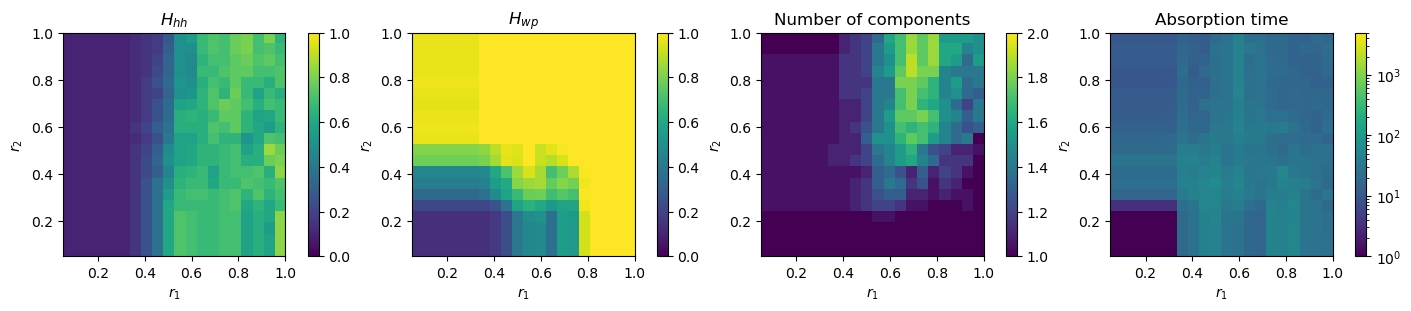

Processing n=100


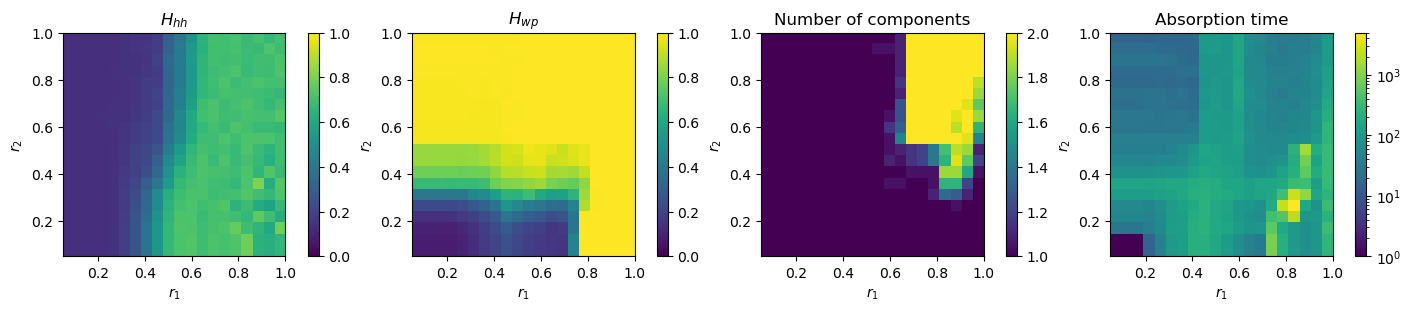

In [14]:




for n in [10,100]:
    print(f"Processing n={n}")
    r2s = np.arange(0.05,1.05,0.05)

    homophily_array_hh = np.zeros((len(r2s),len(r2s)))
    homophily_confidance_array_hh =  np.zeros((len(r2s),len(r2s)))
    homophily_array_wp = np.zeros((len(r2s),len(r2s)))
    homophily_confidance_array_wp =  np.zeros((len(r2s),len(r2s)))

    num_comp_array =  np.zeros((len(r2s),len(r2s)))
    num_comp_confidence_array = np.zeros((len(r2s),len(r2s)))

    end_time_array =  np.zeros((len(r2s),len(r2s)))
    end_time_confidance_array =  np.zeros((len(r2s),len(r2s)))

    for r1_i, r1 in enumerate(np.arange(0.05,1.05,0.05)):
        
        filename =f'/scratch/kolokcse/logs_hypergraph/r_change/long_2_regular_r1_{r1}_q_{0.5}_beta_{0.5}_n_{n}_binom.pickle'
        with open(filename, 'rb') as handle:
                results_dict = pickle.load(handle)
                
        iterations=20
        for r2_i, r2 in enumerate(r2s):
            homophily_array_hh[r1_i][r2_i], homophily_confidance_array_hh[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][0] for i in range(iterations)])
            homophily_array_wp[r1_i][r2_i], homophily_confidance_array_wp[r1_i][r2_i] = mean_confidence_interval([results_dict[0][r2_i][i]['homophily'][-1][1] for i in range(iterations)])           
            num_comp_array[r1_i][r2_i], num_comp_confidence_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['component_sizes']) for i in range(iterations)])
            end_time_array[r1_i][r2_i], end_time_confidance_array[r1_i][r2_i] = mean_confidence_interval([len(results_dict[0][r2_i][i]['sum_opinion_A']) for i in range(iterations)])
            

    
    size= homophily_array_hh.shape[0]

    r1s = np.linspace(0.05, 1.0, size)
    r2s = np.linspace(0.05, 1.0, size)
    R1, R2 = np.meshgrid(r1s, r2s)

    fig, axes = plt.subplots(1, 4, figsize=(14, 3), constrained_layout=True)

    # Levels
    levels_h = np.linspace(0, 1, 21)
    levels_c = np.linspace(1, 2, 21)
    levels_t = np.linspace(0, 1000, 21)

    # --- Homophily ---
    c0 = axes[0].imshow(
    homophily_array_hh.T,
    origin="lower",
    extent=[0.05, 1.0, 0.05, 1.0],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
    )

    fig.colorbar(c0, ax=axes[0])
    axes[0].set_title(r'$H_{hh}$')
    axes[0].set_xlabel(r"$r_1$")
    axes[0].set_ylabel(r"$r_2$")

    c0 =  axes[1].imshow(
    homophily_array_wp.T,
    origin="lower",
    extent=[0.05, 1.0, 0.05, 1.0],
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
    )

    fig.colorbar(c0, ax=axes[1])
    axes[1].set_title(r'$H_{wp}$')
    axes[1].set_xlabel(r"$r_1$")
    axes[1].set_ylabel(r"$r_2$")

    # --- Number of components ---
    c1 = axes[2].imshow(
    num_comp_array.T,
    origin="lower",
    extent=[0.05, 1.0, 0.05, 1.0],
    aspect="auto",
    cmap="viridis",
    vmin=1,
    vmax=2
)

    fig.colorbar(c1, ax=axes[2])
    axes[2].set_title("Number of components")
    axes[2].set_xlabel(r"$r_1$")
    axes[2].set_ylabel(r"$r_2$")

    # --- Absorption time ---
    c2 = axes[3].imshow(
        end_time_array.T,
        origin="lower",
        extent=[0.05, 1.0, 0.05, 1.0],
        aspect="auto",
        cmap="viridis",
        norm=LogNorm(vmin=1, vmax=5000)
    )
    fig.colorbar(c2, ax=axes[3])
    axes[3].set_title("Absorption time")
    axes[3].set_xlabel(r"$r_1$")
    axes[3].set_ylabel(r"$r_2$")

    plt.show()

In [11]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp','move_count', 'op_change_count', 'component_sizes', 'component_opinion', 'component_homo','homophily']
filename = '/scratch/kolokcse/logs_hypergraph/majority_move_lin_long_final/long_2_regular_edgesize_5_maj_change_lin.pickle'
with open(filename, 'rb') as handle:
        results_dict = pickle.load(handle)

iterations=500


all_res = []
for beta_i, beta in enumerate(betas):
    all_res.append([])
    for q_i,q in enumerate(qs):
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            for i in range(iterations):
                try:
                    results[row].append(results_dict[beta_i][q_i][i][row])
                except:
                    print(beta_i,q_i,i,row)
        all_res[beta_i].append(results)

In [27]:
homophily_array_hh = np.zeros((len(betas),len(qs)))
homophily_confidance_array_hh =  np.zeros((len(betas),len(qs)))
homophily_array_wp = np.zeros((len(betas),len(qs)))
homophily_confidance_array_wp =  np.zeros((len(betas),len(qs)))

num_comp_array =  np.zeros((len(betas),len(qs)))
num_comp_confidence_array = np.zeros((len(betas),len(qs)))

end_time_array =  np.zeros((len(betas),len(qs)))
end_time_confidance_array =  np.zeros((len(betas),len(qs)))

for beta_i, beta in enumerate(betas):
    for q_i, q in enumerate(qs):
        homophily_array_hh[beta_i][q_i], homophily_confidance_array_hh[beta_i][q_i] = mean_confidence_interval([all_res[beta_i][q_i]['homophily'][i][-1][0] for i in range(iterations)])
        homophily_array_wp[beta_i][q_i], homophily_confidance_array_wp[beta_i][q_i] = mean_confidence_interval([all_res[beta_i][q_i]['homophily'][i][-1][1] for i in range(iterations)])           
        num_comp_array[beta_i][q_i], num_comp_confidence_array[beta_i][q_i] = mean_confidence_interval([len(all_res[beta_i][q_i]['component_sizes'][i]) for i in range(iterations)])
        end_time_array[beta_i][q_i], end_time_confidance_array[beta_i][q_i] = mean_confidence_interval([len(all_res[beta_i][q_i]['sum_opinion_A'][i]) for i in range(iterations)])

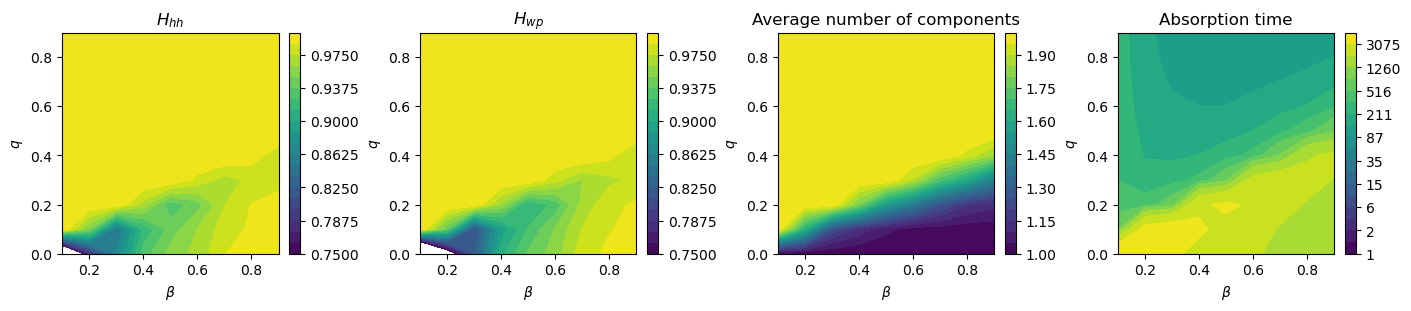

In [29]:
import numpy as np
import matplotlib.pyplot as plt

n = homophily_array_hh.shape[0]

BETA, Q = np.meshgrid(betas, qs)

fig, axes = plt.subplots(1, 4, figsize=(14, 3), constrained_layout=True)

# Levels
levels_h = np.linspace(0.75, 1, 21)
levels_c = np.linspace(1, 2, 21)
levels_t = np.logspace(
    np.log10(1),
    np.log10(np.max(end_time_array)),
    20
)
# --- Homophily ---
c0 = axes[0].contourf(
    BETA, Q, homophily_array_hh.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[0])
axes[0].set_title(r'$H_{hh}$')
axes[0].set_xlabel(r"$\beta$")

axes[0].set_ylabel(r"$q$")

c0 = axes[1].contourf(
    BETA, Q, homophily_array_wp.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[1])
axes[1].set_title(r'$H_{wp}$')
axes[1].set_xlabel(r"$\beta$")
axes[1].set_ylabel(r"$q$")

# --- Number of components ---
c1 = axes[2].contourf(
    BETA, Q, np.min([num_comp_array.T,2*np.ones(num_comp_array.T.shape)], axis=0),
    levels=levels_c, cmap="viridis"
)
fig.colorbar(c1, ax=axes[2])
axes[2].set_title("Average number of components")
axes[2].set_xlabel(r"$\beta$")
axes[2].set_ylabel(r"$q$")

# --- Absorption time ---
c2 = axes[3].contourf(
    BETA, Q, end_time_array.T,
    levels=levels_t,
    cmap="viridis",
    norm=LogNorm(vmin=levels_t[0], vmax=levels_t[-1])
)
fig.colorbar(c2, ax=axes[3])
axes[3].set_title("Absorption time")
axes[3].set_xlabel(r"$\beta$")
axes[3].set_ylabel(r"$q$")

plt.savefig('figures/beta_q_absorption_state.png', dpi = 300)

plt.show()

In [12]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)
row_names = ['sum_opinion_A','binned_opinions_home','binned_opinions_wp','binned_edge_sizes_wp','move_count', 'op_change_count', 'component_sizes', 'component_opinion', 'component_homo','homophily']
filename = '/scratch/kolokcse/logs_hypergraph/majority_move_nonlin_long_final/long_2_regular_edgesize_5_maj_change_nonlin.pickle'
with open(filename, 'rb') as handle:
        results_dict = pickle.load(handle)

iterations=500


all_res_nonlin = []
for beta_i, beta in enumerate(betas):
    all_res_nonlin.append([])
    for q_i,q in enumerate(qs):
        results={}
        for row_i,row in enumerate(row_names):
            results[row]=[]
            for i in range(iterations):
                try:
                    results[row].append(results_dict[beta_i][q_i][i][row])
                except:
                    print(beta_i,q_i,i,row)
        all_res_nonlin[beta_i].append(results)

In [9]:
homophily_array_hh_nonlin = np.zeros((len(betas),len(qs)))
homophily_confidance_array_hh_nonlin =  np.zeros((len(betas),len(qs)))
homophily_array_wp_nonlin = np.zeros((len(betas),len(qs)))
homophily_confidance_array_wp_nonlin =  np.zeros((len(betas),len(qs)))

num_comp_array_nonlin =  np.zeros((len(betas),len(qs)))
num_comp_confidence_array_nonlin = np.zeros((len(betas),len(qs)))

end_time_array_nonlin =  np.zeros((len(betas),len(qs)))
end_time_confidance_array_nonlin =  np.zeros((len(betas),len(qs)))

for beta_i, beta in enumerate(betas):
    for q_i, q in enumerate(qs):
        homophily_array_hh_nonlin[beta_i][q_i], homophily_confidance_array_hh_nonlin[beta_i][q_i] = mean_confidence_interval([all_res_nonlin[beta_i][q_i]['homophily'][i][-1][0] for i in range(iterations)])
        homophily_array_wp_nonlin[beta_i][q_i], homophily_confidance_array_wp_nonlin[beta_i][q_i] = mean_confidence_interval([all_res_nonlin[beta_i][q_i]['homophily'][i][-1][1] for i in range(iterations)])           
        num_comp_array_nonlin[beta_i][q_i], num_comp_confidence_array_nonlin[beta_i][q_i] = mean_confidence_interval([len(all_res_nonlin[beta_i][q_i]['component_sizes'][i]) for i in range(iterations)])
        end_time_array_nonlin[beta_i][q_i], end_time_confidance_array_nonlin[beta_i][q_i] = mean_confidence_interval([len(all_res_nonlin[beta_i][q_i]['sum_opinion_A'][i]) for i in range(iterations)])

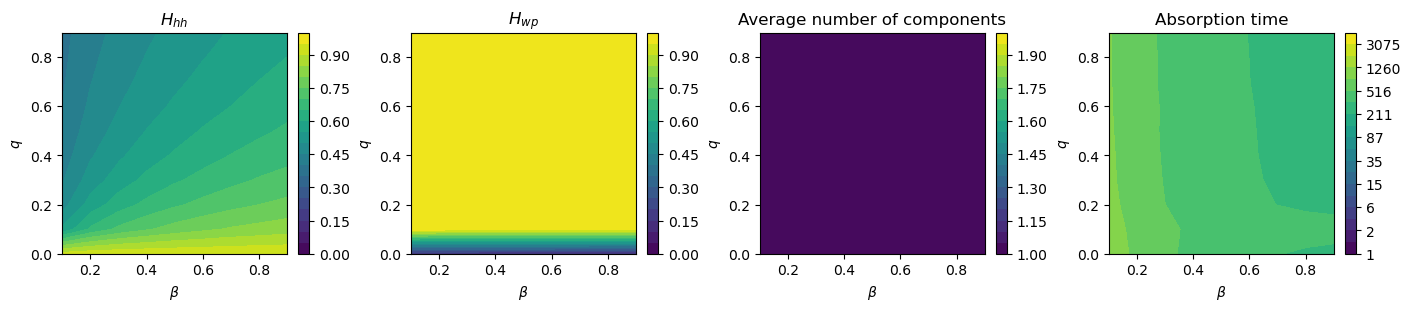

In [29]:
import numpy as np
import matplotlib.pyplot as plt

n = homophily_array_hh.shape[0]

BETA, Q = np.meshgrid(betas, qs)

fig, axes = plt.subplots(1, 4, figsize=(14, 3), constrained_layout=True)


# --- Homophily ---
c0 = axes[0].contourf(
    BETA, Q, homophily_array_hh_nonlin.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[0])
axes[0].set_title(r'$H_{hh}$')
axes[0].set_xlabel(r"$\beta$")

axes[0].set_ylabel(r"$q$")

c0 = axes[1].contourf(
    BETA, Q, homophily_array_wp_nonlin.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c0, ax=axes[1])
axes[1].set_title(r'$H_{wp}$')
axes[1].set_xlabel(r"$\beta$")
axes[1].set_ylabel(r"$q$")

# --- Number of components ---
c1 = axes[2].contourf(
    BETA, Q, np.min([num_comp_array_nonlin.T,2*np.ones(num_comp_array_nonlin.T.shape)], axis=0),
    levels=levels_c, cmap="viridis"
)
fig.colorbar(c1, ax=axes[2])
axes[2].set_title("Average number of components")
axes[2].set_xlabel(r"$\beta$")
axes[2].set_ylabel(r"$q$")

# --- Absorption time ---
c2 = axes[3].contourf(
    BETA, Q, end_time_array_nonlin.T,
    levels=levels_t,
    cmap="viridis",
    norm=LogNorm(vmin=levels_t[0], vmax=levels_t[-1])
)
fig.colorbar(c2, ax=axes[3])
axes[3].set_title("Absorption time")
axes[3].set_xlabel(r"$\beta$")
axes[3].set_ylabel(r"$q$")

plt.savefig('figures/beta_q_absorption_state_nonlin.png', dpi = 300)

plt.show()

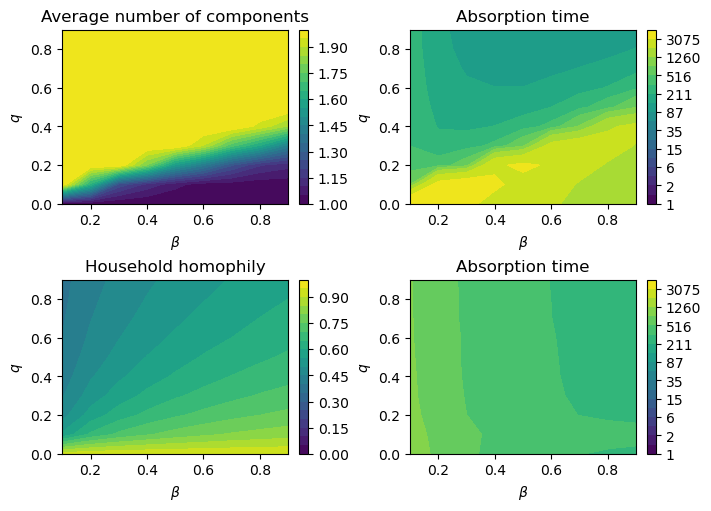

In [12]:
n = homophily_array_hh.shape[0]

BETA, Q = np.meshgrid(betas, qs)

fig, axes = plt.subplots(2, 2, figsize=(7,5), constrained_layout=True)


# --- Number of components ---
c1 = axes[0,0].contourf(
    BETA, Q, np.min([num_comp_array.T,2*np.ones(num_comp_array.T.shape)], axis=0),
    levels=levels_c, cmap="viridis"
)
fig.colorbar(c1, ax=axes[0,0])
axes[0,0].set_title("Average number of components")
axes[0,0].set_xlabel(r"$\beta$")
axes[0,0].set_ylabel(r"$q$")

#--Houshold homophily
axes[1,0].set_title("Household homophily")
c1 = axes[1,0].contourf(
    BETA, Q, homophily_array_hh_nonlin.T,
    levels=levels_h, cmap="viridis"
)
fig.colorbar(c1, ax=axes[1,0])

axes[1,0].set_xlabel(r"$\beta$")
axes[1,0].set_ylabel(r"$q$")



# --- Absorption time ---

c2 = axes[0,1].contourf(
    BETA, Q, end_time_array.T,
    levels=levels_t,
    cmap="viridis",
    norm=LogNorm(vmin=levels_t[0], vmax=levels_t[-1])
)
fig.colorbar(c2, ax=axes[0,1])
axes[0,1].set_title("Absorption time")
axes[0,1].set_xlabel(r"$\beta$")
axes[0,1].set_ylabel(r"$q$")

c2 = axes[1,1].contourf(
    BETA, Q, end_time_array_nonlin.T,
    levels=levels_t,
    cmap="viridis",
    norm=LogNorm(vmin=levels_t[0], vmax=levels_t[-1])
)
fig.colorbar(c2, ax=axes[1,1])
axes[1,1].set_title("Absorption time")
axes[1,1].set_xlabel(r"$\beta$")
axes[1,1].set_ylabel(r"$q$")

plt.savefig('figures/beta_q_absorption_state_2x2.pdf')

plt.show()

In [14]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)

homophily_array_hh = np.zeros((len(betas),len(qs)))
homophily_confidance_array_hh =  np.zeros((len(betas),len(qs)))
homophily_array_wp = np.zeros((len(betas),len(qs)))
homophily_confidance_array_wp =  np.zeros((len(betas),len(qs)))

num_comp_array =  np.zeros((len(betas),len(qs)))
num_comp_confidence_array = np.zeros((len(betas),len(qs)))

end_time_array =  np.zeros((len(betas),len(qs)))
end_time_confidance_array =  np.zeros((len(betas),len(qs)))

for beta_i, beta in enumerate(betas):
    for q_i, q in enumerate(qs):
        homophily_array_hh[beta_i][q_i], homophily_confidance_array_hh[beta_i][q_i] = mean_confidence_interval([all_res[beta_i][q_i]['homophily'][i][-1][0] for i in range(iterations)])
        homophily_array_wp[beta_i][q_i], homophily_confidance_array_wp[beta_i][q_i] = mean_confidence_interval([all_res[beta_i][q_i]['homophily'][i][-1][1] for i in range(iterations)])           
        num_comp_array[beta_i][q_i], num_comp_confidence_array[beta_i][q_i] = mean_confidence_interval([len(all_res[beta_i][q_i]['component_sizes'][i]) for i in range(iterations)])
        end_time_array[beta_i][q_i], end_time_confidance_array[beta_i][q_i] = mean_confidence_interval([len(all_res[beta_i][q_i]['sum_opinion_A'][i]) for i in range(iterations)])

/tmp/ipykernel_827793/125073790.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.75, 1])


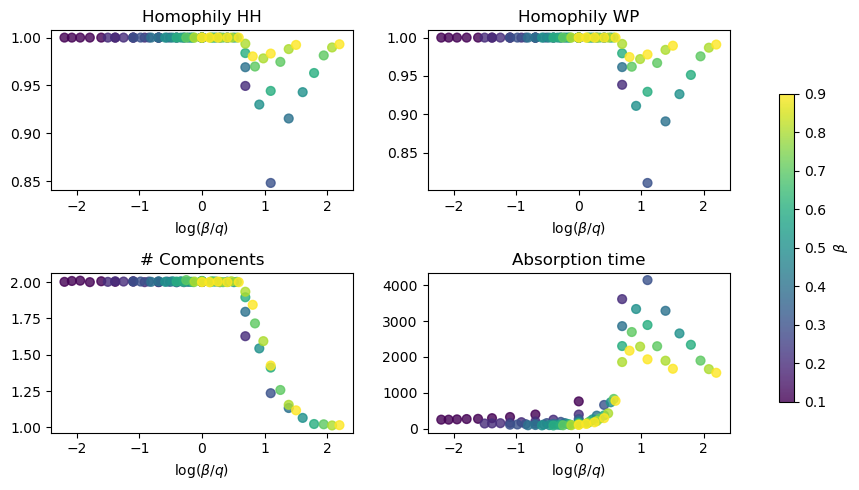

In [28]:
import numpy as np
import matplotlib.pyplot as plt

x = []
hom_hh = []
hom_wp = []
ncomp = []
etime = []
beta_vals = []

for beta_i, beta in enumerate(betas):
    for q_i, q in enumerate(qs):

        if q == 0:
            continue

        x.append(np.log(beta/q))
        beta_vals.append(beta)

        hom_hh.append(homophily_array_hh[beta_i, q_i])
        hom_wp.append(homophily_array_wp[beta_i, q_i])
        ncomp.append(num_comp_array[beta_i, q_i])
        etime.append(end_time_array[beta_i, q_i])

x = np.array(x)
beta_vals = np.array(beta_vals)

fig, axs = plt.subplots(2, 2, figsize=(10,5))

for ax, y, title in zip(
    axs.ravel(),
    [hom_hh, hom_wp, ncomp, etime],
    ["Homophily HH", "Homophily WP",
     "# Components", "Absorption time"]
):

    sc = ax.scatter(
        x, y,
        c=beta_vals,
        cmap="viridis",
        s=40,
        alpha=0.8
    )
    ax.set_xlabel(r'$\log(\beta/q)$')
    ax.set_title(title)

fig.colorbar(sc, ax=axs, shrink=0.8, label=r'$\beta$')
plt.tight_layout(rect=[0, 0, 0.75, 1])
plt.show()

###################################
Processing h_size=10
Max workplace size: 6.78 for beta=0.1 and q=0.30000000000000004
Max absorption time: 90.3 for beta=0.1 and q=0.0


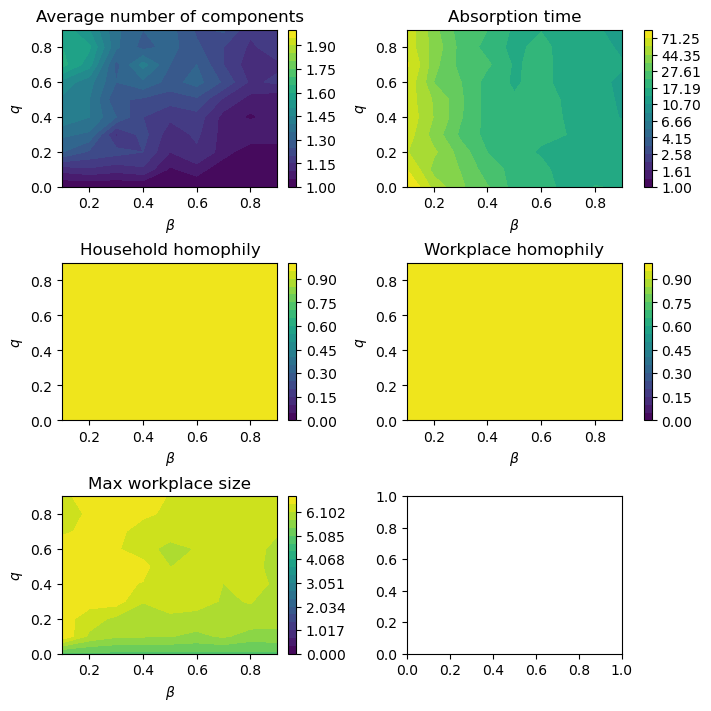

###################################
Processing h_size=20
Max workplace size: 9.22 for beta=0.5 and q=0.8
Max absorption time: 230.86 for beta=0.1 and q=0.0


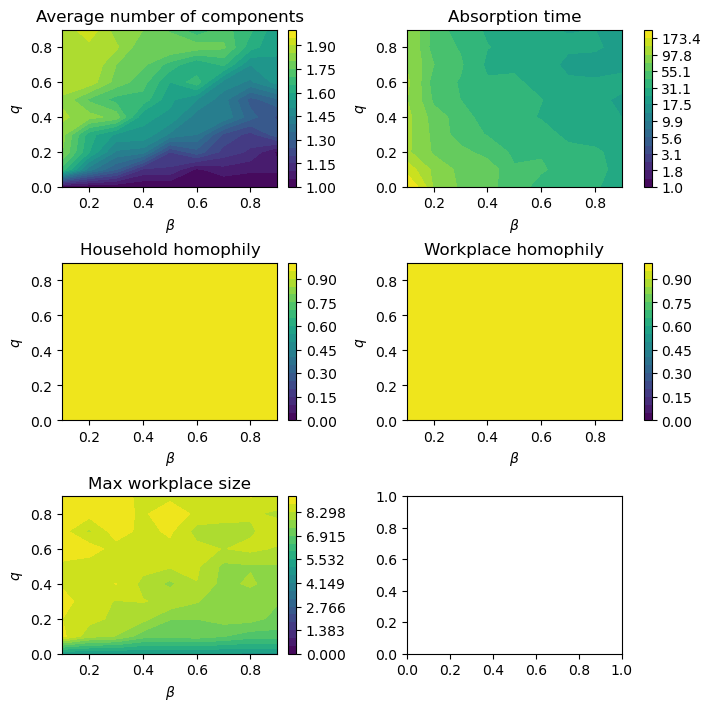

###################################
Processing h_size=30
Max workplace size: 10.48 for beta=0.1 and q=0.2
Max absorption time: 351.82 for beta=0.1 and q=0.0


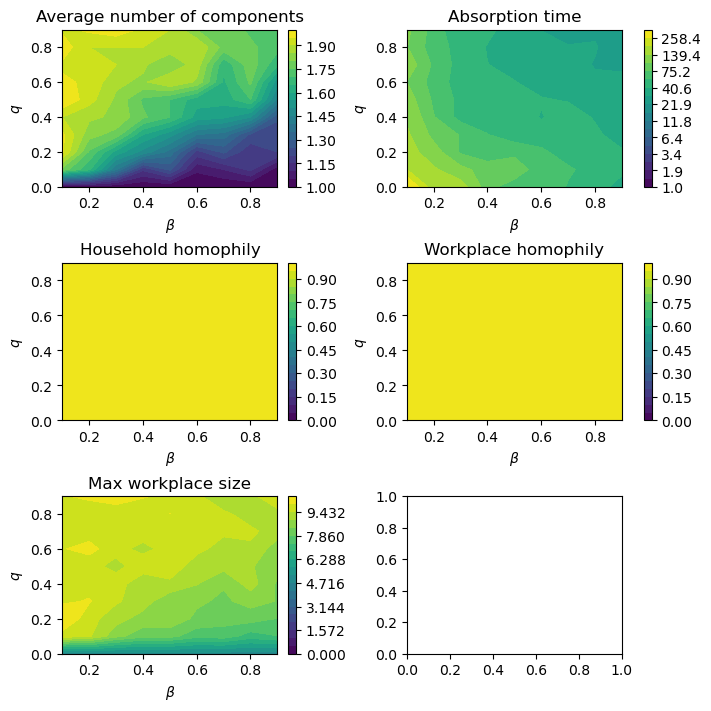

###################################
Processing h_size=100
Max workplace size: 12.48 for beta=0.4 and q=0.9
Max absorption time: 997.16 for beta=0.1 and q=0.0


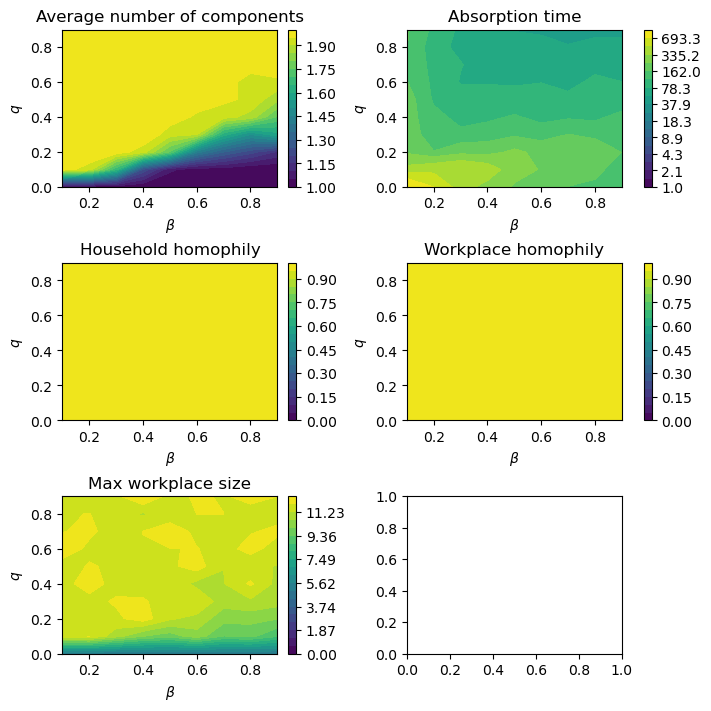

In [7]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)

# Levels
levels_h = np.linspace(0, 1, 21)
levels_c = np.linspace(1, 2, 21)

mean_max_workplace_size_per_hsize_lin =  []
mean_absorption_time_per_hsize_lin =  []


row_names = ['sum_opinion_A','component_sizes','homophily', 'max_workplace_size']
for h_size in [10,20,30,100]:
    filename = f'/scratch/kolokcse/logs_hypergraph/majority_move_lin_long_final/long_2_regular_edgesize_5_lin_n_{h_size}.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=50


    all_res_lin = []
    for beta_i, beta in enumerate(betas):
        all_res_lin.append([])
        for q_i,q in enumerate(qs):
            results={}
            for row_i,row in enumerate(row_names):
                results[row]=[]
                for i in range(iterations):
                    try:
                        results[row].append(results_dict[beta_i][q_i][i][row])
                    except:
                        print(beta_i,q_i,i,row)
            all_res_lin[beta_i].append(results)
            
    
    homophily_array_hh = np.zeros((len(betas),len(qs)))
    homophily_confidance_array_hh =  np.zeros((len(betas),len(qs)))
    homophily_array_wp = np.zeros((len(betas),len(qs)))
    homophily_confidance_array_wp =  np.zeros((len(betas),len(qs)))

    num_comp_array =  np.zeros((len(betas),len(qs)))
    num_comp_confidence_array = np.zeros((len(betas),len(qs)))

    end_time_array =  np.zeros((len(betas),len(qs)))
    end_time_confidance_array =  np.zeros((len(betas),len(qs)))

    max_workplace_size_array =  np.zeros((len(betas),len(qs)))

    for beta_i, beta in enumerate(betas):
        for q_i, q in enumerate(qs):
            homophily_array_hh[beta_i][q_i], homophily_confidance_array_hh[beta_i][q_i] = mean_confidence_interval([all_res_lin[beta_i][q_i]['homophily'][i][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i], homophily_confidance_array_wp[beta_i][q_i] = mean_confidence_interval([all_res_lin[beta_i][q_i]['homophily'][i][-1][1] for i in range(iterations)])           
            num_comp_array[beta_i][q_i], num_comp_confidence_array[beta_i][q_i] = mean_confidence_interval([len(all_res_lin[beta_i][q_i]['component_sizes'][i]) for i in range(iterations)])
            end_time_array[beta_i][q_i], end_time_confidance_array[beta_i][q_i] = mean_confidence_interval([len(all_res_lin[beta_i][q_i]['sum_opinion_A'][i]) for i in range(iterations)])
            max_workplace_size_array[beta_i][q_i] = np.mean([all_res_lin[beta_i][q_i]['max_workplace_size'][i][-1] for i in range(iterations)])
    mean_max_workplace_size_per_hsize_lin.append(max_workplace_size_array)
    mean_absorption_time_per_hsize_lin.append(end_time_array)
        
            
    n = homophily_array_hh.shape[0]
    print('###################################')
    print(f"Processing h_size={h_size}")
    print(f"Max workplace size: {np.max(max_workplace_size_array)} for beta={betas[np.argmax(max_workplace_size_array)//len(qs)]} and q={qs[np.argmax(max_workplace_size_array)%len(qs)]}")
    print(f"Max absorption time: {np.max(end_time_array)} for beta={betas[np.argmax(end_time_array)//len(qs)]} and q={qs[np.argmax(end_time_array)%len(qs)]}")
    BETA, Q = np.meshgrid(betas, qs)

    fig, axes = plt.subplots(3, 2, figsize=(7,7), constrained_layout=True)


    # --- Number of components ---
    c1 = axes[0,0].contourf(
        BETA, Q, np.min([num_comp_array.T,2*np.ones(num_comp_array.T.shape)], axis=0),
        levels=levels_c, cmap="viridis"
    )
    fig.colorbar(c1, ax=axes[0,0])
    axes[0,0].set_title("Average number of components")
    axes[0,0].set_xlabel(r"$\beta$")
    axes[0,0].set_ylabel(r"$q$")

    #--Houshold homophily
    axes[1,0].set_title("Household homophily")
    c1 = axes[1,0].contourf(
        BETA, Q, homophily_array_hh.T,
        levels=levels_h, cmap="viridis"
    )
    fig.colorbar(c1, ax=axes[1,0])

    axes[1,0].set_xlabel(r"$\beta$")
    axes[1,0].set_ylabel(r"$q$")

    # --- Absorption time ---
    levels_t = np.logspace(
    np.log10(1),
    np.log10(np.max(end_time_array)),
    20
    )
    c2 = axes[0,1].contourf(
        BETA, Q, end_time_array.T,
        levels=levels_t,
        cmap="viridis",
        norm=LogNorm(vmin=levels_t[0], vmax=levels_t[-1])
    )
    fig.colorbar(c2, ax=axes[0,1])
    axes[0,1].set_title("Absorption time")
    axes[0,1].set_xlabel(r"$\beta$")
    axes[0,1].set_ylabel(r"$q$")

    c2 = axes[1,1].contourf(
        BETA, Q, homophily_array_wp.T,
        levels=levels_h,
        cmap="viridis"
    )
    fig.colorbar(c2, ax=axes[1,1])
    axes[1,1].set_title("Workplace homophily")
    axes[1,1].set_xlabel(r"$\beta$")
    axes[1,1].set_ylabel(r"$q$")
    
    axes[2,0].set_title("Max workplace size")
    c2 = axes[2,0].contourf(
        BETA, Q, max_workplace_size_array.T,
        levels=np.linspace(0, np.max(max_workplace_size_array), 21),
        cmap="viridis"
    )
    fig.colorbar(c2, ax=axes[2,0])
    axes[2,0].set_xlabel(r"$\beta$")
    axes[2,0].set_ylabel(r"$q$")

    plt.show()

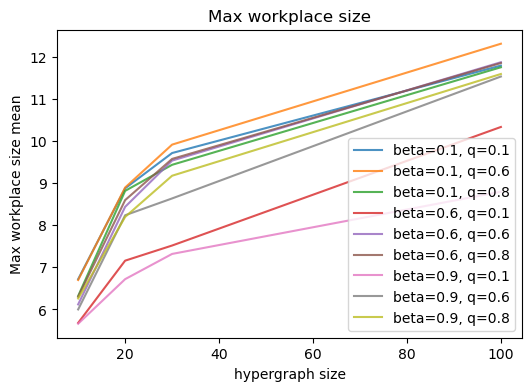

In [ ]:

plt.figure(figsize=(6,4))
for beta_i in [0,5,8]:
    for q_i in [1,6,8]:
        plt.plot([10,20,30,100], [mean_max_workplace_size_per_hsize_lin[i][beta_i][q_i] for i in range(4)], alpha=0.8, label=f"beta={betas[beta_i]:.1f}, q={qs[q_i]:.1f}")
plt.title(f"Mean Max workplace size")
plt.xlabel("hypergraph size")
plt.ylabel("Mean Max workplace size")
plt.legend()
plt.show()

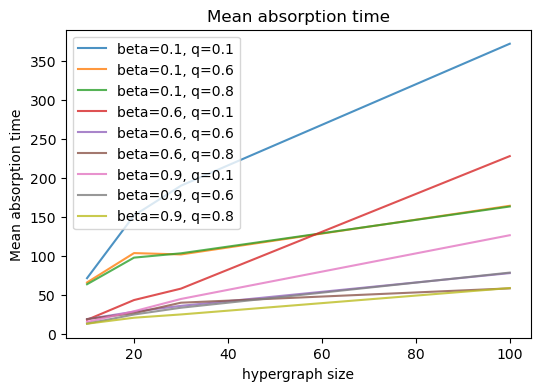

In [25]:

plt.figure(figsize=(6,4))
for beta_i in [0,5,8]:
    for q_i in [1,6,8]:
        plt.plot([10,20,30,100], [mean_absorption_time_per_hsize_lin[i][beta_i][q_i] for i in range(4)], alpha=0.8, label=f"beta={betas[beta_i]:.1f}, q={qs[q_i]:.1f}")
plt.title(f"Mean absorption time")
plt.xlabel("hypergraph size")
plt.ylabel("Mean absorption time")
plt.legend()
plt.show()

###################################
Processing h_size=10
Max workplace size: 7.0 for beta=0.1 and q=0.1
Max absorption time: 135.78 for beta=0.1 and q=0.0


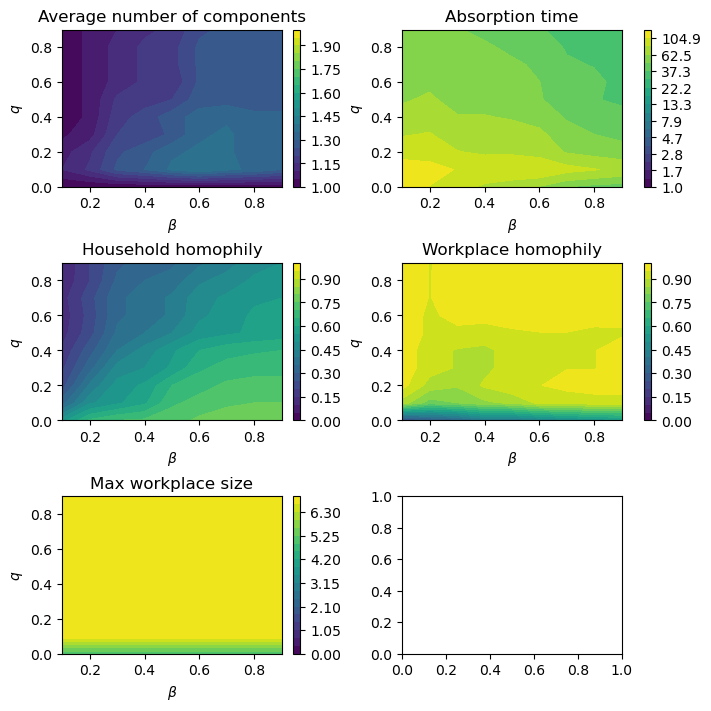

###################################
Processing h_size=20
Max workplace size: 11.0 for beta=0.2 and q=0.1
Max absorption time: 193.36 for beta=0.1 and q=0.1


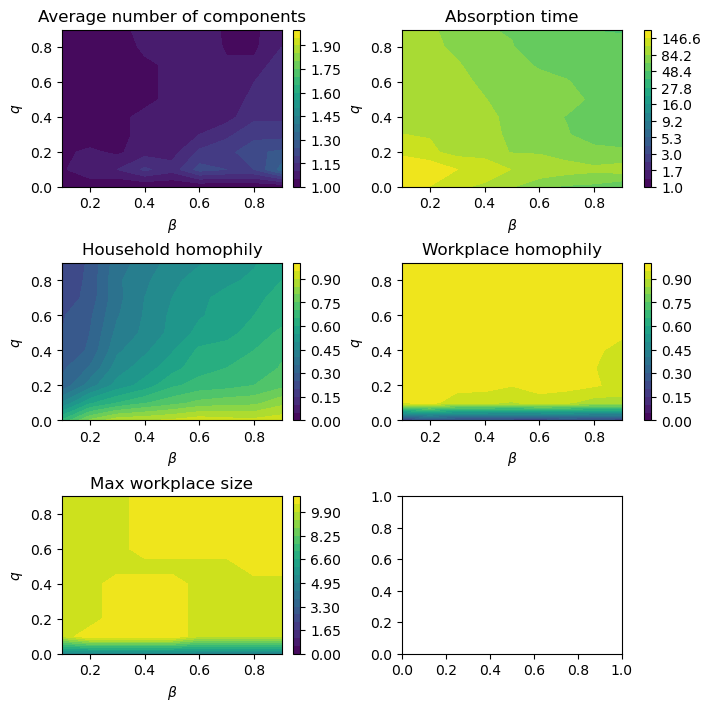

###################################
Processing h_size=30
Max workplace size: 15.0 for beta=0.4 and q=0.4
Max absorption time: 252.38 for beta=0.1 and q=0.0


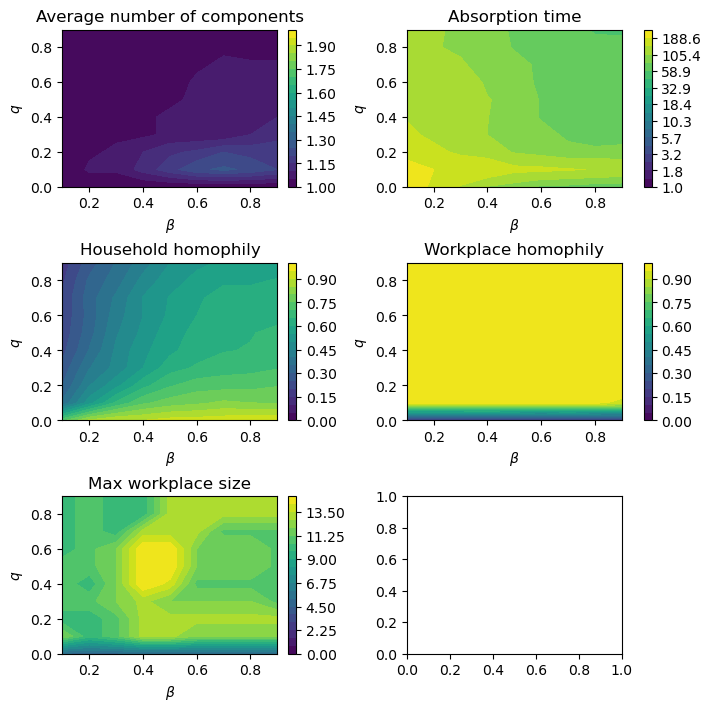

###################################
Processing h_size=100
Max workplace size: 13.0 for beta=0.4 and q=0.1
Max absorption time: 422.36 for beta=0.1 and q=0.0


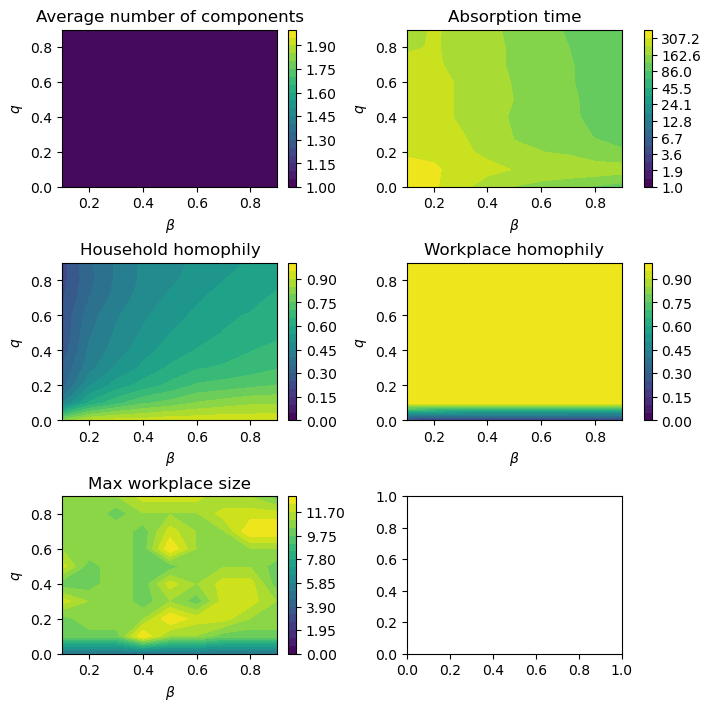

In [14]:
betas=np.arange(0.1,1,0.1)
qs=np.arange(0,1,0.1)

# Levels
levels_h = np.linspace(0, 1, 21)
levels_c = np.linspace(1, 2, 21)


row_names = ['sum_opinion_A','component_sizes','homophily', 'max_workplace_size']
for h_size in [10,20,30,100]:
    filename = f'/scratch/kolokcse/logs_hypergraph/majority_move_nonlin_long_final/long_2_regular_edgesize_5_nonlin_n_{h_size}.pickle'
    with open(filename, 'rb') as handle:
            results_dict = pickle.load(handle)

    iterations=50


    all_res_nonlin = []
    for beta_i, beta in enumerate(betas):
        all_res_nonlin.append([])
        for q_i,q in enumerate(qs):
            results={}
            for row_i,row in enumerate(row_names):
                results[row]=[]
                for i in range(iterations):
                    try:
                        results[row].append(results_dict[beta_i][q_i][i][row])
                    except:
                        print(beta_i,q_i,i,row)
            all_res_nonlin[beta_i].append(results)
            
    
    homophily_array_hh = np.zeros((len(betas),len(qs)))
    homophily_confidance_array_hh =  np.zeros((len(betas),len(qs)))
    homophily_array_wp = np.zeros((len(betas),len(qs)))
    homophily_confidance_array_wp =  np.zeros((len(betas),len(qs)))

    num_comp_array =  np.zeros((len(betas),len(qs)))
    num_comp_confidence_array = np.zeros((len(betas),len(qs)))

    end_time_array =  np.zeros((len(betas),len(qs)))
    end_time_confidance_array =  np.zeros((len(betas),len(qs)))

    max_workplace_size_array =  np.zeros((len(betas),len(qs)))

    for beta_i, beta in enumerate(betas):
        for q_i, q in enumerate(qs):
            homophily_array_hh[beta_i][q_i], homophily_confidance_array_hh[beta_i][q_i] = mean_confidence_interval([all_res_nonlin[beta_i][q_i]['homophily'][i][-1][0] for i in range(iterations)])
            homophily_array_wp[beta_i][q_i], homophily_confidance_array_wp[beta_i][q_i] = mean_confidence_interval([all_res_nonlin[beta_i][q_i]['homophily'][i][-1][1] for i in range(iterations)])           
            num_comp_array[beta_i][q_i], num_comp_confidence_array[beta_i][q_i] = mean_confidence_interval([len(all_res_nonlin[beta_i][q_i]['component_sizes'][i]) for i in range(iterations)])
            end_time_array[beta_i][q_i], end_time_confidance_array[beta_i][q_i] = mean_confidence_interval([len(all_res_nonlin[beta_i][q_i]['sum_opinion_A'][i]) for i in range(iterations)])
            max_workplace_size_array[beta_i][q_i] = np.max([all_res_nonlin[beta_i][q_i]['max_workplace_size'][i][-1] for i in range(iterations)])
            
        
            
    n = homophily_array_hh.shape[0]
    print('###################################')
    print(f"Processing h_size={h_size}")
    print(f"Max workplace size: {np.max(max_workplace_size_array)} for beta={betas[np.argmax(max_workplace_size_array)//len(qs)]} and q={qs[np.argmax(max_workplace_size_array)%len(qs)]}")
    print(f"Max absorption time: {np.max(end_time_array)} for beta={betas[np.argmax(end_time_array)//len(qs)]} and q={qs[np.argmax(end_time_array)%len(qs)]}")
    BETA, Q = np.meshgrid(betas, qs)

    fig, axes = plt.subplots(3, 2, figsize=(7,7), constrained_layout=True)


    # --- Number of components ---
    c1 = axes[0,0].contourf(
        BETA, Q, np.min([num_comp_array.T,2*np.ones(num_comp_array.T.shape)], axis=0),
        levels=levels_c, cmap="viridis"
    )
    fig.colorbar(c1, ax=axes[0,0])
    axes[0,0].set_title("Average number of components")
    axes[0,0].set_xlabel(r"$\beta$")
    axes[0,0].set_ylabel(r"$q$")

    #--Houshold homophily
    axes[1,0].set_title("Household homophily")
    c1 = axes[1,0].contourf(
        BETA, Q, homophily_array_hh.T,
        levels=levels_h, cmap="viridis"
    )
    fig.colorbar(c1, ax=axes[1,0])

    axes[1,0].set_xlabel(r"$\beta$")
    axes[1,0].set_ylabel(r"$q$")

    # --- Absorption time ---
    levels_t = np.logspace(
    np.log10(1),
    np.log10(np.max(end_time_array)),
    20
    )
    c2 = axes[0,1].contourf(
        BETA, Q, end_time_array.T,
        levels=levels_t,
        cmap="viridis",
        norm=LogNorm(vmin=levels_t[0], vmax=levels_t[-1])
    )
    fig.colorbar(c2, ax=axes[0,1])
    axes[0,1].set_title("Absorption time")
    axes[0,1].set_xlabel(r"$\beta$")
    axes[0,1].set_ylabel(r"$q$")

    c2 = axes[1,1].contourf(
        BETA, Q, homophily_array_wp.T,
        levels=levels_h,
        cmap="viridis"
    )
    fig.colorbar(c2, ax=axes[1,1])
    axes[1,1].set_title("Workplace homophily")
    axes[1,1].set_xlabel(r"$\beta$")
    axes[1,1].set_ylabel(r"$q$")
    
    axes[2,0].set_title("Max workplace size")
    c2 = axes[2,0].contourf(
        BETA, Q, max_workplace_size_array.T,
        levels=np.linspace(0, np.max(max_workplace_size_array), 21),
        cmap="viridis"
    )
    fig.colorbar(c2, ax=axes[2,0])
    axes[2,0].set_xlabel(r"$\beta$")
    axes[2,0].set_ylabel(r"$q$")

    plt.show()

Processing h_size = 10
Loading: /scratch/kolokcse/logs_hypergraph/majority_move_lin_long_final/long_2_regular_edgesize_5_lin_n_10.pickle

Summary
----------------------------------------------------------------------
Mean relative first-peak time over all parameter values: 0.347
Mean relative last-peak time over all parameter values: 0.821
Largest average trajectory maximum: 8.180 at beta=0.1, q=0.7
Latest average first appearance of the maximum: 0.513 at beta=0.1, q=0.7
Largest average overshoot: 1.820 at beta=0.1, q=0.7
Processing h_size = 20
Loading: /scratch/kolokcse/logs_hypergraph/majority_move_lin_long_final/long_2_regular_edgesize_5_lin_n_20.pickle

Summary
----------------------------------------------------------------------
Mean relative first-peak time over all parameter values: 0.393
Mean relative last-peak time over all parameter values: 0.746
Largest average trajectory maximum: 11.040 at beta=0.1, q=0.6
Latest average first appearance of the maximum: 0.560 at beta=0.7, q

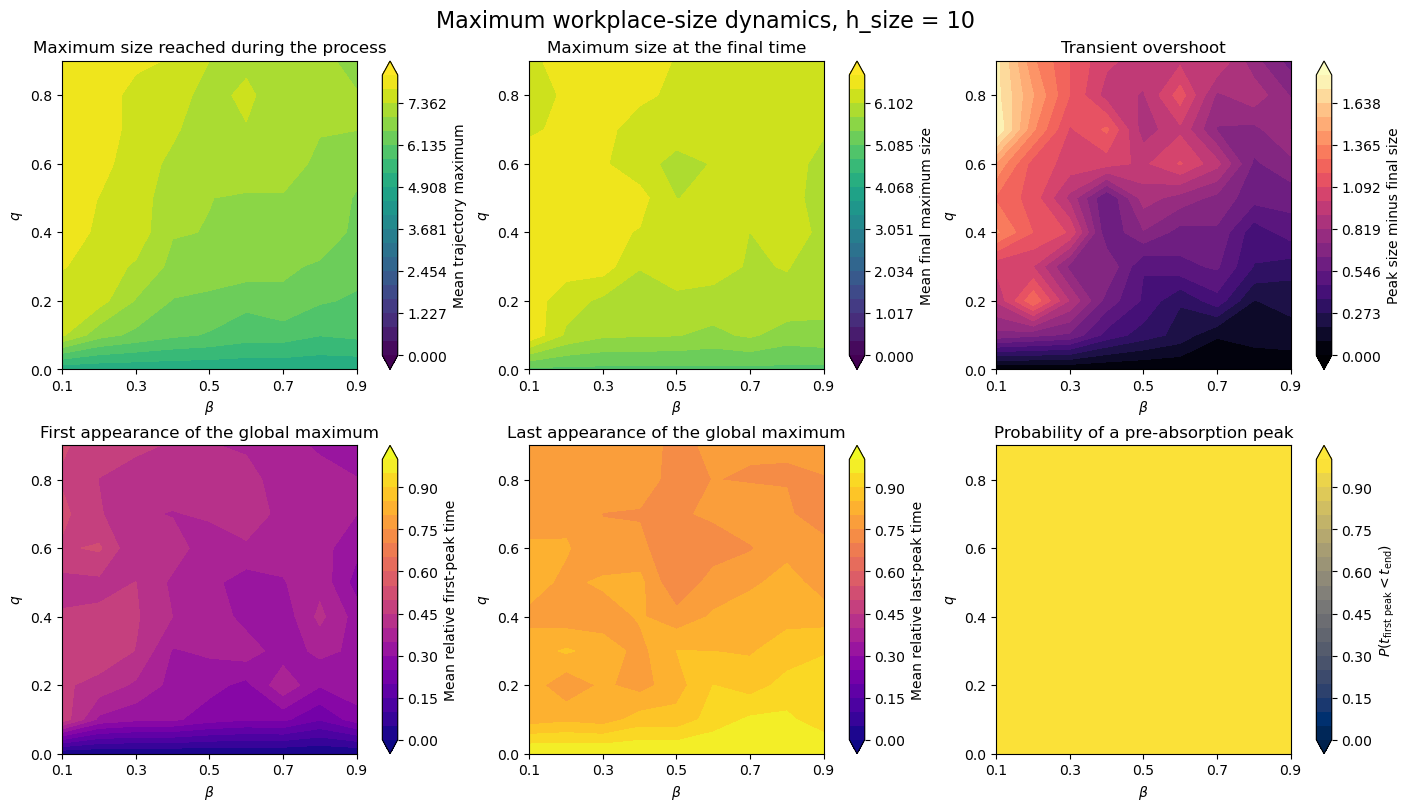

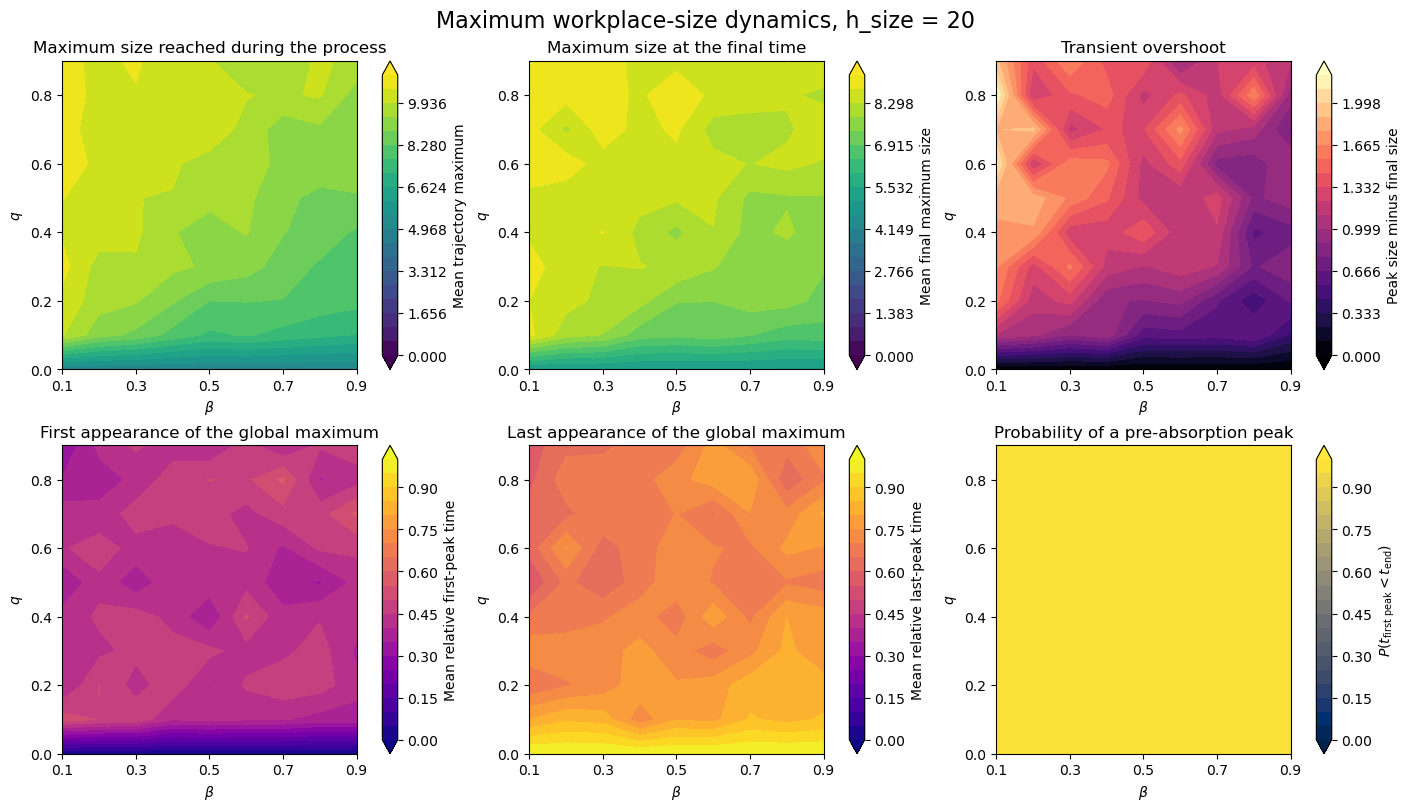

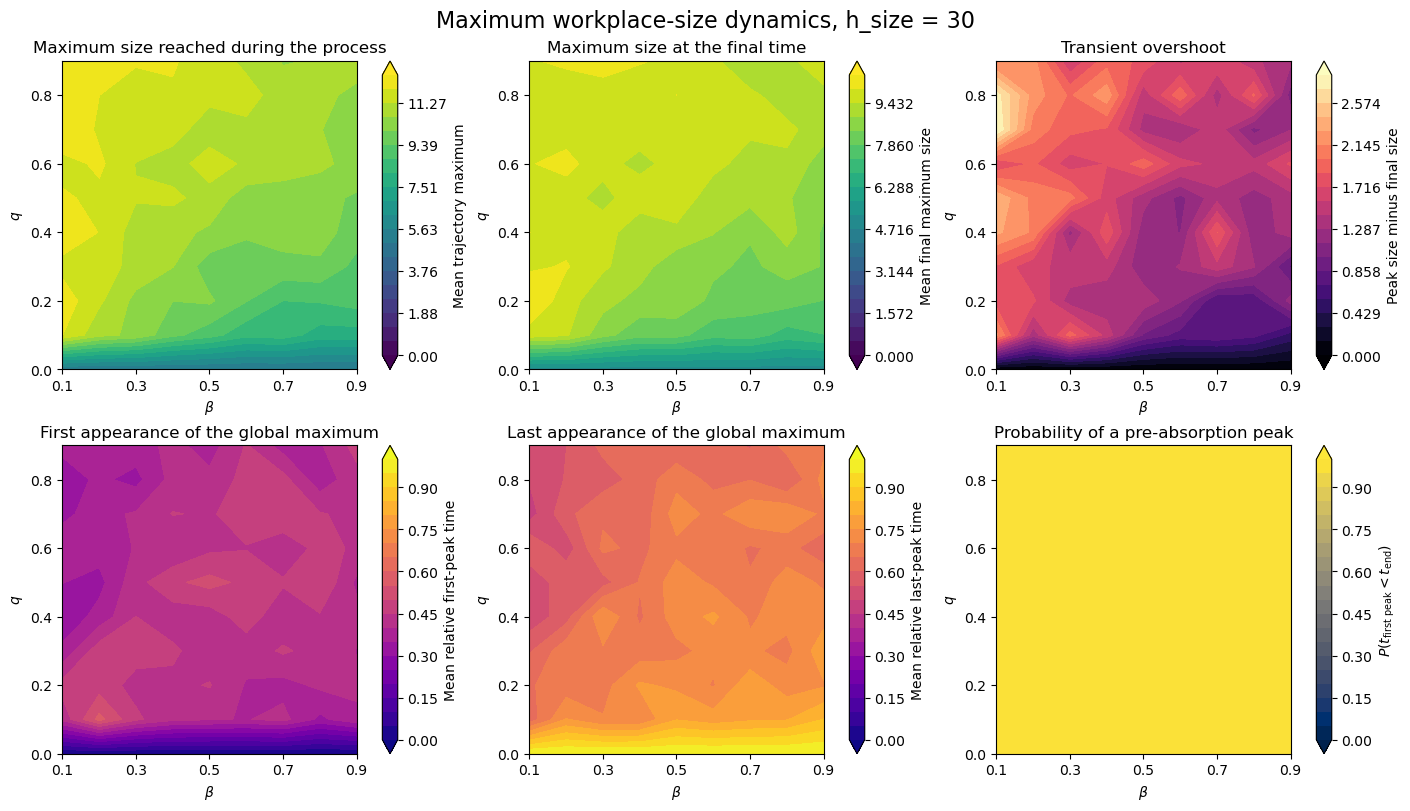

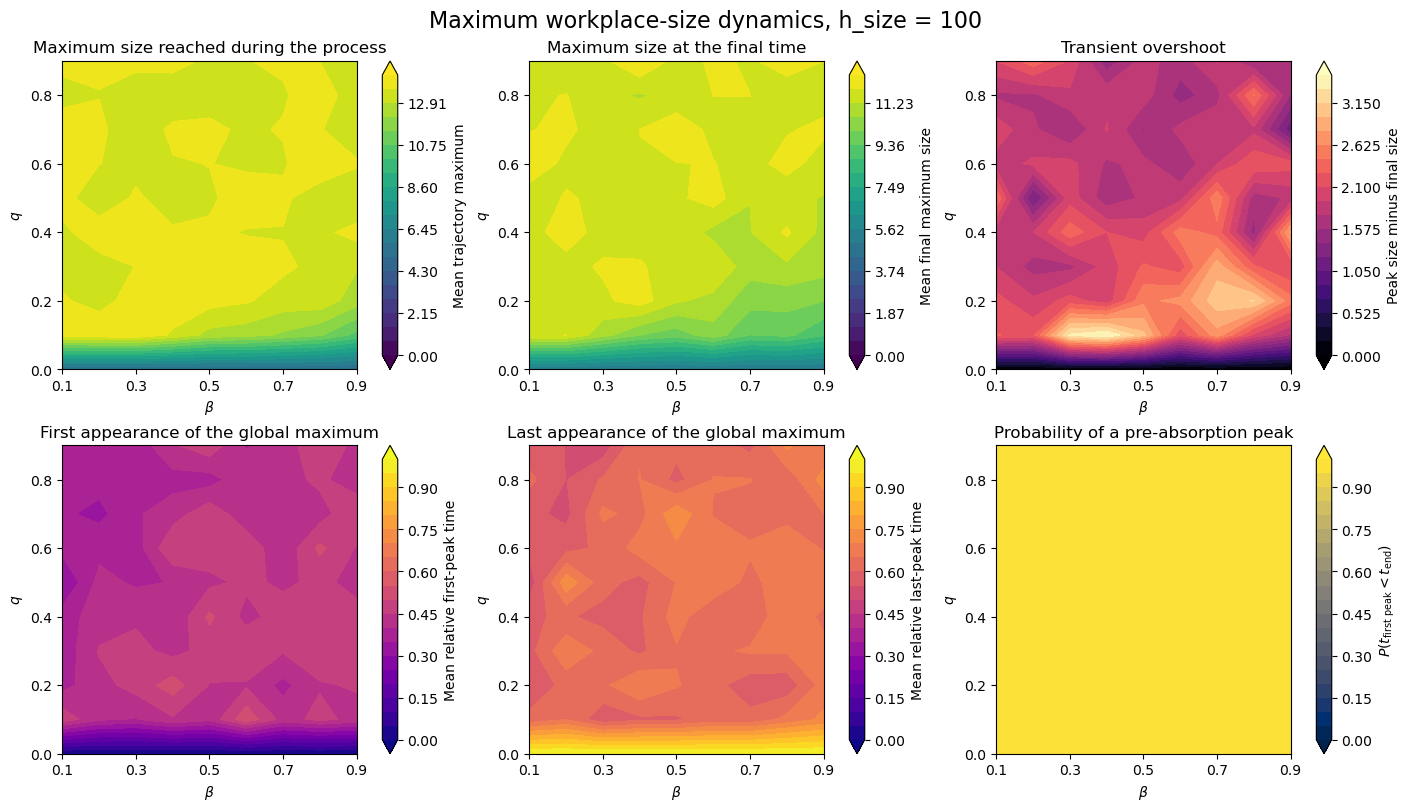

NameError: name 'rescaled_trajectories' is not defined

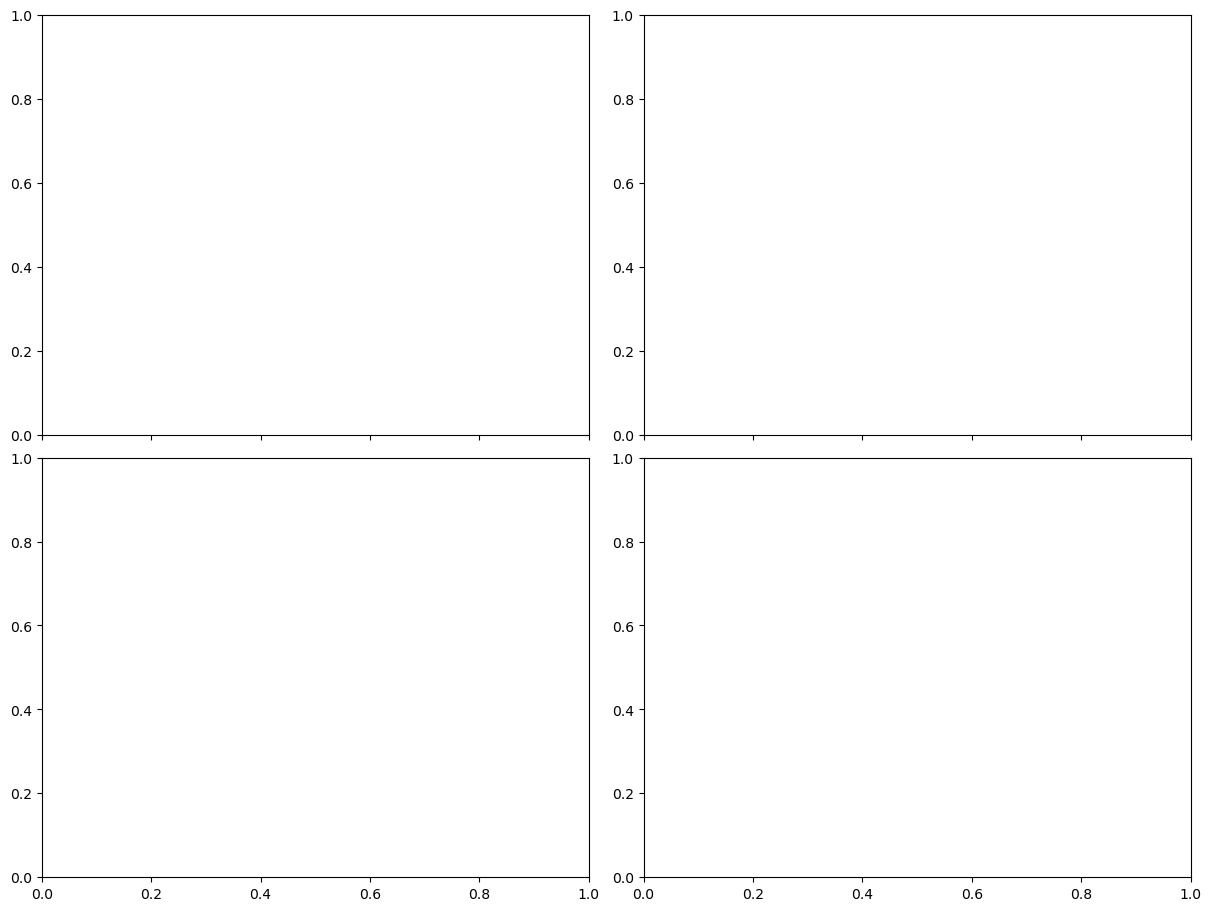

In [11]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.interpolate import interp1d


# ============================================================
# PARAMETERS
# ============================================================

betas = np.arange(0.1, 1.0, 0.1)
qs = np.arange(0.0, 1.0, 0.1)

h_sizes = [10, 20, 30, 100]
iterations = 50

base_path = (
    "/scratch/kolokcse/logs_hypergraph/"
    "majority_move_lin_long_final/"
)

# Number of points used when trajectories are rescaled to [0, 1]
n_time_points = 101
relative_time_grid = np.linspace(0.0, 1.0, n_time_points)

# Parameter combinations shown in the trajectory figures.
# These values should appear in betas and qs.
selected_parameters = [
    (0.2, 0.2),
    (0.5, 0.5),
    (0.8, 0.2),
    (0.8, 0.8),
]

# Set to True if figures should be saved as PDF and PNG.
save_figures = True


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def get_trajectory(results_dict, beta_i, q_i, iteration):
    """
    Extract and clean one max-workplace-size trajectory.

    Returns
    -------
    trajectory : one-dimensional NumPy array
        Empty array if the trajectory is missing or invalid.
    """

    try:
        trajectory = results_dict[beta_i][q_i][iteration][
            "max_workplace_size"
        ]

        trajectory = np.asarray(trajectory, dtype=float).reshape(-1)
        trajectory = trajectory[np.isfinite(trajectory)]

        return trajectory

    except (
        KeyError,
        IndexError,
        TypeError,
        ValueError,
    ):
        return np.array([], dtype=float)


def relative_peak_interval(trajectory):
    """
    Calculate the first and last relative times at which the
    global trajectory maximum is attained.

    Relative time:
        0 = beginning of the simulation
        1 = final recorded time step
    """

    trajectory = np.asarray(trajectory, dtype=float)

    if len(trajectory) == 0:
        return np.nan, np.nan

    if len(trajectory) == 1:
        return 0.0, 0.0

    peak_value = np.max(trajectory)
    peak_indices = np.flatnonzero(trajectory == peak_value)

    denominator = len(trajectory) - 1

    first_peak_time = peak_indices[0] / denominator
    last_peak_time = peak_indices[-1] / denominator

    return first_peak_time, last_peak_time


def rescale_trajectory(trajectory, target_grid):
    """
    Linearly interpolate a trajectory onto a common relative-time grid.
    """

    trajectory = np.asarray(trajectory, dtype=float)

    if len(trajectory) == 0:
        return np.full(len(target_grid), np.nan)

    if len(trajectory) == 1:
        return np.full(len(target_grid), trajectory[0])

    original_grid = np.linspace(0.0, 1.0, len(trajectory))

    interpolation = interp1d(
        original_grid,
        trajectory,
        kind="linear",
        bounds_error=False,
        fill_value=(
            trajectory[0],
            trajectory[-1],
        ),
    )

    return interpolation(target_grid)


def mean_and_confidence_interval(values, confidence_z=1.96):
    """
    Calculate the mean and an approximate 95% confidence interval.

    The returned lower and upper values are:
        mean - 1.96 * standard error
        mean + 1.96 * standard error
    """

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return np.nan, np.nan, np.nan

    mean_value = np.mean(values)

    if len(values) == 1:
        return mean_value, mean_value, mean_value

    standard_error = np.std(values, ddof=1) / np.sqrt(len(values))
    margin = confidence_z * standard_error

    return (
        mean_value,
        mean_value - margin,
        mean_value + margin,
    )


def find_parameter_index(values, target):
    """
    Return the index of a parameter value, using numerical tolerance.
    """

    matching_indices = np.flatnonzero(
        np.isclose(values, target)
    )

    if len(matching_indices) == 0:
        raise ValueError(
            f"Parameter value {target} is not present in {values}."
        )

    return matching_indices[0]


def plot_heatmap(
    ax,
    data,
    title,
    colorbar_label,
    levels=None,
    cmap="viridis",
    norm=None,
):
    """
    Plot one beta-q heatmap.
    """

    beta_grid, q_grid = np.meshgrid(betas, qs)

    contour = ax.contourf(
        beta_grid,
        q_grid,
        data.T,
        levels=levels,
        cmap=cmap,
        norm=norm,
        extend="both",
    )

    colorbar = plt.colorbar(contour, ax=ax)
    colorbar.set_label(colorbar_label)

    ax.set_title(title)
    ax.set_xlabel(r"$\beta$")
    ax.set_ylabel(r"$q$")

    ax.set_xticks(betas[::2])
    ax.set_yticks(qs[::2])

    return contour


# ============================================================
# LOAD AND ANALYZE DATA
# ============================================================

analysis_by_hsize = {}

for h_size in h_sizes:

    filename = (
        f"{base_path}"
        f"long_2_regular_edgesize_5_lin_n_{h_size}.pickle"
    )

    print("=" * 70)
    print(f"Processing h_size = {h_size}")
    print(f"Loading: {filename}")

    with open(filename, "rb") as handle:
        results_dict = pickle.load(handle)

    shape = (len(betas), len(qs))

    # Mean values over realizations
    mean_peak_size = np.full(shape, np.nan)
    mean_final_size = np.full(shape, np.nan)

    mean_first_peak_time = np.full(shape, np.nan)
    mean_last_peak_time = np.full(shape, np.nan)
    mean_absolute_peak_time = np.full(shape, np.nan)

    mean_overshoot = np.full(shape, np.nan)
    probability_peak_before_final = np.full(shape, np.nan)

    mean_absorption_time = np.full(shape, np.nan)

    # Store raw information for later figures
    trajectories = {}
    peak_time_samples = {}

    for beta_i, beta in enumerate(betas):
        for q_i, q in enumerate(qs):

            peak_sizes = []
            final_sizes = []

            first_peak_times = []
            last_peak_times = []
            absolute_peak_times = []

            overshoots = []
            peaks_before_final = []
            absorption_times = []

            current_trajectories = []

            for iteration in range(iterations):

                trajectory = get_trajectory(
                    results_dict,
                    beta_i,
                    q_i,
                    iteration,
                )

                if len(trajectory) == 0:
                    print(
                        "Missing trajectory:",
                        f"h_size={h_size},",
                        f"beta={beta:.1f},",
                        f"q={q:.1f},",
                        f"iteration={iteration}",
                    )
                    continue

                peak_size = np.max(trajectory)
                final_size = trajectory[-1]

                first_peak_index = np.flatnonzero(
                    trajectory == peak_size
                )[0]

                first_relative, last_relative = (
                    relative_peak_interval(trajectory)
                )

                peak_sizes.append(peak_size)
                final_sizes.append(final_size)

                first_peak_times.append(first_relative)
                last_peak_times.append(last_relative)
                absolute_peak_times.append(first_peak_index)

                overshoots.append(peak_size - final_size)

                peaks_before_final.append(
                    float(first_peak_index < len(trajectory) - 1)
                )

                # Number of transitions between saved states.
                absorption_times.append(len(trajectory) - 1)

                current_trajectories.append(trajectory)

            trajectories[(beta_i, q_i)] = current_trajectories
            peak_time_samples[(beta_i, q_i)] = np.asarray(
                first_peak_times,
                dtype=float,
            )

            if len(peak_sizes) == 0:
                continue

            mean_peak_size[beta_i, q_i] = np.mean(peak_sizes)
            mean_final_size[beta_i, q_i] = np.mean(final_sizes)

            mean_first_peak_time[beta_i, q_i] = np.mean(
                first_peak_times
            )

            mean_last_peak_time[beta_i, q_i] = np.mean(
                last_peak_times
            )

            mean_absolute_peak_time[beta_i, q_i] = np.mean(
                absolute_peak_times
            )

            mean_overshoot[beta_i, q_i] = np.mean(overshoots)

            probability_peak_before_final[beta_i, q_i] = np.mean(
                peaks_before_final
            )

            mean_absorption_time[beta_i, q_i] = np.mean(
                absorption_times
            )

    analysis_by_hsize[h_size] = {
        "mean_peak_size": mean_peak_size,
        "mean_final_size": mean_final_size,
        "mean_first_peak_time": mean_first_peak_time,
        "mean_last_peak_time": mean_last_peak_time,
        "mean_absolute_peak_time": mean_absolute_peak_time,
        "mean_overshoot": mean_overshoot,
        "probability_peak_before_final": (
            probability_peak_before_final
        ),
        "mean_absorption_time": mean_absorption_time,
        "trajectories": trajectories,
        "peak_time_samples": peak_time_samples,
    }

    # --------------------------------------------------------
    # PRINT SUMMARY
    # --------------------------------------------------------

    largest_peak_position = np.nanargmax(mean_peak_size)
    largest_peak_index = np.unravel_index(
        largest_peak_position,
        mean_peak_size.shape,
    )

    latest_peak_position = np.nanargmax(mean_first_peak_time)
    latest_peak_index = np.unravel_index(
        latest_peak_position,
        mean_first_peak_time.shape,
    )

    largest_overshoot_position = np.nanargmax(mean_overshoot)
    largest_overshoot_index = np.unravel_index(
        largest_overshoot_position,
        mean_overshoot.shape,
    )

    print()
    print("Summary")
    print("-" * 70)

    print(
        "Mean relative first-peak time over all parameter values:",
        f"{np.nanmean(mean_first_peak_time):.3f}",
    )

    print(
        "Mean relative last-peak time over all parameter values:",
        f"{np.nanmean(mean_last_peak_time):.3f}",
    )

    print(
        "Largest average trajectory maximum:",
        f"{mean_peak_size[largest_peak_index]:.3f}",
        f"at beta={betas[largest_peak_index[0]]:.1f},",
        f"q={qs[largest_peak_index[1]]:.1f}",
    )

    print(
        "Latest average first appearance of the maximum:",
        f"{mean_first_peak_time[latest_peak_index]:.3f}",
        f"at beta={betas[latest_peak_index[0]]:.1f},",
        f"q={qs[latest_peak_index[1]]:.1f}",
    )

    print(
        "Largest average overshoot:",
        f"{mean_overshoot[largest_overshoot_index]:.3f}",
        f"at beta={betas[largest_overshoot_index[0]]:.1f},",
        f"q={qs[largest_overshoot_index[1]]:.1f}",
    )


# ============================================================
# FIGURE 1: HEATMAP ANALYSIS
# ============================================================

for h_size in h_sizes:

    data = analysis_by_hsize[h_size]

    figure, axes = plt.subplots(
        2,
        3,
        figsize=(14, 8),
        constrained_layout=True,
    )

    # --------------------------------------------------------
    # Peak size over the complete trajectory
    # --------------------------------------------------------

    peak_maximum = np.nanmax(data["mean_peak_size"])

    plot_heatmap(
        axes[0, 0],
        data["mean_peak_size"],
        title="Maximum size reached during the process",
        colorbar_label="Mean trajectory maximum",
        levels=np.linspace(0.0, peak_maximum, 21),
    )

    # --------------------------------------------------------
    # Final size
    # --------------------------------------------------------

    final_maximum = np.nanmax(data["mean_final_size"])

    plot_heatmap(
        axes[0, 1],
        data["mean_final_size"],
        title="Maximum size at the final time",
        colorbar_label="Mean final maximum size",
        levels=np.linspace(0.0, final_maximum, 21),
    )

    # --------------------------------------------------------
    # Overshoot
    # --------------------------------------------------------

    overshoot_maximum = np.nanmax(data["mean_overshoot"])

    if overshoot_maximum == 0:
        overshoot_levels = np.linspace(0.0, 1.0, 21)
    else:
        overshoot_levels = np.linspace(
            0.0,
            overshoot_maximum,
            21,
        )

    plot_heatmap(
        axes[0, 2],
        data["mean_overshoot"],
        title="Transient overshoot",
        colorbar_label="Peak size minus final size",
        levels=overshoot_levels,
        cmap="magma",
    )

    # --------------------------------------------------------
    # Relative first peak time
    # --------------------------------------------------------

    plot_heatmap(
        axes[1, 0],
        data["mean_first_peak_time"],
        title="First appearance of the global maximum",
        colorbar_label="Mean relative first-peak time",
        levels=np.linspace(0.0, 1.0, 21),
        cmap="plasma",
    )

    # --------------------------------------------------------
    # Relative last peak time
    # --------------------------------------------------------

    plot_heatmap(
        axes[1, 1],
        data["mean_last_peak_time"],
        title="Last appearance of the global maximum",
        colorbar_label="Mean relative last-peak time",
        levels=np.linspace(0.0, 1.0, 21),
        cmap="plasma",
    )

    # --------------------------------------------------------
    # Probability that the peak is reached before final time
    # --------------------------------------------------------

    plot_heatmap(
        axes[1, 2],
        data["probability_peak_before_final"],
        title="Probability of a pre-absorption peak",
        colorbar_label=r"$P(t_{\mathrm{first\ peak}} < t_{\mathrm{end}})$",
        levels=np.linspace(0.0, 1.0, 21),
        cmap="cividis",
    )

    figure.suptitle(
        f"Maximum workplace-size dynamics, h_size = {h_size}",
        fontsize=16,
    )

    if save_figures:
        figure.savefig(
            f"max_workplace_size_heatmaps_hsize_{h_size}.pdf",
            bbox_inches="tight",
        )

        figure.savefig(
            f"max_workplace_size_heatmaps_hsize_{h_size}.png",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()


# ============================================================
# FIGURE 2: AVERAGE RESCALED TRAJECTORIES
# ============================================================

figure, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9),
    sharex=True,
    constrained_layout=True,
)

axes = axes.flatten()

colors = plt.cm.viridis(
    np.linspace(0.1, 0.9, len(selected_parameters))
)

for ax, h_size in zip(axes, h_sizes):

    data = analysis_by_hsize[h_size]

    for color, (beta, q) in zip(
        colors,
        selected_parameters,
    ):

        beta_i = find_parameter_index(betas, beta)
        q_i = find_parameter_index(qs, q)

        raw_trajectories = data["trajectories"][
            (beta_i, q_i)
        ]

        rescaled_trajectory = rescale_trajectory(
                trajectory,
                relative_time_grid,
            )
        rescaled_trajectories.append(rescaled_trajectory)

        if len(rescaled_trajectories) == 0:
            continue

        rescaled_trajectories = np.asarray(
            rescaled_trajectories
        )

        mean_trajectory = np.nanmean(
            rescaled_trajectories,
            axis=0,
        )

        if len(rescaled_trajectories) > 1:
            standard_error = np.nanstd(
                rescaled_trajectories,
                axis=0,
                ddof=1,
            ) / np.sqrt(len(rescaled_trajectories))

            lower_bound = mean_trajectory - 1.96 * standard_error
            upper_bound = mean_trajectory + 1.96 * standard_error
        else:
            lower_bound = mean_trajectory
            upper_bound = mean_trajectory

        mean_curve_peak_index = np.nanargmax(mean_trajectory)
        mean_curve_peak_time = relative_time_grid[
            mean_curve_peak_index
        ]

        ax.plot(
            relative_time_grid,
            mean_trajectory,
            color=color,
            linewidth=2,
            label=(
                rf"$\beta={beta:.1f},\ q={q:.1f}$"
                "\n"
                rf"curve peak at $t/T={mean_curve_peak_time:.2f}$"
            ),
        )

        ax.fill_between(
            relative_time_grid,
            lower_bound,
            upper_bound,
            color=color,
            alpha=0.18,
        )

        ax.scatter(
            mean_curve_peak_time,
            mean_trajectory[mean_curve_peak_index],
            color=color,
            s=45,
            edgecolor="black",
            linewidth=0.5,
            zorder=5,
        )

    ax.set_title(f"h_size = {h_size}")
    ax.set_xlabel("Relative simulation time, t/T")
    ax.set_ylabel("Maximum workplace size")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

figure.suptitle(
    "Evolution of the maximum workplace size\n"
    "Mean trajectory with approximate 95% confidence intervals",
    fontsize=16,
)

if save_figures:
    figure.savefig(
        "max_workplace_size_average_trajectories.pdf",
        bbox_inches="tight",
    )

    figure.savefig(
        "max_workplace_size_average_trajectories.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# ============================================================
# FIGURE 3: DISTRIBUTION OF FIRST-PEAK TIMES
# ============================================================

figure, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()

histogram_bins = np.linspace(0.0, 1.0, 21)

for ax, h_size in zip(axes, h_sizes):

    data = analysis_by_hsize[h_size]

    all_relative_peak_times = []

    for beta_i in range(len(betas)):
        for q_i in range(len(qs)):
            samples = data["peak_time_samples"][
                (beta_i, q_i)
            ]

            samples = samples[np.isfinite(samples)]
            all_relative_peak_times.extend(samples)

    all_relative_peak_times = np.asarray(
        all_relative_peak_times
    )

    ax.hist(
        all_relative_peak_times,
        bins=histogram_bins,
        density=True,
        color="steelblue",
        edgecolor="black",
        alpha=0.8,
    )

    mean_peak_time = np.mean(all_relative_peak_times)
    median_peak_time = np.median(all_relative_peak_times)

    ax.axvline(
        mean_peak_time,
        color="darkred",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean_peak_time:.3f}",
    )

    ax.axvline(
        median_peak_time,
        color="darkorange",
        linestyle=":",
        linewidth=2,
        label=f"Median = {median_peak_time:.3f}",
    )

    ax.set_title(f"h_size = {h_size}")
    ax.set_xlabel("Relative first-peak time")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.25)
    ax.legend()

figure.suptitle(
    "When does the maximum workplace size first appear?",
    fontsize=16,
)

if save_figures:
    figure.savefig(
        "max_workplace_size_peak_time_distributions.pdf",
        bbox_inches="tight",
    )

    figure.savefig(
        "max_workplace_size_peak_time_distributions.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()


# ============================================================
# FIGURE 4: PEAK TIME VERSUS ABSORPTION TIME
# ============================================================

figure, axes = plt.subplots(
    2,
    2,
    figsize=(11, 9),
    sharex=False,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()

for ax, h_size in zip(axes, h_sizes):

    data = analysis_by_hsize[h_size]

    x_values = data["mean_absorption_time"].reshape(-1)
    y_values = data["mean_first_peak_time"].reshape(-1)

    valid = (
        np.isfinite(x_values)
        & np.isfinite(y_values)
        & (x_values > 0)
    )

    x_values = x_values[valid]
    y_values = y_values[valid]

    color_values = np.repeat(
        betas,
        len(qs),
    )[valid]

    scatter = ax.scatter(
        x_values,
        y_values,
        c=color_values,
        cmap="viridis",
        s=50,
        alpha=0.8,
        edgecolor="black",
        linewidth=0.4,
    )

    if len(x_values) > 1:
        correlation = np.corrcoef(
            np.log10(x_values),
            y_values,
        )[0, 1]
    else:
        correlation = np.nan

    ax.set_xscale("log")
    ax.set_ylim(-0.03, 1.03)

    ax.set_title(
        f"h_size = {h_size}, "
        rf"$r(\log_{{10}}T, t_{{peak}}/T)={correlation:.2f}$"
    )

    ax.set_xlabel("Mean absorption time")
    ax.set_ylabel("Mean relative first-peak time")
    ax.grid(alpha=0.25)

    colorbar = plt.colorbar(scatter, ax=ax)
    colorbar.set_label(r"$\beta$")

figure.suptitle(
    "Is late peak formation associated with long absorption times?",
    fontsize=16,
)

if save_figures:
    figure.savefig(
        "max_workplace_size_peak_vs_absorption.pdf",
        bbox_inches="tight",
    )

    figure.savefig(
        "max_workplace_size_peak_vs_absorption.png",
        dpi=300,
        bbox_inches="tight",
    )

plt.show()